#Loading Data

In [ ]:
import os
import shutil
import pandas as pd
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import make_column_transformer
from google.colab import drive

# 1. Conecta o seu Google Drive ao Colab
drive.mount('/content/drive')

# 2. Define os caminhos do projeto
caminho_base = "/content/drive/MyDrive/Projeto_Churn_RN"
caminho_csv = os.path.join(caminho_base, "datasets", "customer_churn_telecom_services.csv")

# Define as subpastas estratégicas para o projeto
pastas = [
    "",             # Cria a pasta raiz do projeto
    "datasets",     # Para guardar o CSV
    "modelos",      # Para salvar os pesos da rede (.pth) do campeão
    "modelos/MLP_Entrega",  # Para salvar os pesos do MLP
    "logs",         # Para salvar os históricos de KS e Loss dos testes manuais
    "logs/MLP_Entrega"      # Para salvar os logs do MLP
]

# Cria cada uma das pastas (exist_ok=True garante que não dará erro se já existirem)
for pasta in pastas:
    caminho_completo = os.path.join(caminho_base, pasta)
    os.makedirs(caminho_completo, exist_ok=True)

print("Estrutura de pastas verificada/criada com sucesso!")

# 3. Tenta ler o arquivo ou faz o download
try:
    # Tenta carregar o arquivo direto da pasta datasets no seu Google Drive
    print("Tentando carregar arquivo do Google Drive...")
    df = pd.read_csv(caminho_csv)
    print("Sucesso! Dataset carregado do Drive.")

except FileNotFoundError:
    !pip install kagglehub -q
    import kagglehub
    # Se não existir no Drive, baixa do Kaggle
    print("Arquivo não encontrado no Drive. Iniciando download via kagglehub...")
    path = kagglehub.dataset_download("kapturovalexander/customers-churned-in-telecom-services")

    arquivos_csv = [f for f in os.listdir(path) if f.endswith('.csv')]

    if arquivos_csv:
        caminho_baixado = os.path.join(path, arquivos_csv[0])

        # Copia o arquivo baixado para o seu Google Drive com o nome correto
        shutil.copy(caminho_baixado, caminho_csv)
        print(f"Dataset salvo permanentemente no Drive em: {caminho_csv}")

        # Carrega o DataFrame
        df = pd.read_csv(caminho_csv)
        print("Sucesso! Dataset carregado na memória.")
    else:
        print("Nenhum arquivo CSV encontrado no dataset baixado.")

# Visualizando as primeiras linhas
display(df.head())

Mounted at /content/drive
Estrutura de pastas verificada/criada com sucesso!
Tentando carregar arquivo do Google Drive...
Sucesso! Dataset carregado do Drive.


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


#EDA

In [ ]:
# Remoção de registros duplicados exatos no início do EDA (antes do tratamento de nulos e do split)
# keep='first' mantém a 1ª ocorrência ('original') e remove apenas as 22 cópias repetidas
qtd_duplicatas = df.duplicated().sum()
print(f"Linhas antes da remoção de duplicatas: {len(df)} | Duplicatas exatas encontradas: {qtd_duplicatas}")
df = df.drop_duplicates(keep='first').reset_index(drop=True)
print(f"Linhas após manter apenas as ocorrências originais: {len(df)}")

In [ ]:
df.shape

(7043, 20)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [ ]:
df.isnull().sum().sum()

np.int64(11)

In [ ]:
df.isnull().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


In [ ]:
df[df['TotalCharges'].isnull()]

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [ ]:
df[df['tenure'] <= 0]

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [ ]:
# Preenchendo valores ausentes em 'TotalCharges' com 0 (clientes novos, tenure = 0)
df['TotalCharges'] = df['TotalCharges'].fillna(0)
print("Total de nulos após o preenchimento:", df.isnull().sum().sum())

Total de nulos após o preenchimento: 0


In [ ]:
fig = px.histogram(df, x='Churn', text_auto=True, width=1000, height=400)
fig.show()

In [ ]:
# Identificando as colunas categóricas (do tipo 'object')
colunas_categoricas = df.select_dtypes(include=['object']).columns.tolist()
colunas_categoricas.append('SeniorCitizen')
print("Colunas categóricas:", colunas_categoricas)

Colunas categóricas: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn', 'SeniorCitizen']


In [ ]:
for col in colunas_categoricas:
    if col != 'Churn':
        fig = px.histogram(
            df,
            x=col,
            text_auto=True,
            color='Churn',
            barmode='group',
            width=1000,
            height=400,
            title=f'Distribuição de {col} por Churn'
        )
        fig.show()

In [ ]:
# Identificando as colunas numéricas
numerics = ['int16', 'int32', 'int64', 'float16', 'float32', 'float64']
colunas_numericas = df.select_dtypes(include=numerics).columns.tolist()
print("Colunas numéricas:", colunas_numericas)

Colunas numéricas: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [ ]:
for col in colunas_numericas:
    if col != 'SeniorCitizen':
      fig = px.box(
          df,
          x=col,
          color='Churn',
          width=1000,
          height=400,
          title=f'Distribuição de {col} por Churn'
      )
      fig.show()

#Split

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle

def realizar_split(df_input):
    """Apenas divide os dados em Treino, Validação e Teste (50/25/25) separando por classes para manter a proporção."""
    # PASSO 1: Separação por Classes
    df_class0 = df_input[df_input['Churn'] == 'No']  # Classe 1: Majoritária
    df_class1 = df_input[df_input['Churn'] == 'Yes'] # Classe 2: Minoritária

    # PASSO 2: Divisão Primária (50% Treino, 25% Validação, 25% Teste)
    train_0, temp_0 = train_test_split(df_class0, test_size=0.5, random_state=42)
    val_0, test_0 = train_test_split(temp_0, test_size=0.5, random_state=42)

    train_1, temp_1 = train_test_split(df_class1, test_size=0.5, random_state=42)
    val_1, test_1 = train_test_split(temp_1, test_size=0.5, random_state=42)

    # PASSO 3: Concatenar e Aleatorizar
    df_train_out = shuffle(pd.concat([train_0, train_1]), random_state=42)
    df_val_out = shuffle(pd.concat([val_0, val_1]), random_state=42)
    df_test_out = shuffle(pd.concat([test_0, test_1]), random_state=42)

    return df_train_out, df_val_out, df_test_out

# Chamando a função de Split
df_train, df_val, df_test = realizar_split(df)

# Exibindo os resultados das distribuições parciais
print("--- DISTRIBUIÇÃO APÓS O SPLIT (ANTES DO BALANCEAMENTO) ---")
print(f"TREINO    -> Total: {len(df_train)} | No Churn: {sum(df_train['Churn']=='No')} | Churn: {sum(df_train['Churn']=='Yes')}")
print(f"VALIDAÇÃO -> Total: {len(df_val)} | No Churn: {sum(df_val['Churn']=='No')} | Churn: {sum(df_val['Churn']=='Yes')}")
print(f"TESTE     -> Total: {len(df_test)} | No Churn: {sum(df_test['Churn']=='No')} | Churn: {sum(df_test['Churn']=='Yes')}")

--- DISTRIBUIÇÃO APÓS O SPLIT (ANTES DO BALANCEAMENTO) ---
TREINO    -> Total: 3521 | No Churn: 2587 | Churn: 934
VALIDAÇÃO -> Total: 1760 | No Churn: 1293 | Churn: 467
TESTE     -> Total: 1762 | No Churn: 1294 | Churn: 468


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.utils import shuffle

def aplicar_pipeline_e_oversampling(df_train_in, df_val_in, df_test_in, cols_cat, cols_num):
    # 1. Separar Variáveis Independentes (X) do Alvo (y) e converter alvo para 0 e 1
    X_tr = df_train_in.drop('Churn', axis=1)
    y_tr = df_train_in['Churn'].map({'No': 0, 'Yes': 1})

    X_v = df_val_in.drop('Churn', axis=1)
    y_v = df_val_in['Churn'].map({'No': 0, 'Yes': 1})

    X_te = df_test_in.drop('Churn', axis=1)
    y_te = df_test_in['Churn'].map({'No': 0, 'Yes': 1})

    # 2. Organizar quais colunas são o que (excluindo a coluna alvo)
    cat_c = [col for col in cols_cat if col != 'Churn']
    num_c = [col for col in cols_num if col != 'SeniorCitizen'] # SeniorCitizen já está em cat_cols

    # 3. Criar o Pipeline de Transformação
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', MinMaxScaler(), num_c),
            ('cat', OneHotEncoder(drop='if_binary', sparse_output=False), cat_c)
        ],
        remainder='passthrough',
        verbose_feature_names_out=False
    )

    # 4. NORMALIZAÇÃO E ENCODING ANTES DO OVERSAMPLING
    X_tr_enc = preprocessor.fit_transform(X_tr)
    X_v_enc = preprocessor.transform(X_v)
    X_te_enc = preprocessor.transform(X_te)

    nomes_colunas = preprocessor.get_feature_names_out()

    # Converter para DataFrames temporários
    X_tr_df = pd.DataFrame(X_tr_enc, columns=nomes_colunas, index=X_tr.index)
    X_v_df = pd.DataFrame(X_v_enc, columns=nomes_colunas, index=X_v.index)
    X_te_df = pd.DataFrame(X_te_enc, columns=nomes_colunas, index=X_te.index)

    # Juntar X e y para o oversampling
    train_full = pd.concat([X_tr_df, y_tr], axis=1)
    val_full = pd.concat([X_v_df, y_v], axis=1)

    # 5. OVERSAMPLING MANUAL (Após Normalização)
    def balancear(df_dados):
        df_0 = df_dados[df_dados['Churn'] == 0]
        df_1 = df_dados[df_dados['Churn'] == 1]
        diff = len(df_0) - len(df_1)
        if diff > 0:
            df_1_over = df_1.sample(n=diff, replace=True, random_state=42)
            return shuffle(pd.concat([df_0, df_1, df_1_over]), random_state=42)
        return df_dados

    train_bal = balancear(train_full)
    val_bal = balancear(val_full)

    # 6. Separar X e y novamente
    X_tr_final = train_bal.drop('Churn', axis=1)
    y_tr_final = train_bal['Churn']

    X_v_final = val_bal.drop('Churn', axis=1)
    y_v_final = val_bal['Churn']

    return X_tr_final, y_tr_final, X_v_final, y_v_final, X_te_df, y_te

# Aplicando a função para gerar os datasets processados e balanceados
X_train_final, y_train, X_val_final, y_val, X_test_final, y_test = aplicar_pipeline_e_oversampling(
    df_train, df_val, df_test, colunas_categoricas, colunas_numericas
)

print("Normalização -> One-Hot -> Oversampling concluídos na ordem correta!")
print(f"Tamanho final das features de treino: {X_train_final.shape}")

print("\n--- DISTRIBUIÇÃO APÓS O OVERSAMPLING ---")
print(f"TREINO    -> Total: {len(y_train)} | No Churn (0): {sum(y_train==0)} | Churn (1): {sum(y_train==1)}")
print(f"VALIDAÇÃO -> Total: {len(y_val)} | No Churn (0): {sum(y_val==0)} | Churn (1): {sum(y_val==1)}")
print(f"TESTE     -> Total: {len(y_test)} | No Churn (0): {sum(y_test==0)} | Churn (1): {sum(y_test==1)}")

# Exibindo o resultado final
display(X_train_final.head())

Normalização -> One-Hot -> Oversampling concluídos na ordem correta!
Tamanho final das features de treino: (5174, 40)

--- DISTRIBUIÇÃO APÓS O OVERSAMPLING ---
TREINO    -> Total: 5174 | No Churn (0): 2587 | Churn (1): 2587
VALIDAÇÃO -> Total: 2586 | No Churn (0): 1293 | Churn (1): 1293
TESTE     -> Total: 1762 | No Churn (0): 1294 | Churn (1): 468


,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,SeniorCitizen_1
5051,0.777778,0.878024,0.679342,1.0,0.0,0.0,1.0,0.0,0.0,1.0,...,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4377,0.305556,0.622480,0.200064,0.0,1.0,0.0,1.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
3089,0.944444,0.647177,0.662008,0.0,0.0,0.0,1.0,1.0,0.0,0.0,...,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0
1026,0.111111,0.830141,0.096067,1.0,0.0,0.0,1.0,0.0,0.0,1.0,...,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
1858,0.263889,0.553931,0.168955,0.0,1.0,0.0,1.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


#Seed Function

In [ ]:
import random

def fixar_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

#MLP

In [ ]:
import os
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import metrics
!pip install scikit-plot -q

# Correção para o erro de importação do scikit-plot com versões recentes do scipy
import scipy
scipy.interp = np.interp

import scikitplot as skplt
from scipy.stats import ks_2samp
from tqdm import tqdm
from torch.utils.data import TensorDataset, DataLoader

# Configurando o device (GPU se disponível)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device configurado para: {device}")

# Caminhos para salvamento no Drive (já criados no seu código anterior)
caminho_modelos = "/content/drive/MyDrive/Projeto_Churn_RN/modelos/MLP_Entrega"
caminho_logs = "/content/drive/MyDrive/Projeto_Churn_RN/logs/MLP_Entrega"

# Garantir que as pastas existam
os.makedirs(caminho_modelos, exist_ok=True)
os.makedirs(caminho_logs, exist_ok=True)

def get_scores_churn(targets, probs_1, threshold=0.5):
    """Calcula as métricas para um dado threshold, e também extrai o threshold ótimo do KS"""
    predictions = (probs_1 >= threshold).astype(int)

    # Separa probabilidades de quem deu churn (1) e de quem não deu (0)
    probs_0_class = probs_1[targets == 0]
    probs_1_class = probs_1[targets == 1]

    # Cálculo numérico do KS
    if len(probs_0_class) > 0 and len(probs_1_class) > 0:
        ks_stat, _ = ks_2samp(probs_0_class, probs_1_class)
    else:
        ks_stat = 0.0

    # Encontrar threshold ótimo do KS (max TPR - FPR)
    if len(np.unique(targets)) > 1:
        fpr, tpr, thresholds = metrics.roc_curve(targets, probs_1)
        optimal_idx = np.argmax(tpr - fpr)
        optimal_threshold = thresholds[optimal_idx]
    else:
        optimal_threshold = 0.5

    return {
        "accuracy": metrics.accuracy_score(targets, predictions),
        "precision": metrics.precision_score(targets, predictions, zero_division=0),
        "recall": metrics.recall_score(targets, predictions, zero_division=0),
        "f1_score": metrics.f1_score(targets, predictions, zero_division=0),
        "roc_auc": metrics.roc_auc_score(targets, probs_1) if len(np.unique(targets)) > 1 else 0.0,
        "ks_stat": ks_stat,
        "optimal_threshold": optimal_threshold
    }

Device configurado para: cuda


##Define MLP Class

In [ ]:
class MLP_Churn(nn.Module):
    def __init__(self, input_size, hidden_layers, activation_function, dropout_rate):
        super(MLP_Churn, self).__init__()

        layers = []
        tamanho_atual = input_size

        for neuronios in hidden_layers:
            layers.append(nn.Linear(tamanho_atual, neuronios))
            layers.append(activation_function())
            if dropout_rate > 0:
                layers.append(nn.Dropout(dropout_rate))
            tamanho_atual = neuronios

        # Camada de saída única para Classificação Binária
        layers.append(nn.Linear(tamanho_atual, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x) # Retorna logits (sem sigmoid aplicada ainda)

##Training Function

In [ ]:
import time

def executar_experimento_churn(name_experiment, input_size, hidden_layers, learning_rate, batch_size, num_epochs,
                               activation_function, loss_name, optimizer_name, weight_decay, dropout_rate,
                               X_train, y_train, X_val, y_val):
    start_time = time.time()
    fixar_seed(42)
    print(f"\n{'-'*70}")
    print(f"EXPERIMENTO: {name_experiment} | Camadas: {hidden_layers} | LR: {learning_rate} | Batch: {batch_size}")

    # 1. Criação dinâmica dos DataLoaders (permite variar o batch_size entre testes)
    train_dataset = TensorDataset(torch.tensor(X_train.values, dtype=torch.float32),
                                  torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1))
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

    val_dataset = TensorDataset(torch.tensor(X_val.values, dtype=torch.float32),
                                torch.tensor(y_val.values, dtype=torch.float32).view(-1, 1))
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

    # 2. Instanciando o Modelo
    mlp = MLP_Churn(input_size=input_size, hidden_layers=hidden_layers,
                    activation_function=activation_function, dropout_rate=dropout_rate).to(device)

    # 3. Otimizador e Loss
    if optimizer_name == 'Adam':
        optimizer = torch.optim.Adam(mlp.parameters(), lr=learning_rate, weight_decay=weight_decay)
    elif optimizer_name == 'SGD':
        optimizer = torch.optim.SGD(mlp.parameters(), lr=learning_rate)
    elif optimizer_name == 'RMSprop':
        optimizer = torch.optim.RMSprop(mlp.parameters(), lr=learning_rate, weight_decay=weight_decay)
    elif optimizer_name == 'Adadelta':
        optimizer = torch.optim.Adadelta(mlp.parameters(), weight_decay=weight_decay)

    if loss_name == 'CrossEntropy':
        loss_function = nn.BCEWithLogitsLoss() # Função robusta para 1 saída (aplica Sigmoid internamente)
    elif loss_name == 'MSE':
        loss_function = nn.MSELoss()

    best_ks = 0.0
    best_loss_at_best_ks = float('inf') # Guardamos apenas para fins de log ao final
    patience = 20 # Tolerância de 20 épocas para o Early Stopping
    patience_counter = 0

    # 4. Loop de Treino
    for epoch in tqdm(range(num_epochs), desc="Treinando"):
        mlp.train()
        epoch_loss = 0.0

        for features, labels in train_loader:
            features, labels = features.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = mlp(features)

            if loss_name == 'MSE':
                outputs_for_loss = torch.sigmoid(outputs)
            else:
                outputs_for_loss = outputs

            loss = loss_function(outputs_for_loss, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        # 5. Validação
        mlp.eval()
        val_loss = 0.0
        probs_list, labels_list = [], []

        with torch.no_grad():
            for features, labels in val_loader:
                features, labels = features.to(device), labels.to(device)
                outputs = mlp(features)

                if loss_name == 'MSE':
                    outputs_for_loss = torch.sigmoid(outputs)
                else:
                    outputs_for_loss = outputs

                loss = loss_function(outputs_for_loss, labels)
                val_loss += loss.item()

                probs = torch.sigmoid(outputs)
                probs_list.extend(probs.cpu().numpy())
                labels_list.extend(labels.cpu().numpy())

        val_loss /= len(val_loader)
        scores = get_scores_churn(np.array(labels_list).flatten(), np.array(probs_list).flatten())
        val_ks = scores['ks_stat']

        # 6. Early Stopping (Foco exclusivo no KS)
        if val_ks > best_ks:
            best_ks = val_ks
            best_loss_at_best_ks = val_loss
            patience_counter = 0

            caminho_arquivo = os.path.join(caminho_modelos, f'{name_experiment}.pth')
            torch.save(mlp.state_dict(), caminho_arquivo)
        else:
            patience_counter += 1
            if patience_counter >= patience:
                tqdm.write(f" -> Early stopping acionado na época {epoch+1}")
                break

    end_time = time.time()
    tempo_execucao = end_time - start_time
    print(f"Resultado Final - Val Loss: {best_loss_at_best_ks:.4f} | Melhor KS: {best_ks:.4f} | Tempo: {tempo_execucao:.2f}s")

    return {
        'nome': name_experiment,
        'val_loss': best_loss_at_best_ks,
        'val_ks': best_ks,
        'input_size': input_size,
        'hidden_layers': hidden_layers,
        'learning_rate': learning_rate,
        'batch_size': batch_size,
        'num_epochs': num_epochs,
        'activation_function': activation_function.__name__,
        'loss_name': loss_name,
        'optimizer_name': optimizer_name,
        'weight_decay': weight_decay,
        'dropout_rate': dropout_rate,
        'tempo_execucao': tempo_execucao
    }


##Winner Plot Function

In [ ]:
def plotar_vencedor_churn(resultados_do_bloco, input_size, X_val, y_val, activation_function=nn.ReLU):
    # Elege o vencedor baseado no MAIOR KS
    vencedor = max(resultados_do_bloco, key=lambda x: x['val_ks'])
    print(f"\n{'='*60}")
    print(f"VENCEDOR DA BATERIA: {vencedor['nome']} (KS Máximo: {vencedor['val_ks']:.4f})")
    print(f"{'='*60}")

    # Cria DataLoader só para esta avaliação final
    val_dataset = TensorDataset(torch.tensor(X_val.values, dtype=torch.float32),
                                torch.tensor(y_val.values, dtype=torch.float32).view(-1, 1))
    val_loader = DataLoader(val_dataset, batch_size=vencedor['batch_size'], shuffle=False)

    # Carrega a melhor rede salva no Drive
    modelo = MLP_Churn(input_size, vencedor['hidden_layers'], activation_function, vencedor['dropout_rate'])
    caminho_arquivo = os.path.join(caminho_modelos, f"{vencedor['nome']}.pth")
    # Adicionando map_location=device para permitir carregamento em CPU
    modelo.load_state_dict(torch.load(caminho_arquivo, map_location=device))
    modelo.to(device).eval()

    probs_list, labels_list = [], []
    with torch.no_grad():
        for features, labels in val_loader:
            features, labels = features.to(device), labels.to(device)
            probs = torch.sigmoid(modelo(features))
            probs_list.extend(probs.cpu().numpy())
            labels_list.extend(labels.cpu().numpy())

    y_true = np.array(labels_list).flatten()
    probs_1 = np.array(probs_list).flatten()

    # Obtém scores e o limiar ótimo
    scores_default = get_scores_churn(y_true, probs_1, threshold=0.5)
    optimal_threshold = scores_default['optimal_threshold']
    scores_optimal = get_scores_churn(y_true, probs_1, threshold=optimal_threshold)

    # Formatação para o scikit-plot [Prob Classe 0, Prob Classe 1]
    probs_0 = 1 - probs_1
    y_pred_scores = np.column_stack((probs_0, probs_1))

    y_pred_class_default = (probs_1 >= 0.5).astype(int)
    y_pred_class_optimal = (probs_1 >= optimal_threshold).astype(int)

    import seaborn as sns
    from sklearn.metrics import RocCurveDisplay, confusion_matrix, classification_report

    # Plotagens (4 subplots)
    fig, axes = plt.subplots(1, 4, figsize=(22, 5))

    # 1. KS Plot
    skplt.metrics.plot_ks_statistic(y_true, y_pred_scores, ax=axes[0], title=f"KS: {vencedor['nome']}")

    # 2. ROC Curve
    RocCurveDisplay.from_predictions(y_true, probs_1, ax=axes[1], name=vencedor['nome'])
    axes[1].set_title(f"Curva ROC: {vencedor['nome']}")
    axes[1].plot([0, 1], [0, 1], 'k--', label='Aleatório')
    axes[1].legend()

    # 3. Matriz de Confusão (0.5)
    cm_default = confusion_matrix(y_true, y_pred_class_default, normalize='true')
    sns.heatmap(cm_default, annot=True, fmt=".2%", cmap="Blues", ax=axes[2],
                xticklabels=['Não Churn (0)', 'Churn (1)'],
                yticklabels=['Não Churn (0)', 'Churn (1)'])
    axes[2].set_title("Matriz de Confusão (Thr: 0.500)")
    axes[2].set_ylabel("Valor Real")
    axes[2].set_xlabel("Predição")

    # 4. Matriz de Confusão (KS Ótimo)
    cm_optimal = confusion_matrix(y_true, y_pred_class_optimal, normalize='true')
    sns.heatmap(cm_optimal, annot=True, fmt=".2%", cmap="Greens", ax=axes[3],
                xticklabels=['Não Churn (0)', 'Churn (1)'],
                yticklabels=['Não Churn (0)', 'Churn (1)'])
    axes[3].set_title(f"Matriz de Confusão (Thr KS: {optimal_threshold:.3f})")
    axes[3].set_ylabel("Valor Real")
    axes[3].set_xlabel("Predição")

    plt.tight_layout()
    plt.show()

    # Log de métricas
    print(f"--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---")
    print(f"KS: {scores_default['ks_stat']:.4f} | AUROC: {scores_default['roc_auc']:.4f} | Acurácia: {scores_default['accuracy']:.4f}")
    print(f"Precisão: {scores_default['precision']:.4f} | Recall: {scores_default['recall']:.4f} | F1-Score: {scores_default['f1_score']:.4f}\n")
    print("Relatório de Classificação (Threshold Padrão):")
    print(classification_report(y_true, y_pred_class_default, target_names=['Não Churn (0)', 'Churn (1)']))

    print(f"\n--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS ({optimal_threshold:.3f}) ---")
    print(f"KS: {scores_optimal['ks_stat']:.4f} | AUROC: {scores_optimal['roc_auc']:.4f} | Acurácia: {scores_optimal['accuracy']:.4f}")
    print(f"Precisão: {scores_optimal['precision']:.4f} | Recall: {scores_optimal['recall']:.4f} | F1-Score: {scores_optimal['f1_score']:.4f}\n")
    print("Relatório de Classificação (Threshold Otimizado):")
    print(classification_report(y_true, y_pred_class_optimal, target_names=['Não Churn (0)', 'Churn (1)']))

    return vencedor

## Plotando a Evolução dos Parâmetros
Esta função compara o KS e a Acurácia ao longo de todos os valores testados para um determinado hiperparâmetro.

In [ ]:
def plotar_evolucao_parametros(df_resultados, parametro_x):
    """Plota um gráfico de barras com a evolução do KS para os parâmetros testados."""
    df_plot = df_resultados.copy()

    # Converte a coluna do parâmetro para string
    df_plot[f'{parametro_x}_str'] = df_plot[parametro_x].astype(str)

    plt.figure(figsize=(10, 5))

    # Definindo as cores: verde para o maior KS, azul para os demais
    max_ks = df_plot['val_ks'].max()
    cores = ['green' if ks == max_ks else 'blue' for ks in df_plot['val_ks']]

    # Gráfico de barras com Seaborn
    ax = sns.barplot(data=df_plot, x=f'{parametro_x}_str', y='val_ks', palette=cores)

    # Adicionando os valores em cima de cada barra
    for p in ax.patches:
        ax.annotate(format(p.get_height(), '.4f'),
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha = 'center', va = 'center',
                    xytext = (0, 9),
                    textcoords = 'offset points')

    plt.title(f'Comparativo de KS por {parametro_x.replace("_", " ").title()}', fontsize=14)
    plt.xlabel(parametro_x.replace('_', ' ').title(), fontsize=12)
    plt.ylabel('Melhor KS', fontsize=12, fontweight='bold')

    plt.grid(axis='y', linestyle='--', alpha=0.6)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


## Experimentos Rodada 1 - Neurônios


----------------------------------------------------------------------
EXPERIMENTO: MLP_Arq_1 | Camadas: [10] | LR: 0.001 | Batch: 64


Treinando:   1%|          | 63/10000 [00:05<13:27, 12.30it/s]


 -> Early stopping acionado na época 64
Resultado Final - Val Loss: 0.4716 | Melhor KS: 0.5770 | Tempo: 7.95s

----------------------------------------------------------------------
EXPERIMENTO: MLP_Arq_2 | Camadas: [16] | LR: 0.001 | Batch: 64


Treinando:   0%|          | 32/10000 [00:02<13:46, 12.06it/s]


 -> Early stopping acionado na época 33
Resultado Final - Val Loss: 0.4731 | Melhor KS: 0.5785 | Tempo: 2.66s

----------------------------------------------------------------------
EXPERIMENTO: MLP_Arq_3 | Camadas: [32] | LR: 0.001 | Batch: 64


Treinando:   0%|          | 34/10000 [00:02<13:16, 12.50it/s]


... (11 outputs left out)

Treinando:   0%|          | 20/10000 [00:02<18:42,  8.89it/s]


 -> Early stopping acionado na época 21
Resultado Final - Val Loss: 0.4763 | Melhor KS: 0.5661 | Tempo: 2.25s

----------------------------------------------------------------------
EXPERIMENTO: MLP_Arq_10 | Camadas: [512, 256, 128] | LR: 0.001 | Batch: 64


Treinando:   0%|          | 22/10000 [00:02<18:53,  8.80it/s]


 -> Early stopping acionado na época 23
Resultado Final - Val Loss: 0.4808 | Melhor KS: 0.5538 | Tempo: 2.50s

TEMPO TOTAL DA RODADA 1: 0.48 minutos


VENCEDOR DA BATERIA: MLP_Arq_2 (KS Máximo: 0.5785)


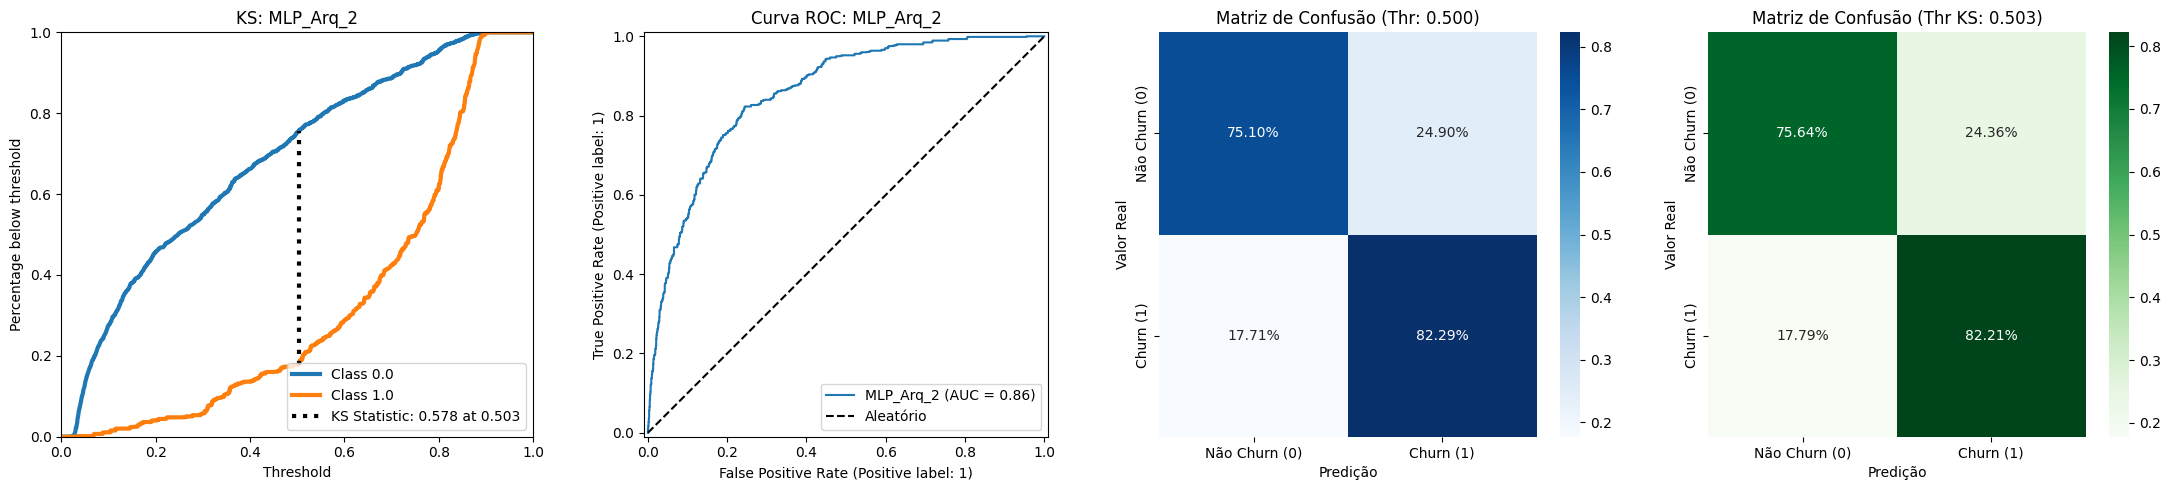

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5785 | AUROC: 0.8562 | Acurácia: 0.7869
Precisão: 0.7677 | Recall: 0.8229 | F1-Score: 0.7943

Relatório de Classificação (Threshold Padrão):
               precision    recall  f1-score   support

Não Churn (0)       0.81      0.75      0.78      1293
    Churn (1)       0.77      0.82      0.79      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79      2586
 weighted avg       0.79      0.79      0.79      2586


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.503) ---
KS: 0.5785 | AUROC: 0.8562 | Acurácia: 0.7892
Precisão: 0.7714 | Recall: 0.8221 | F1-Score: 0.7960

Relatório de Classificação (Threshold Otimizado):
               precision    recall  f1-score   support

Não Churn (0)       0.81      0.76      0.78      1293
    Churn (1)       0.77      0.82      0.80      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79

/tmp/ipykernel_705/227446722.py:15: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




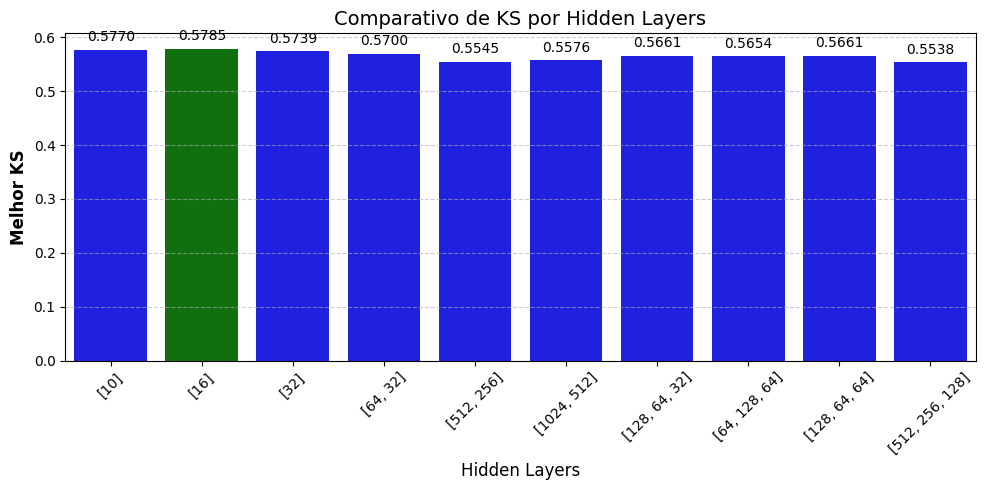

In [ ]:
import time

# Definindo as constantes
input_size = X_train_final.shape[1]
MAX_EPOCHS = 10000  # Limite altíssimo, confiaremos no Early Stopping (patience=20)

# O que vamos variar nesta rodada:
arquiteturas_teste = [
    [10], [16], [32], [64, 32], [512,256], [1024,512] ,[128, 64, 32], [64, 128, 64], [128, 64, 64], [512, 256, 128]
]
resultados_rodada_1 = []

start_total = time.time()

for idx, arq in enumerate(arquiteturas_teste):
    nome_experimento = f"MLP_Arq_{idx+1}"

    resultado = executar_experimento_churn(
        name_experiment=nome_experimento,
        input_size=input_size,
        hidden_layers=arq,             # <--- Variável do loop
        learning_rate=0.001,           # Fixo
        batch_size=64,                 # Fixo
        num_epochs=MAX_EPOCHS,         # 10.000 épocas (parará bem antes)
        activation_function=nn.ReLU,   # Fixo
        loss_name='CrossEntropy',      # Fixo
        optimizer_name='Adam',         # Fixo
        weight_decay=0.0,              # Fixo
        dropout_rate=0.0,              # Fixo
        X_train=X_train_final,
        y_train=y_train,
        X_val=X_val_final,
        y_val=y_val
    )
    resultados_rodada_1.append(resultado)

end_total = time.time()
tempo_minutos = (end_total - start_total) / 60
print(f"\n{'='*60}")
print(f"TEMPO TOTAL DA RODADA 1: {tempo_minutos:.2f} minutos")
print(f"{'='*60}\n")

# Salvar o log dessa rodada no Drive
df_resultados = pd.DataFrame(resultados_rodada_1)
df_resultados.to_csv(os.path.join(caminho_logs, "rodada_1_arquiteturas.csv"),  index=False)

# Mostrar o vencedor e os gráficos
vencedor_r1 = plotar_vencedor_churn(resultados_rodada_1, input_size, X_val_final, y_val)

# Chamando a função para analisar o que acabamos de rodar (Rodada 1 - Hidden Layers)
plotar_evolucao_parametros(df_resultados, 'hidden_layers')


## Experimentos Rodada 2 - Learning Rate

Usando a melhor arquitetura da Rodada 1: [16]

----------------------------------------------------------------------
EXPERIMENTO: MLP_LR_1 | Camadas: [16] | LR: 0.1 | Batch: 64


Treinando:   0%|          | 24/10000 [00:02<16:48,  9.89it/s]


 -> Early stopping acionado na época 25
Resultado Final - Val Loss: 0.4736 | Melhor KS: 0.5607 | Tempo: 2.43s

----------------------------------------------------------------------
EXPERIMENTO: MLP_LR_2 | Camadas: [16] | LR: 0.01 | Batch: 64


Treinando:   0%|          | 23/10000 [00:01<13:56, 11.93it/s]


 -> Early stopping acionado na época 24
Resultado Final - Val Loss: 0.4737 | Melhor KS: 0.5770 | Tempo: 1.93s

----------------------------------------------------------------------
EXPERIMENTO: MLP_LR_3 | Camadas: [16] | LR: 0.005 | Batch: 64


Treinando:   0%|          | 24/10000 [00:02<14:38, 11.36it/s]


... (3 outputs left out)

Treinando:   0%|          | 45/10000 [00:03<12:22, 13.42it/s]


 -> Early stopping acionado na época 46
Resultado Final - Val Loss: 0.4720 | Melhor KS: 0.5762 | Tempo: 3.36s

----------------------------------------------------------------------
EXPERIMENTO: MLP_LR_6 | Camadas: [16] | LR: 0.0001 | Batch: 64


Treinando:   4%|▎         | 373/10000 [00:23<10:03, 15.94it/s]


 -> Early stopping acionado na época 374
Resultado Final - Val Loss: 0.4701 | Melhor KS: 0.5793 | Tempo: 23.40s

TEMPO TOTAL DA RODADA 2: 0.60 minutos


VENCEDOR DA BATERIA: MLP_LR_6 (KS Máximo: 0.5793)


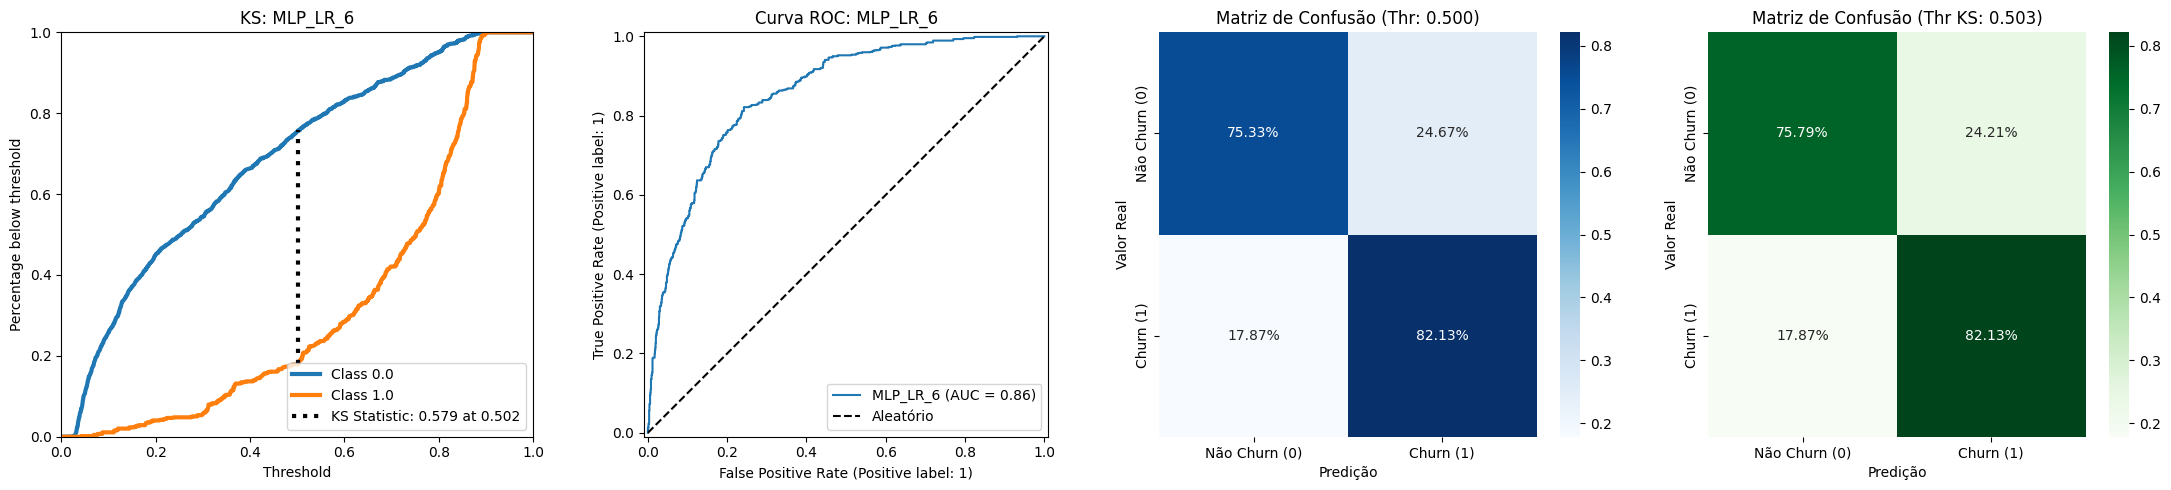

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5793 | AUROC: 0.8568 | Acurácia: 0.7873
Precisão: 0.7690 | Recall: 0.8213 | F1-Score: 0.7943

Relatório de Classificação (Threshold Padrão):
               precision    recall  f1-score   support

Não Churn (0)       0.81      0.75      0.78      1293
    Churn (1)       0.77      0.82      0.79      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79      2586
 weighted avg       0.79      0.79      0.79      2586


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.503) ---
KS: 0.5793 | AUROC: 0.8568 | Acurácia: 0.7896
Precisão: 0.7724 | Recall: 0.8213 | F1-Score: 0.7961

Relatório de Classificação (Threshold Otimizado):
               precision    recall  f1-score   support

Não Churn (0)       0.81      0.76      0.78      1293
    Churn (1)       0.77      0.82      0.80      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79

/tmp/ipykernel_705/227446722.py:15: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




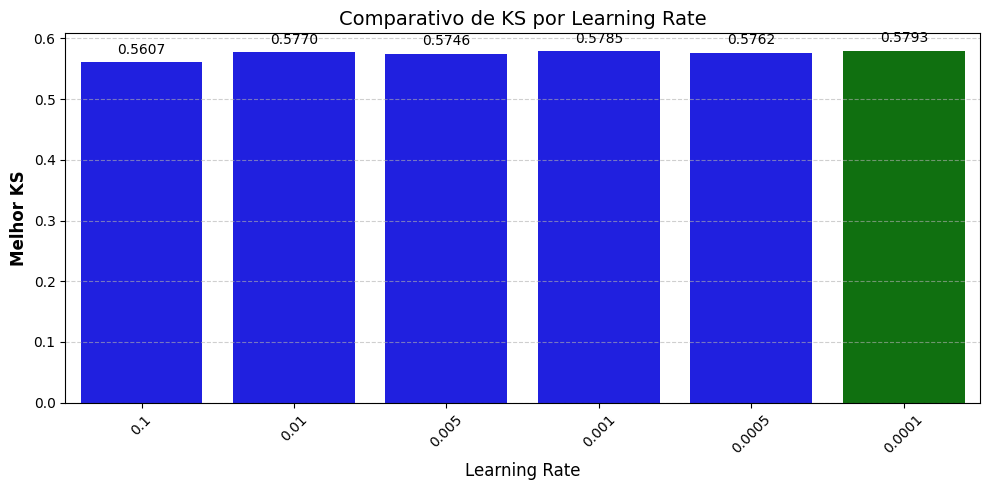

In [ ]:
import time

# Definindo as constantes
input_size = X_train_final.shape[1]
MAX_EPOCHS = 10000  # Limite altíssimo, confiaremos no Early Stopping (patience=20)

# O que vamos variar nesta rodada: Learning Rate
learning_rates_teste = [0.1, 0.01, 0.005, 0.001, 0.0005, 0.0001]
resultados_rodada_2 = []

# Vamos fixar a melhor arquitetura encontrada na Rodada 1
melhor_arq = vencedor_r1['hidden_layers']
print(f"Usando a melhor arquitetura da Rodada 1: {melhor_arq}")

start_total = time.time()

for idx, lr in enumerate(learning_rates_teste):
    # NOVO NOME PARA NÃO SOBRESCREVER OS .pth DA RODADA 1
    nome_experimento = f"MLP_LR_{idx+1}"

    resultado = executar_experimento_churn(
        name_experiment=nome_experimento,
        input_size=input_size,
        hidden_layers=melhor_arq,      # Fixo (Vencedor R1)
        learning_rate=lr,              # <--- Variável do loop
        batch_size=64,                 # Fixo
        num_epochs=MAX_EPOCHS,
        activation_function=nn.ReLU,   # Fixo
        loss_name='CrossEntropy',      # Fixo
        optimizer_name='Adam',         # Fixo
        weight_decay=0.0,              # Fixo
        dropout_rate=0.0,              # Fixo
        X_train=X_train_final,
        y_train=y_train,
        X_val=X_val_final,
        y_val=y_val
    )
    resultados_rodada_2.append(resultado)

end_total = time.time()
tempo_minutos = (end_total - start_total) / 60
print(f"\n{'='*60}")
print(f"TEMPO TOTAL DA RODADA 2: {tempo_minutos:.2f} minutos")
print(f"{'='*60}\n")

# NOVO NOME DE CSV PARA NÃO SOBRESCREVER O LOG DA RODADA 1
df_resultados_r2 = pd.DataFrame(resultados_rodada_2)
df_resultados_r2.to_csv(os.path.join(caminho_logs, "rodada_2_learning_rate.csv"), index=False)

# Mostrar o vencedor desta rodada'
vencedor_r2 = plotar_vencedor_churn(resultados_rodada_2, input_size, X_val_final, y_val)

# Chamando a função para analisar o que acabamos de rodar (Rodada 2 - Learning Rate)
plotar_evolucao_parametros(df_resultados_r2, 'learning_rate')

## Experimentos Rodada 3 - Função de Ativação

Fixando parâmetros -> Arquitetura: [16] | Learning Rate: 0.0001

----------------------------------------------------------------------
EXPERIMENTO: MLP_Ativacao_1 | Camadas: [16] | LR: 0.0001 | Batch: 64


Treinando:   4%|▎         | 373/10000 [00:23<10:05, 15.91it/s]


 -> Early stopping acionado na época 374
Resultado Final - Val Loss: 0.4701 | Melhor KS: 0.5793 | Tempo: 23.45s

----------------------------------------------------------------------
EXPERIMENTO: MLP_Ativacao_2 | Camadas: [16] | LR: 0.0001 | Batch: 64


Treinando:   3%|▎         | 295/10000 [00:18<10:10, 15.90it/s]


 -> Early stopping acionado na época 296
Resultado Final - Val Loss: 0.4684 | Melhor KS: 0.5777 | Tempo: 18.55s

----------------------------------------------------------------------
EXPERIMENTO: MLP_Ativacao_3 | Camadas: [16] | LR: 0.0001 | Batch: 64


Treinando:   8%|▊         | 755/10000 [00:46<09:30, 16.21it/s]


 -> Early stopping acionado na época 756
Resultado Final - Val Loss: 0.4696 | Melhor KS: 0.5746 | Tempo: 46.58s

----------------------------------------------------------------------
EXPERIMENTO: MLP_Ativacao_4 | Camadas: [16] | LR: 0.0001 | Batch: 64


Treinando:   4%|▍         | 402/10000 [00:25<09:57, 16.06it/s]


 -> Early stopping acionado na época 403
Resultado Final - Val Loss: 0.4686 | Melhor KS: 0.5808 | Tempo: 25.04s

TEMPO TOTAL DA RODADA 3: 1.89 minutos


VENCEDOR DA BATERIA: MLP_Ativacao_4 (KS Máximo: 0.5808)


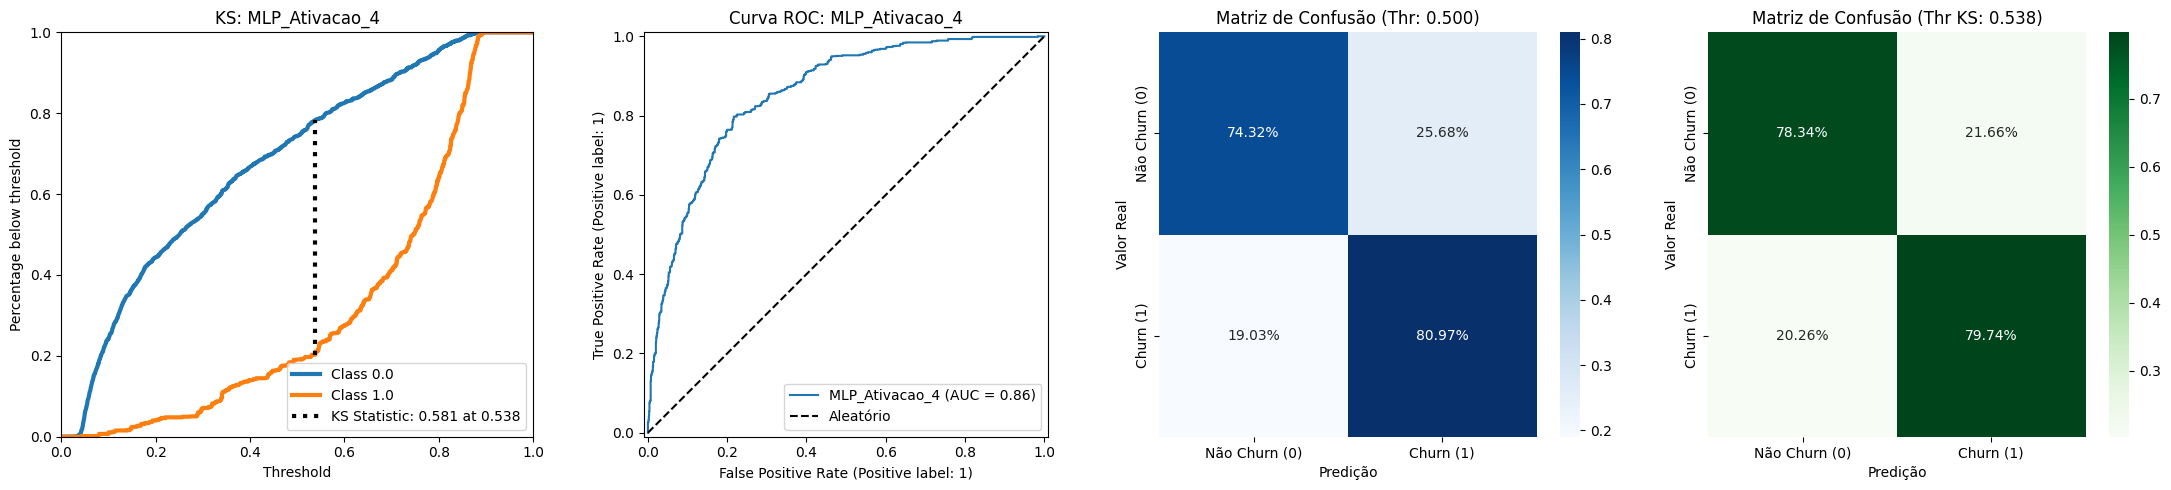

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5808 | AUROC: 0.8560 | Acurácia: 0.7765
Precisão: 0.7592 | Recall: 0.8097 | F1-Score: 0.7837

Relatório de Classificação (Threshold Padrão):
               precision    recall  f1-score   support

Não Churn (0)       0.80      0.74      0.77      1293
    Churn (1)       0.76      0.81      0.78      1293

     accuracy                           0.78      2586
    macro avg       0.78      0.78      0.78      2586
 weighted avg       0.78      0.78      0.78      2586


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.538) ---
KS: 0.5808 | AUROC: 0.8560 | Acurácia: 0.7904
Precisão: 0.7864 | Recall: 0.7974 | F1-Score: 0.7919

Relatório de Classificação (Threshold Otimizado):
               precision    recall  f1-score   support

Não Churn (0)       0.79      0.78      0.79      1293
    Churn (1)       0.79      0.80      0.79      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79

/tmp/ipykernel_705/227446722.py:15: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




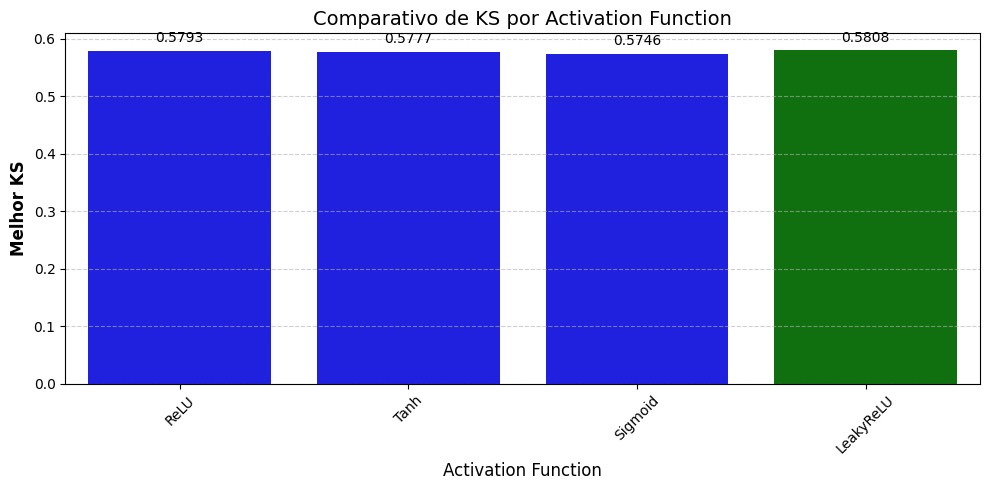

In [ ]:
import time
import torch.nn as nn

# O que vamos variar nesta rodada: Função de Ativação
ativacoes_teste = [nn.ReLU, nn.Tanh, nn.Sigmoid, nn.LeakyReLU]
resultados_rodada_3 = []

# Resgatando vencedores das rodadas anteriores
melhor_arq = vencedor_r1['hidden_layers']
melhor_lr = vencedor_r2['learning_rate']
print(f"Fixando parâmetros -> Arquitetura: {melhor_arq} | Learning Rate: {melhor_lr}")

start_total = time.time()

for idx, ativacao in enumerate(ativacoes_teste):
    nome_experimento = f"MLP_Ativacao_{idx+1}"

    resultado = executar_experimento_churn(
        name_experiment=nome_experimento,
        input_size=input_size,
        hidden_layers=melhor_arq,      # Fixo (Vencedor R1)
        learning_rate=melhor_lr,       # Fixo (Vencedor R2)
        batch_size=64,                 # Fixo (por enquanto)
        num_epochs=MAX_EPOCHS,
        activation_function=ativacao,  # <--- Variável do loop
        loss_name='CrossEntropy',      # Fixo
        optimizer_name='Adam',         # Fixo
        weight_decay=0.0,              # Fixo
        dropout_rate=0.0,              # Fixo
        X_train=X_train_final,
        y_train=y_train,
        X_val=X_val_final,
        y_val=y_val
    )
    resultados_rodada_3.append(resultado)

end_total = time.time()
tempo_minutos = (end_total - start_total) / 60
print(f"\n{'='*60}\nTEMPO TOTAL DA RODADA 3: {tempo_minutos:.2f} minutos\n{'='*60}\n")

df_resultados_r3 = pd.DataFrame(resultados_rodada_3)
df_resultados_r3.to_csv(os.path.join(caminho_logs, "rodada_3_ativacao.csv"), index=False)

# Encontrar a função vencedora para passar pro plot (pois o dict salva como string)
vencedor_r3_dict = max(resultados_rodada_3, key=lambda x: x['val_ks'])
funcao_vencedora_r3 = next(f for f in ativacoes_teste if f.__name__ == vencedor_r3_dict['activation_function'])

vencedor_r3 = plotar_vencedor_churn(resultados_rodada_3, input_size, X_val_final, y_val, activation_function=funcao_vencedora_r3)
plotar_evolucao_parametros(df_resultados_r3, 'activation_function')

## Experimentos Rodada 4 - Batch Size

Fixando -> Arq: [16] | LR: 0.0001 | Ativação: LeakyReLU

----------------------------------------------------------------------
EXPERIMENTO: MLP_Batch_1 | Camadas: [16] | LR: 0.0001 | Batch: 16


Treinando:   2%|▏         | 203/10000 [00:35<28:34,  5.71it/s]


 -> Early stopping acionado na época 204
Resultado Final - Val Loss: 0.4688 | Melhor KS: 0.5800 | Tempo: 35.54s

----------------------------------------------------------------------
EXPERIMENTO: MLP_Batch_2 | Camadas: [16] | LR: 0.0001 | Batch: 32


Treinando:   1%|          | 120/10000 [00:12<17:28,  9.42it/s]


 -> Early stopping acionado na época 121
Resultado Final - Val Loss: 0.4721 | Melhor KS: 0.5824 | Tempo: 12.74s

----------------------------------------------------------------------
EXPERIMENTO: MLP_Batch_3 | Camadas: [16] | LR: 0.0001 | Batch: 64


Treinando:   4%|▍         | 402/10000 [00:24<09:55, 16.11it/s]


... (5 outputs left out)

Treinando:   4%|▍         | 443/10000 [00:14<05:22, 29.65it/s]


 -> Early stopping acionado na época 444
Resultado Final - Val Loss: 0.4776 | Melhor KS: 0.5785 | Tempo: 14.94s

----------------------------------------------------------------------
EXPERIMENTO: MLP_Batch_7 | Camadas: [16] | LR: 0.0001 | Batch: 1024


Treinando:   7%|▋         | 700/10000 [00:22<05:00, 30.95it/s]


 -> Early stopping acionado na época 701
Resultado Final - Val Loss: 0.4755 | Melhor KS: 0.5770 | Tempo: 22.62s

TEMPO TOTAL DA RODADA 4: 2.30 minutos


VENCEDOR DA BATERIA: MLP_Batch_2 (KS Máximo: 0.5824)


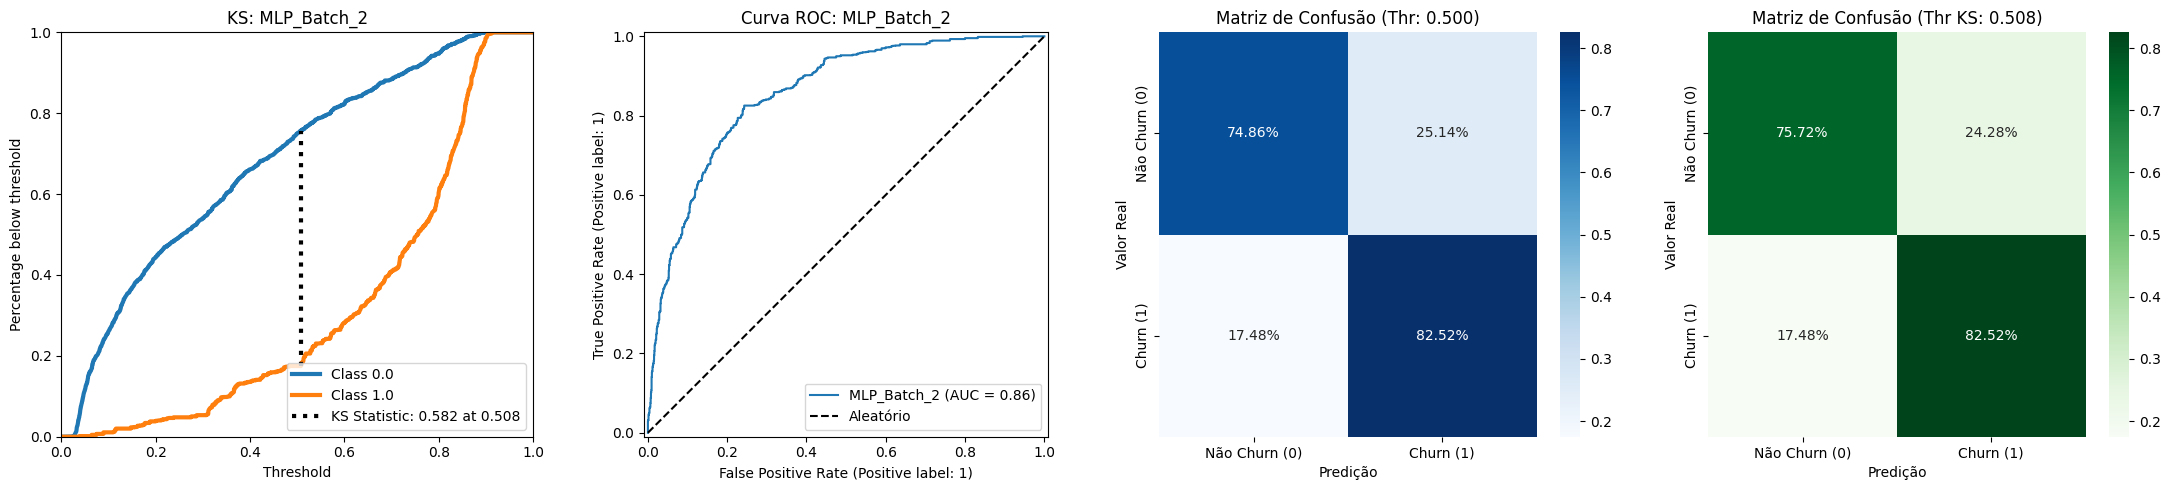

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5824 | AUROC: 0.8567 | Acurácia: 0.7869
Precisão: 0.7665 | Recall: 0.8252 | F1-Score: 0.7948

Relatório de Classificação (Threshold Padrão):
               precision    recall  f1-score   support

Não Churn (0)       0.81      0.75      0.78      1293
    Churn (1)       0.77      0.83      0.79      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79      2586
 weighted avg       0.79      0.79      0.79      2586


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.508) ---
KS: 0.5824 | AUROC: 0.8567 | Acurácia: 0.7912
Precisão: 0.7726 | Recall: 0.8252 | F1-Score: 0.7981

Relatório de Classificação (Threshold Otimizado):
               precision    recall  f1-score   support

Não Churn (0)       0.81      0.76      0.78      1293
    Churn (1)       0.77      0.83      0.80      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79

/tmp/ipykernel_705/227446722.py:15: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




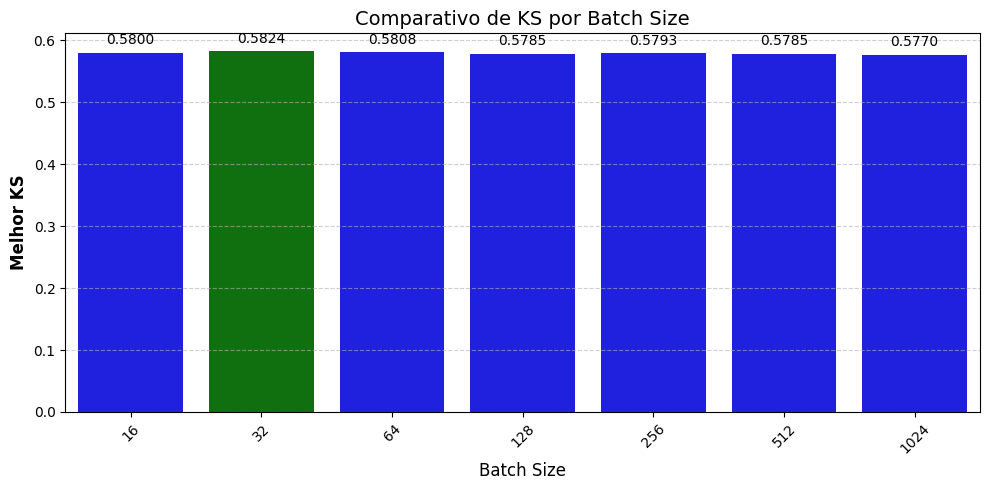

In [ ]:
import time

# O que vamos variar nesta rodada: Batch Size
batch_sizes_teste = [16, 32, 64, 128, 256, 512, 1024]
resultados_rodada_4 = []

# Resgatando vencedores das rodadas anteriores
melhor_arq = vencedor_r1['hidden_layers']
melhor_lr = vencedor_r2['learning_rate']
melhor_ativacao = next(f for f in ativacoes_teste if f.__name__ == vencedor_r3['activation_function'])
print(f"Fixando -> Arq: {melhor_arq} | LR: {melhor_lr} | Ativação: {melhor_ativacao.__name__}")

start_total = time.time()

for idx, batch in enumerate(batch_sizes_teste):
    nome_experimento = f"MLP_Batch_{idx+1}"

    resultado = executar_experimento_churn(
        name_experiment=nome_experimento,
        input_size=input_size,
        hidden_layers=melhor_arq,         # Fixo (Vencedor R1)
        learning_rate=melhor_lr,          # Fixo (Vencedor R2)
        batch_size=batch,                 # <--- Variável do loop
        num_epochs=MAX_EPOCHS,
        activation_function=melhor_ativacao, # Fixo (Vencedor R3)
        loss_name='CrossEntropy',         # Fixo
        optimizer_name='Adam',            # Fixo
        weight_decay=0.0,                 # Fixo
        dropout_rate=0.0,                 # Fixo
        X_train=X_train_final,
        y_train=y_train,
        X_val=X_val_final,
        y_val=y_val
    )
    resultados_rodada_4.append(resultado)

end_total = time.time()
tempo_minutos = (end_total - start_total) / 60
print(f"\n{'='*60}\nTEMPO TOTAL DA RODADA 4: {tempo_minutos:.2f} minutos\n{'='*60}\n")

df_resultados_r4 = pd.DataFrame(resultados_rodada_4)
df_resultados_r4.to_csv(os.path.join(caminho_logs, "rodada_4_batch_size.csv"), index=False)

vencedor_r4 = plotar_vencedor_churn(resultados_rodada_4, input_size, X_val_final, y_val, activation_function=melhor_ativacao)
plotar_evolucao_parametros(df_resultados_r4, 'batch_size')

## Experimentos Rodada 5 - Otimizador

Fixando -> Arq: [16] | LR: 0.0001 | Ativação: LeakyReLU | Batch: 32

----------------------------------------------------------------------
EXPERIMENTO: MLP_Otimizador_1 | Camadas: [16] | LR: 0.0001 | Batch: 32


Treinando:   1%|          | 120/10000 [00:14<20:11,  8.16it/s]


 -> Early stopping acionado na época 121
Resultado Final - Val Loss: 0.4721 | Melhor KS: 0.5824 | Tempo: 14.71s

----------------------------------------------------------------------
EXPERIMENTO: MLP_Otimizador_2 | Camadas: [16] | LR: 0.0001 | Batch: 32


Treinando:  57%|█████▋    | 5674/10000 [07:38<05:49, 12.36it/s]


 -> Early stopping acionado na época 5675
Resultado Final - Val Loss: 0.4730 | Melhor KS: 0.5777 | Tempo: 458.89s

----------------------------------------------------------------------
EXPERIMENTO: MLP_Otimizador_3 | Camadas: [16] | LR: 0.0001 | Batch: 32


Treinando:   2%|▏         | 167/10000 [00:16<16:34,  9.89it/s]


 -> Early stopping acionado na época 168
Resultado Final - Val Loss: 0.4709 | Melhor KS: 0.5785 | Tempo: 16.89s

----------------------------------------------------------------------
EXPERIMENTO: MLP_Otimizador_4 | Camadas: [16] | LR: 0.0001 | Batch: 32


Treinando:   0%|          | 26/10000 [00:03<20:27,  8.12it/s]


 -> Early stopping acionado na época 27
Resultado Final - Val Loss: 0.4720 | Melhor KS: 0.5754 | Tempo: 3.20s

TEMPO TOTAL DA RODADA 5: 8.23 minutos


VENCEDOR DA BATERIA: MLP_Otimizador_1 (KS Máximo: 0.5824)


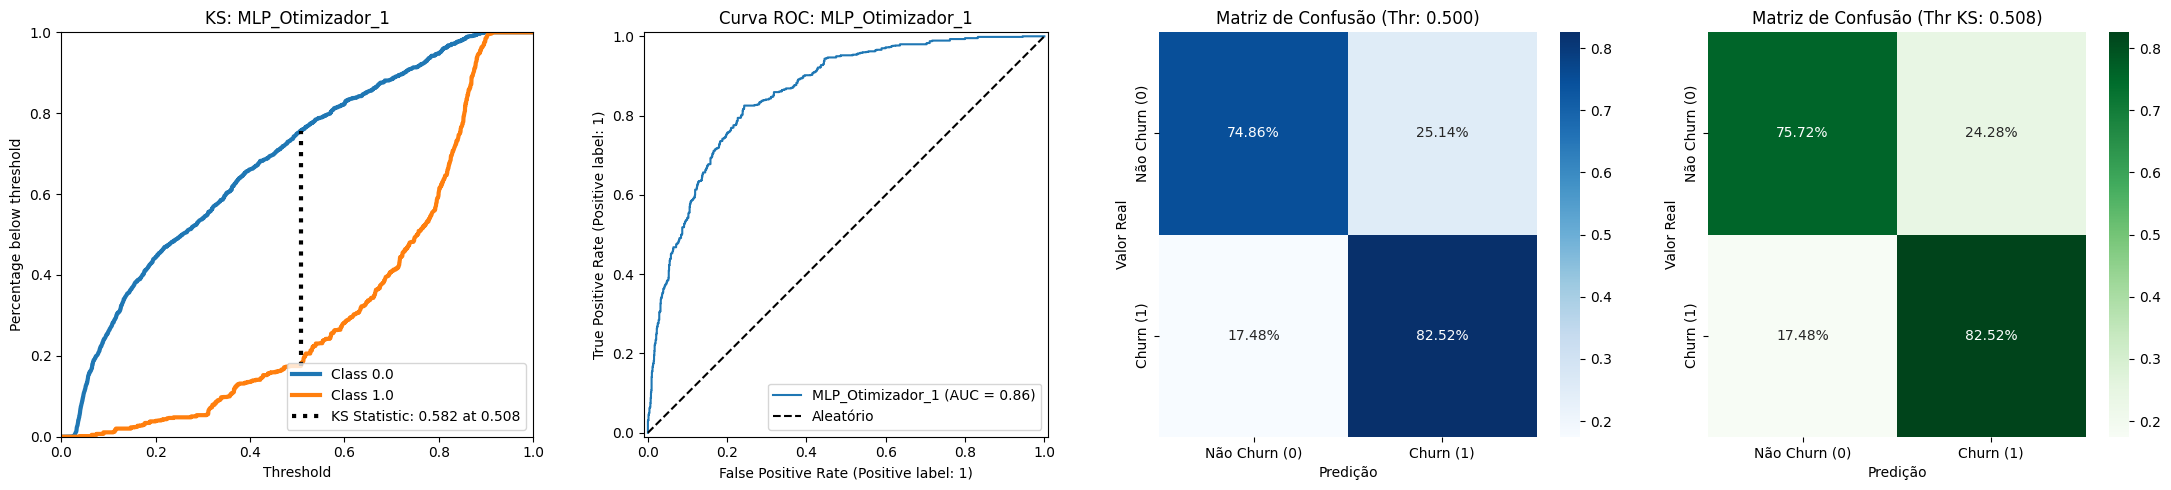

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5824 | AUROC: 0.8567 | Acurácia: 0.7869
Precisão: 0.7665 | Recall: 0.8252 | F1-Score: 0.7948

Relatório de Classificação (Threshold Padrão):
               precision    recall  f1-score   support

Não Churn (0)       0.81      0.75      0.78      1293
    Churn (1)       0.77      0.83      0.79      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79      2586
 weighted avg       0.79      0.79      0.79      2586


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.508) ---
KS: 0.5824 | AUROC: 0.8567 | Acurácia: 0.7912
Precisão: 0.7726 | Recall: 0.8252 | F1-Score: 0.7981

Relatório de Classificação (Threshold Otimizado):
               precision    recall  f1-score   support

Não Churn (0)       0.81      0.76      0.78      1293
    Churn (1)       0.77      0.83      0.80      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79

/tmp/ipykernel_705/227446722.py:15: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




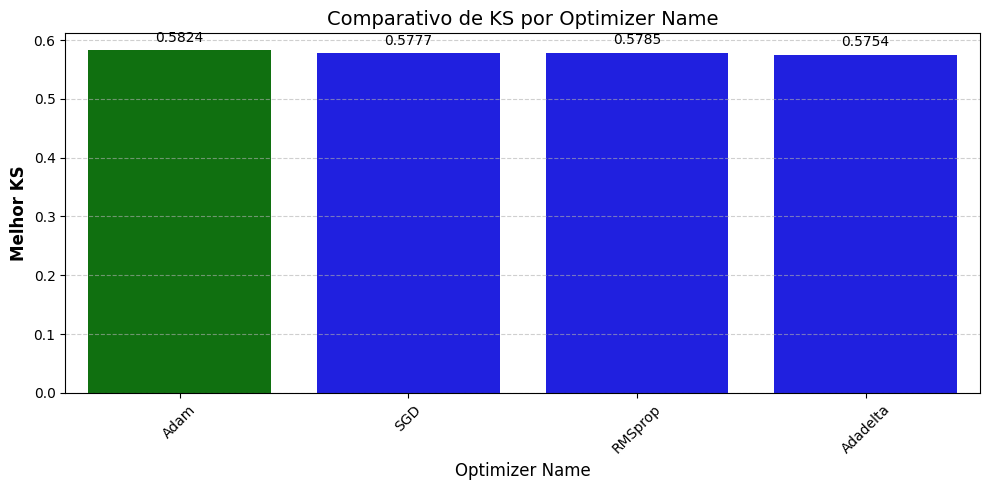

In [ ]:
import time

# O que vamos variar nesta rodada: Otimizador
otimizadores_teste = ['Adam', 'SGD', 'RMSprop', 'Adadelta']
resultados_rodada_5 = []

# Resgatando vencedores
melhor_arq = vencedor_r1['hidden_layers']
melhor_lr = vencedor_r2['learning_rate']
melhor_ativacao = next(f for f in ativacoes_teste if f.__name__ == vencedor_r3['activation_function'])
melhor_batch = vencedor_r4['batch_size']
print(f"Fixando -> Arq: {melhor_arq} | LR: {melhor_lr} | Ativação: {melhor_ativacao.__name__} | Batch: {melhor_batch}")

start_total = time.time()

for idx, otimizador in enumerate(otimizadores_teste):
    nome_experimento = f"MLP_Otimizador_{idx+1}"

    resultado = executar_experimento_churn(
        name_experiment=nome_experimento,
        input_size=input_size,
        hidden_layers=melhor_arq,
        learning_rate=melhor_lr,
        batch_size=melhor_batch,
        num_epochs=MAX_EPOCHS,
        activation_function=melhor_ativacao,
        loss_name='CrossEntropy',
        optimizer_name=otimizador,     # <--- Variável do loop
        weight_decay=0.0,
        dropout_rate=0.0,
        X_train=X_train_final,
        y_train=y_train,
        X_val=X_val_final,
        y_val=y_val
    )
    resultados_rodada_5.append(resultado)

end_total = time.time()
tempo_minutos = (end_total - start_total) / 60
print(f"\n{'='*60}\nTEMPO TOTAL DA RODADA 5: {tempo_minutos:.2f} minutos\n{'='*60}\n")

df_resultados_r5 = pd.DataFrame(resultados_rodada_5)
df_resultados_r5.to_csv(os.path.join(caminho_logs, "rodada_5_otimizador.csv"), index=False)

vencedor_r5 = plotar_vencedor_churn(resultados_rodada_5, input_size, X_val_final, y_val, activation_function=melhor_ativacao)
plotar_evolucao_parametros(df_resultados_r5, 'optimizer_name')

## Experimentos Rodada 6 - Weight Decay (Regularização L2)

Fixando -> Arq: [16] | LR: 0.0001 | Ativ: LeakyReLU | Batch: 32 | Otimizador: Adam

----------------------------------------------------------------------
EXPERIMENTO: MLP_WD_1 | Camadas: [16] | LR: 0.0001 | Batch: 32


Treinando:   1%|          | 120/10000 [00:12<17:21,  9.49it/s]


 -> Early stopping acionado na época 121
Resultado Final - Val Loss: 0.4721 | Melhor KS: 0.5824 | Tempo: 12.65s

----------------------------------------------------------------------
EXPERIMENTO: MLP_WD_2 | Camadas: [16] | LR: 0.0001 | Batch: 32


Treinando:   3%|▎         | 324/10000 [00:33<16:42,  9.65it/s]


 -> Early stopping acionado na época 325
Resultado Final - Val Loss: 0.4704 | Melhor KS: 0.5831 | Tempo: 33.58s

----------------------------------------------------------------------
EXPERIMENTO: MLP_WD_3 | Camadas: [16] | LR: 0.0001 | Batch: 32


Treinando:   3%|▎         | 266/10000 [00:27<16:57,  9.57it/s]


... (5 outputs left out)

Treinando:   2%|▏         | 200/10000 [00:21<17:20,  9.42it/s]


 -> Early stopping acionado na época 201
Resultado Final - Val Loss: 0.4680 | Melhor KS: 0.5770 | Tempo: 21.23s

----------------------------------------------------------------------
EXPERIMENTO: MLP_WD_7 | Camadas: [16] | LR: 0.0001 | Batch: 32


Treinando:   3%|▎         | 299/10000 [00:31<17:01,  9.49it/s]


 -> Early stopping acionado na época 300
Resultado Final - Val Loss: 0.4741 | Melhor KS: 0.5746 | Tempo: 31.50s

TEMPO TOTAL DA RODADA 6: 3.03 minutos


VENCEDOR DA BATERIA: MLP_WD_2 (KS Máximo: 0.5831)


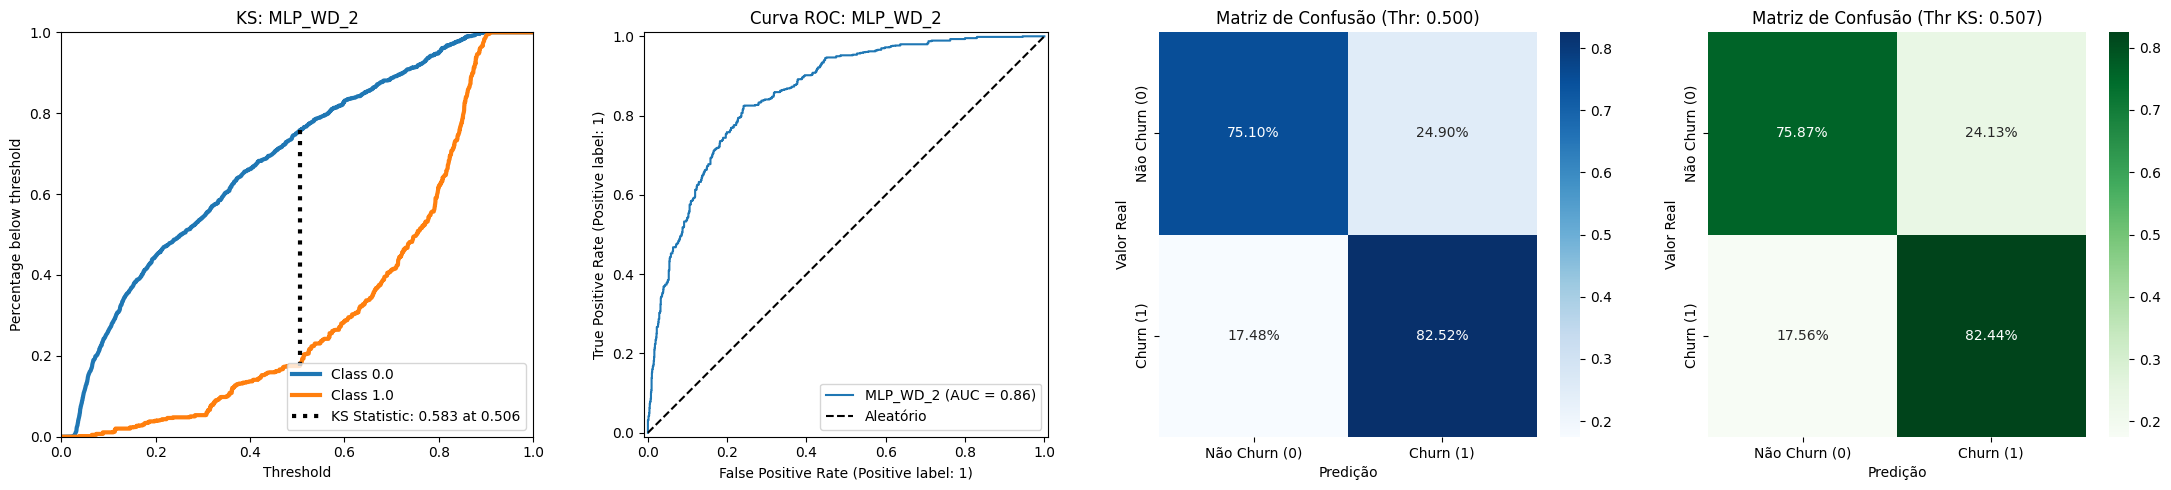

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5831 | AUROC: 0.8568 | Acurácia: 0.7881
Precisão: 0.7682 | Recall: 0.8252 | F1-Score: 0.7957

Relatório de Classificação (Threshold Padrão):
               precision    recall  f1-score   support

Não Churn (0)       0.81      0.75      0.78      1293
    Churn (1)       0.77      0.83      0.80      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79      2586
 weighted avg       0.79      0.79      0.79      2586


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.507) ---
KS: 0.5831 | AUROC: 0.8568 | Acurácia: 0.7916
Precisão: 0.7736 | Recall: 0.8244 | F1-Score: 0.7982

Relatório de Classificação (Threshold Otimizado):
               precision    recall  f1-score   support

Não Churn (0)       0.81      0.76      0.78      1293
    Churn (1)       0.77      0.82      0.80      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79

/tmp/ipykernel_705/227446722.py:15: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




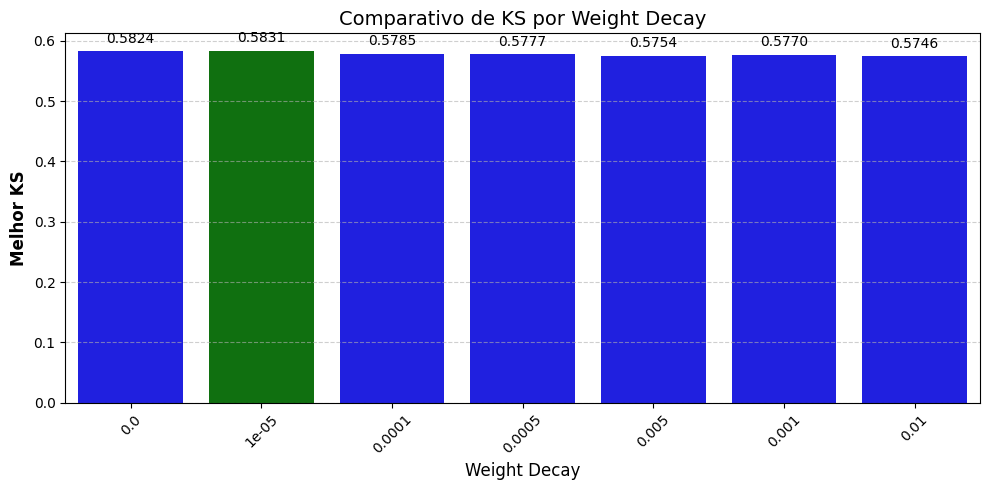

In [ ]:
import time

# O que vamos variar nesta rodada: Weight Decay
weight_decays_teste = [0.0, 1e-5, 1e-4, 5e-4, 5e-3, 1e-3, 1e-2]
resultados_rodada_6 = []

# Resgatando vencedores
melhor_arq = vencedor_r1['hidden_layers']
melhor_lr = vencedor_r2['learning_rate']
melhor_ativacao = next(f for f in ativacoes_teste if f.__name__ == vencedor_r3['activation_function'])
melhor_batch = vencedor_r4['batch_size']
melhor_otimizador = vencedor_r5['optimizer_name']
print(f"Fixando -> Arq: {melhor_arq} | LR: {melhor_lr} | Ativ: {melhor_ativacao.__name__} | Batch: {melhor_batch} | Otimizador: {melhor_otimizador}")

start_total = time.time()

for idx, wd in enumerate(weight_decays_teste):
    nome_experimento = f"MLP_WD_{idx+1}"

    resultado = executar_experimento_churn(
        name_experiment=nome_experimento,
        input_size=input_size,
        hidden_layers=melhor_arq,
        learning_rate=melhor_lr,
        batch_size=melhor_batch,
        num_epochs=MAX_EPOCHS,
        activation_function=melhor_ativacao,
        loss_name='CrossEntropy',
        optimizer_name=melhor_otimizador,
        weight_decay=wd,               # <--- Variável do loop
        dropout_rate=0.0,
        X_train=X_train_final,
        y_train=y_train,
        X_val=X_val_final,
        y_val=y_val
    )
    resultados_rodada_6.append(resultado)

end_total = time.time()
tempo_minutos = (end_total - start_total) / 60
print(f"\n{'='*60}\nTEMPO TOTAL DA RODADA 6: {tempo_minutos:.2f} minutos\n{'='*60}\n")

df_resultados_r6 = pd.DataFrame(resultados_rodada_6)
df_resultados_r6.to_csv(os.path.join(caminho_logs, "rodada_6_weight_decay.csv"), index=False)

vencedor_r6 = plotar_vencedor_churn(resultados_rodada_6, input_size, X_val_final, y_val, activation_function=melhor_ativacao)
plotar_evolucao_parametros(df_resultados_r6, 'weight_decay')

## Experimentos Rodada 7 - Dropout Rate

Fixando -> Arq: [16] | LR: 0.0001 | Ativ: LeakyReLU | Batch: 32 | Otimizador: Adam | WD: 1e-05

----------------------------------------------------------------------
EXPERIMENTO: MLP_Dropout_1 | Camadas: [16] | LR: 0.0001 | Batch: 32


Treinando:   3%|▎         | 324/10000 [00:35<17:34,  9.18it/s]


 -> Early stopping acionado na época 325
Resultado Final - Val Loss: 0.4704 | Melhor KS: 0.5831 | Tempo: 35.30s

----------------------------------------------------------------------
EXPERIMENTO: MLP_Dropout_2 | Camadas: [16] | LR: 0.0001 | Batch: 32


Treinando:   3%|▎         | 266/10000 [00:29<17:55,  9.05it/s]


 -> Early stopping acionado na época 267
Resultado Final - Val Loss: 0.4682 | Melhor KS: 0.5785 | Tempo: 29.40s

----------------------------------------------------------------------
EXPERIMENTO: MLP_Dropout_3 | Camadas: [16] | LR: 0.0001 | Batch: 32


Treinando:   2%|▏         | 222/10000 [00:28<20:42,  7.87it/s]


... (3 outputs left out)

Treinando:   2%|▏         | 152/10000 [00:18<19:32,  8.40it/s]


 -> Early stopping acionado na época 153
Resultado Final - Val Loss: 0.4704 | Melhor KS: 0.5762 | Tempo: 18.10s

----------------------------------------------------------------------
EXPERIMENTO: MLP_Dropout_6 | Camadas: [16] | LR: 0.0001 | Batch: 32


Treinando:   1%|          | 124/10000 [00:14<19:32,  8.42it/s]


 -> Early stopping acionado na época 125
Resultado Final - Val Loss: 0.4734 | Melhor KS: 0.5777 | Tempo: 14.73s

TEMPO TOTAL DA RODADA 7: 2.54 minutos


VENCEDOR DA BATERIA: MLP_Dropout_1 (KS Máximo: 0.5831)


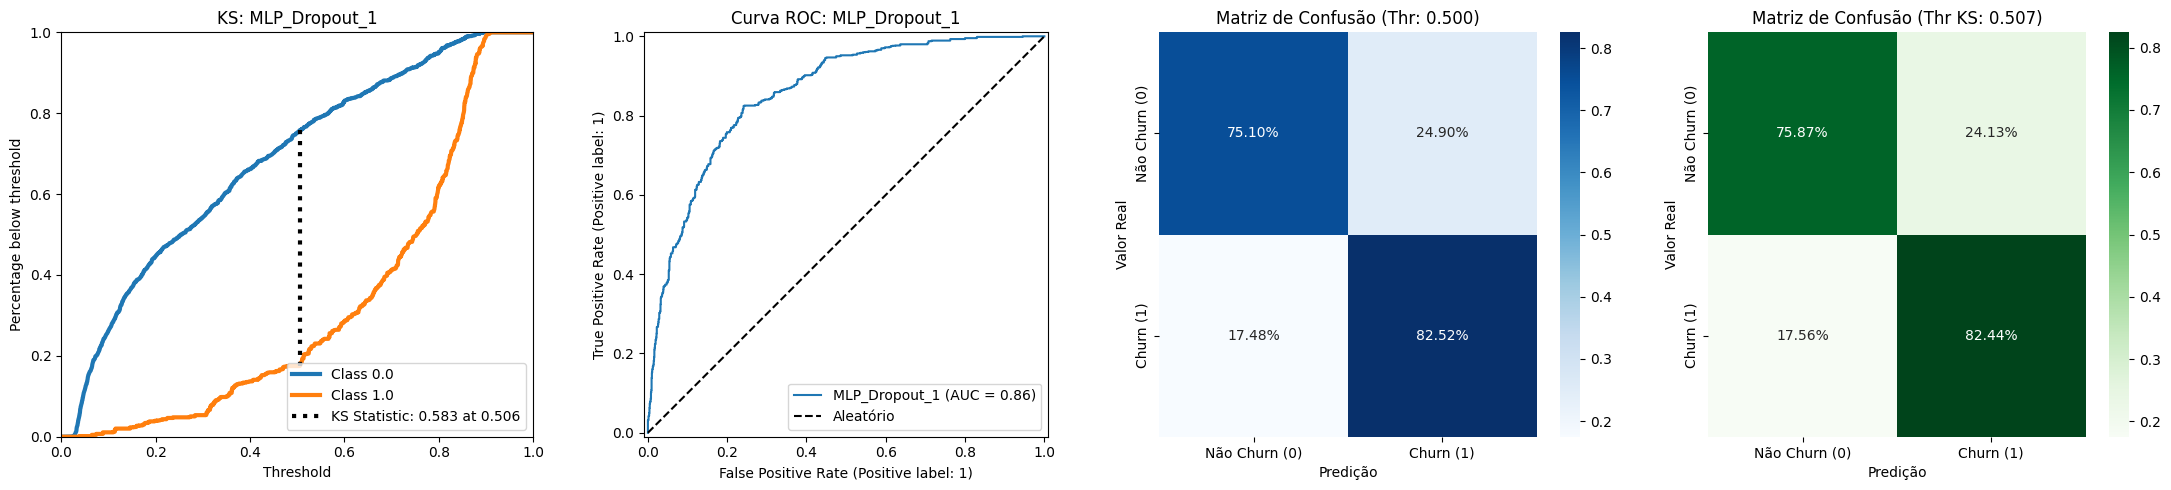

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5831 | AUROC: 0.8568 | Acurácia: 0.7881
Precisão: 0.7682 | Recall: 0.8252 | F1-Score: 0.7957

Relatório de Classificação (Threshold Padrão):
               precision    recall  f1-score   support

Não Churn (0)       0.81      0.75      0.78      1293
    Churn (1)       0.77      0.83      0.80      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79      2586
 weighted avg       0.79      0.79      0.79      2586


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.507) ---
KS: 0.5831 | AUROC: 0.8568 | Acurácia: 0.7916
Precisão: 0.7736 | Recall: 0.8244 | F1-Score: 0.7982

Relatório de Classificação (Threshold Otimizado):
               precision    recall  f1-score   support

Não Churn (0)       0.81      0.76      0.78      1293
    Churn (1)       0.77      0.82      0.80      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79

/tmp/ipykernel_705/227446722.py:15: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




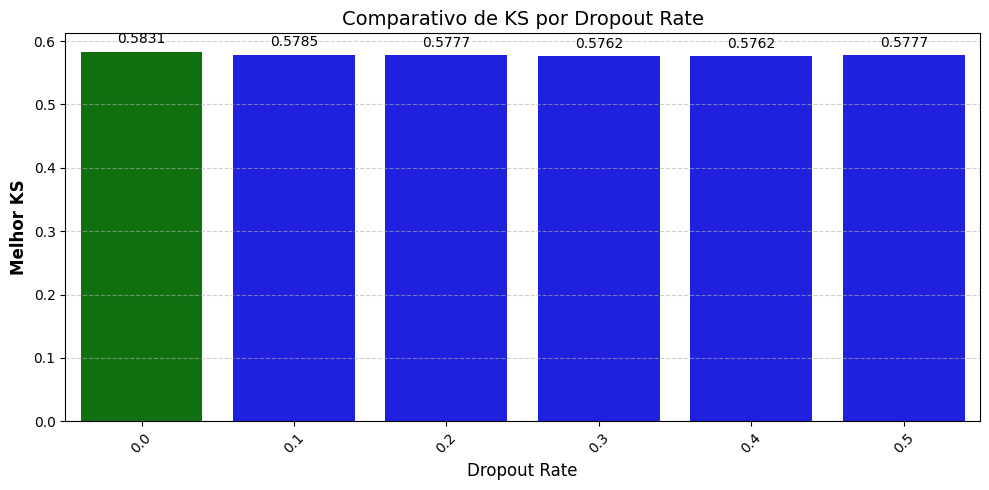



### OTIMIZAÇÃO CONCLUÍDA COM SUCESSO! ###
O SEU MELHOR MODELO (CAMPEÃO GERAL) É: MLP_Dropout_1


In [ ]:
import time

# O que vamos variar nesta rodada: Dropout
dropout_rates_teste = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
resultados_rodada_7 = []

# Resgatando vencedores de absolutamente todas as rodadas
melhor_arq = vencedor_r1['hidden_layers']
melhor_lr = vencedor_r2['learning_rate']
melhor_ativacao = next(f for f in ativacoes_teste if f.__name__ == vencedor_r3['activation_function'])
melhor_batch = vencedor_r4['batch_size']
melhor_otimizador = vencedor_r5['optimizer_name']
melhor_wd = vencedor_r6['weight_decay']
print(f"Fixando -> Arq: {melhor_arq} | LR: {melhor_lr} | Ativ: {melhor_ativacao.__name__} | Batch: {melhor_batch} | Otimizador: {melhor_otimizador} | WD: {melhor_wd}")

start_total = time.time()

for idx, dropout in enumerate(dropout_rates_teste):
    nome_experimento = f"MLP_Dropout_{idx+1}"

    resultado = executar_experimento_churn(
        name_experiment=nome_experimento,
        input_size=input_size,
        hidden_layers=melhor_arq,
        learning_rate=melhor_lr,
        batch_size=melhor_batch,
        num_epochs=MAX_EPOCHS,
        activation_function=melhor_ativacao,
        loss_name='CrossEntropy',
        optimizer_name=melhor_otimizador,
        weight_decay=melhor_wd,
        dropout_rate=dropout,          # <--- Variável do loop
        X_train=X_train_final,
        y_train=y_train,
        X_val=X_val_final,
        y_val=y_val
    )
    resultados_rodada_7.append(resultado)

end_total = time.time()
tempo_minutos = (end_total - start_total) / 60
print(f"\n{'='*60}\nTEMPO TOTAL DA RODADA 7: {tempo_minutos:.2f} minutos\n{'='*60}\n")

df_resultados_r7 = pd.DataFrame(resultados_rodada_7)
df_resultados_r7.to_csv(os.path.join(caminho_logs, "rodada_7_dropout.csv"), index=False)

vencedor_r7 = plotar_vencedor_churn(resultados_rodada_7, input_size, X_val_final, y_val, activation_function=melhor_ativacao)
plotar_evolucao_parametros(df_resultados_r7, 'dropout_rate')

print("\n\n### OTIMIZAÇÃO CONCLUÍDA COM SUCESSO! ###")
print(f"O SEU MELHOR MODELO (CAMPEÃO GERAL) É: {vencedor_r7['nome']}")

## Experimentos Rodada 8 - Função de Perda (Loss)

Fixando -> Arq: [16] | LR: 0.0001 | Ativ: LeakyReLU | Batch: 32 | Otimizador: Adam | WD: 1e-05 | Dropout: 0.0

----------------------------------------------------------------------
EXPERIMENTO: MLP_Loss_1 | Camadas: [16] | LR: 0.0001 | Batch: 32


Treinando:   3%|▎         | 324/10000 [00:33<16:50,  9.57it/s]


 -> Early stopping acionado na época 325
Resultado Final - Val Loss: 0.4704 | Melhor KS: 0.5831 | Tempo: 33.85s

----------------------------------------------------------------------
EXPERIMENTO: MLP_Loss_2 | Camadas: [16] | LR: 0.0001 | Batch: 32


Treinando:   2%|▏         | 167/10000 [00:17<17:29,  9.37it/s]


 -> Early stopping acionado na época 168
Resultado Final - Val Loss: 0.1544 | Melhor KS: 0.5808 | Tempo: 17.82s

TEMPO TOTAL DA RODADA 8: 0.86 minutos


VENCEDOR DA BATERIA: MLP_Loss_1 (KS Máximo: 0.5831)


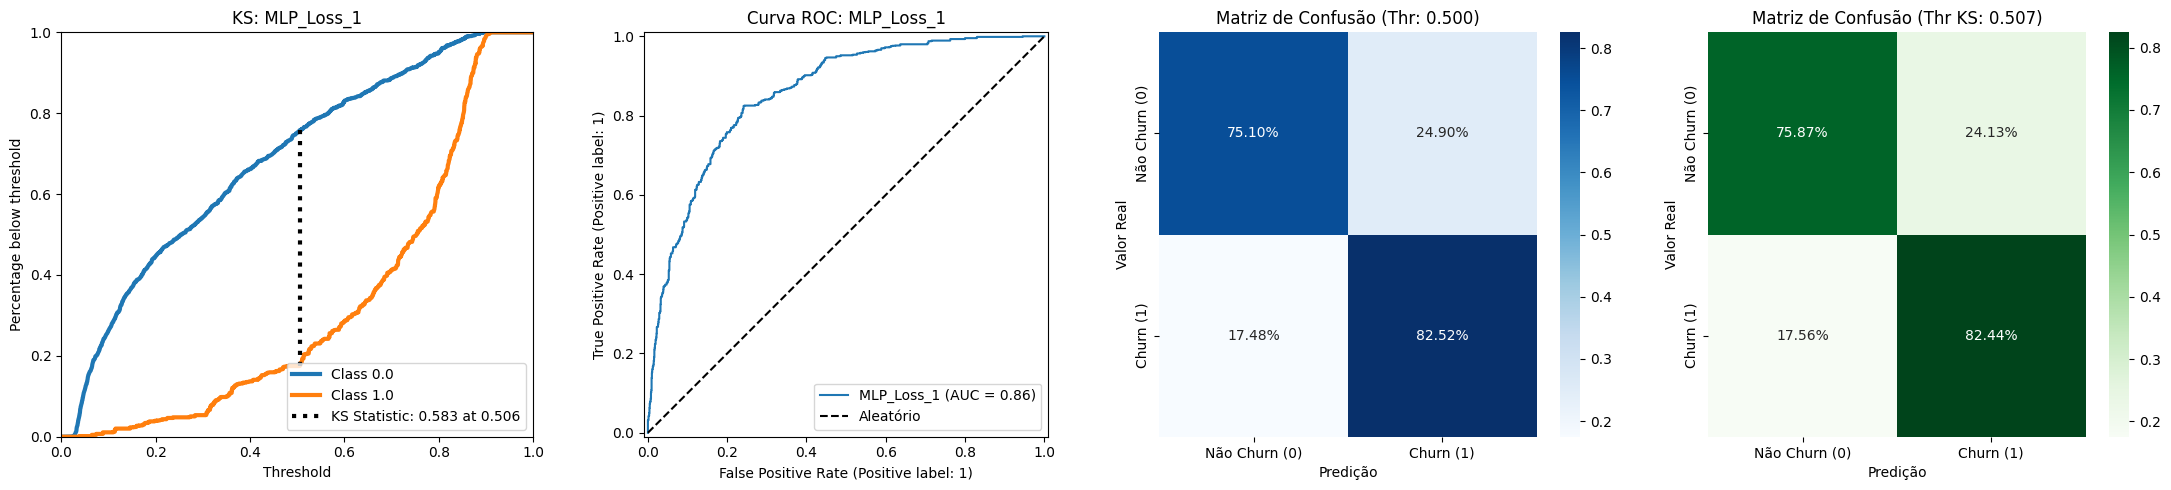

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5831 | AUROC: 0.8568 | Acurácia: 0.7881
Precisão: 0.7682 | Recall: 0.8252 | F1-Score: 0.7957

Relatório de Classificação (Threshold Padrão):
               precision    recall  f1-score   support

Não Churn (0)       0.81      0.75      0.78      1293
    Churn (1)       0.77      0.83      0.80      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79      2586
 weighted avg       0.79      0.79      0.79      2586


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.507) ---
KS: 0.5831 | AUROC: 0.8568 | Acurácia: 0.7916
Precisão: 0.7736 | Recall: 0.8244 | F1-Score: 0.7982

Relatório de Classificação (Threshold Otimizado):
               precision    recall  f1-score   support

Não Churn (0)       0.81      0.76      0.78      1293
    Churn (1)       0.77      0.82      0.80      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79

/tmp/ipykernel_705/227446722.py:15: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




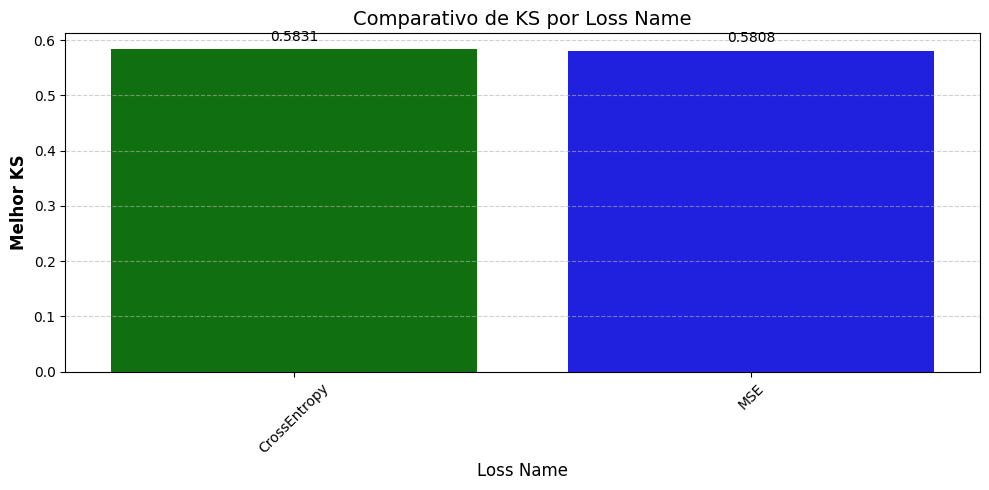



### OTIMIZAÇÃO MANUAL CONCLUÍDA COM SUCESSO! ###
O SEU MELHOR MODELO MANUAL (CAMPEÃO GERAL) É: MLP_Loss_1


In [ ]:
import time

# O que vamos variar nesta rodada: Loss
losses_teste = ['CrossEntropy', 'MSE']
resultados_rodada_8 = []

# Resgatando vencedores das rodadas anteriores
melhor_arq = vencedor_r1['hidden_layers']
melhor_lr = vencedor_r2['learning_rate']
melhor_ativacao = next(f for f in ativacoes_teste if f.__name__ == vencedor_r3['activation_function'])
melhor_batch = vencedor_r4['batch_size']
melhor_otimizador = vencedor_r5['optimizer_name']
melhor_wd = vencedor_r6['weight_decay']
melhor_dropout = vencedor_r7['dropout_rate']

print(f"Fixando -> Arq: {melhor_arq} | LR: {melhor_lr} | Ativ: {melhor_ativacao.__name__} | Batch: {melhor_batch} | Otimizador: {melhor_otimizador} | WD: {melhor_wd} | Dropout: {melhor_dropout}")

start_total = time.time()

for idx, loss_name in enumerate(losses_teste):
    nome_experimento = f"MLP_Loss_{idx+1}"

    resultado = executar_experimento_churn(
        name_experiment=nome_experimento,
        input_size=input_size,
        hidden_layers=melhor_arq,
        learning_rate=melhor_lr,
        batch_size=melhor_batch,
        num_epochs=MAX_EPOCHS,
        activation_function=melhor_ativacao,
        loss_name=loss_name,           # <--- Variável do loop
        optimizer_name=melhor_otimizador,
        weight_decay=melhor_wd,
        dropout_rate=melhor_dropout,
        X_train=X_train_final,
        y_train=y_train,
        X_val=X_val_final,
        y_val=y_val
    )
    resultados_rodada_8.append(resultado)

end_total = time.time()
tempo_minutos = (end_total - start_total) / 60
print(f"\n{'='*60}\nTEMPO TOTAL DA RODADA 8: {tempo_minutos:.2f} minutos\n{'='*60}\n")

df_resultados_r8 = pd.DataFrame(resultados_rodada_8)
df_resultados_r8.to_csv(os.path.join(caminho_logs, "rodada_8_loss.csv"), index=False)

vencedor_r8 = plotar_vencedor_churn(resultados_rodada_8, input_size, X_val_final, y_val, activation_function=melhor_ativacao)
plotar_evolucao_parametros(df_resultados_r8, 'loss_name')

print("\n\n### OTIMIZAÇÃO MANUAL CONCLUÍDA COM SUCESSO! ###")
print(f"O SEU MELHOR MODELO MANUAL (CAMPEÃO GERAL) É: {vencedor_r8['nome']}")

##Optuna

In [ ]:
!pip install optuna -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 20.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 40.4 MB/s eta 0:00:00


###Objective Function

In [ ]:
import optuna
import torch.nn as nn

def objective(trial):
    # 1. Sugestões de hiperparâmetros

    # Ranges contínuos para LR, Dropout e Weight Decay
    lr = trial.suggest_float("learning_rate", 1e-4, 1e-1, log=True)
    dropout = trial.suggest_float("dropout_rate", 0.0, 0.5)
    wd = trial.suggest_float("weight_decay", 1e-5, 1e-3, log=True)

    # Categóricos mantidos
    otimizador = trial.suggest_categorical("optimizer_name", ['Adam', 'SGD', 'RMSprop', 'Adadelta'])
    batch = trial.suggest_categorical("batch_size", [64, 128, 256])

    # Função de Perda (Nova adição)
    loss_name = trial.suggest_categorical("loss_name", ['CrossEntropy', 'MSE'])

    # Função de Ativação
    ativacao_str = trial.suggest_categorical("activation_function", ["ReLU", "Tanh", "Sigmoid", "LeakyReLU"])
    if ativacao_str == "ReLU":
        ativacao = nn.ReLU
    elif ativacao_str == "Tanh":
        ativacao = nn.Tanh
    elif ativacao_str == "Sigmoid":
        ativacao = nn.Sigmoid
    else:
        ativacao = nn.LeakyReLU

    # Arquiteturas: Menos densas, maioria 1 a 2 camadas, com apenas duas de 3 camadas
    arquiteturas = [
        [10], [16], [32], [64],           # 1 camada
        [16, 8], [32, 16], [64, 32],      # 2 camadas
        [32, 16, 8], [64, 32, 16]         # 3 camadas (menos densas)
    ]
    # O Optuna escolhe o índice da lista de arquiteturas
    arq_idx = trial.suggest_categorical("arquitetura_idx", range(len(arquiteturas)))
    camadas_ocultas = arquiteturas[arq_idx]

    nome_trial = f"Optuna_Trial_{trial.number}"

    # 2. Roda o experimento
    resultado = executar_experimento_churn(
        name_experiment=nome_trial,
        input_size=X_train_final.shape[1],
        hidden_layers=camadas_ocultas,
        learning_rate=lr,
        batch_size=batch,
        num_epochs=10000,
        activation_function=ativacao,
        loss_name=loss_name,
        optimizer_name=otimizador,
        weight_decay=wd,
        dropout_rate=dropout,
        X_train=X_train_final,
        y_train=y_train,
        X_val=X_val_final,
        y_val=y_val
    )

    # 3. Retorna o KS
    return resultado['val_ks']

###Run and Save

In [ ]:
# Cria um banco de dados no seu Google Drive para não perder nada
caminho_banco_optuna = f"sqlite:///{caminho_logs}/optuna_churn_study.db"

RECOMECAR_DO_ZERO = True # Mude para False se quiser continuar de onde parou futuramente

if RECOMECAR_DO_ZERO:
    try:
        optuna.delete_study(study_name="Otimizacao_MLP", storage=caminho_banco_optuna)
        print("Estudo anterior apagado do banco de dados. Começando do zero!")
    except KeyError:
        pass # Se não existir estudo para apagar, segue o jogo

# Definindo um sampler com seed fixa para garantir a reprodutibilidade do Optuna
sampler = optuna.samplers.TPESampler(seed=42)

# Cria o estudo com a diretriz de MAXIMIZAR a pontuação (porque queremos o maior KS)
study = optuna.create_study(
    study_name="Otimizacao_MLP",
    direction="maximize",
    storage=caminho_banco_optuna,
    sampler=sampler, # Adicionando o sampler com seed fixada
    load_if_exists=True # Se o banco já existir, ele continua de onde parou!
)

# Inicia a busca! (Você pode ajustar o n_trials para o quanto quiser esperar)
print("Iniciando otimização com Optuna...")
study.optimize(objective, n_trials=100)

# Lista de arquiteturas para traduzir o índice no print final
arquiteturas = [
    [10], [16], [32], [64],           # 1 camada
    [16, 8], [32, 16], [64, 32],      # 2 camadas
    [32, 16, 8], [64, 32, 16]         # 3 camadas
]

# Exibe o grande campeão
print("\n=== MELHOR MODELO ENCONTRADO PELO OPTUNA ===")
print(f"Melhor KS: {study.best_value:.4f}")
print("Melhores Parâmetros:")
for key, value in study.best_params.items():
    if key == 'arquitetura_idx':
        print(f"    arquitetura (camadas e neurônios): {arquiteturas[value]}")
    else:
        print(f"    {key}: {value}")


[I 2026-10-19 17:25:38,833] A new study created in RDB with name: Otimizacao_MLP


Estudo anterior apagado do banco de dados. Começando do zero!
Iniciando otimização com Optuna...

----------------------------------------------------------------------
EXPERIMENTO: Optuna_Trial_0 | Camadas: [16, 8] | LR: 0.0013292918943162175 | Batch: 64


Treinando:   0%|          | 35/10000 [00:02<12:18, 13.49it/s]
[I 2026-10-19 17:25:41,497] Trial 0 finished with value: 0.5730858468677494 and parameters: {'learning_rate': 0.0013292918943162175, 'dropout_rate': 0.4753571532049581, 'weight_decay': 0.000291063591313307, 'optimizer_name': 'Adam', 'batch_size': 64, 'loss_name': 'MSE', 'activation_function': 'ReLU', 'arquitetura_idx': 4}. Best is trial 0 with value: 0.5730858468677494.


 -> Early stopping acionado na época 36
Resultado Final - Val Loss: 0.1557 | Melhor KS: 0.5731 | Tempo: 2.60s

----------------------------------------------------------------------
EXPERIMENTO: Optuna_Trial_1 | Camadas: [32] | LR: 0.0226739865237804 | Batch: 256


Treinando:   0%|          | 28/10000 [00:00<05:39, 29.41it/s]
[I 2026-10-19 17:25:42,515] Trial 1 finished with value: 0.5699922660479505 and parameters: {'learning_rate': 0.0226739865237804, 'dropout_rate': 0.09983689107917987, 'weight_decay': 0.00010677482709481354, 'optimizer_name': 'RMSprop', 'batch_size': 256, 'loss_name': 'CrossEntropy', 'activation_function': 'Tanh', 'arquitetura_idx': 2}. Best is trial 0 with value: 0.5730858468677494.


 -> Early stopping acionado na época 29
Resultado Final - Val Loss: 0.4770 | Melhor KS: 0.5700 | Tempo: 0.95s

----------------------------------------------------------------------
EXPERIMENTO: Optuna_Trial_2 | Camadas: [64] | LR: 0.08105016126411585 | Batch: 256


... (192 outputs left out)

Treinando:   0%|          | 27/10000 [00:02<15:45, 10.55it/s]
[I 2026-10-19 18:18:24,828] Trial 98 finished with value: 0.5808197989172467 and parameters: {'learning_rate': 0.00020986526772199745, 'dropout_rate': 0.09494452490637044, 'weight_decay': 5.838830399169685e-05, 'optimizer_name': 'Adadelta', 'batch_size': 64, 'loss_name': 'MSE', 'activation_function': 'LeakyReLU', 'arquitetura_idx': 0}. Best is trial 30 with value: 0.5877803557617943.


 -> Early stopping acionado na época 28
Resultado Final - Val Loss: 0.1540 | Melhor KS: 0.5808 | Tempo: 2.56s

----------------------------------------------------------------------
EXPERIMENTO: Optuna_Trial_99 | Camadas: [16, 8] | LR: 0.0002528523674248048 | Batch: 64


Treinando:   0%|          | 33/10000 [00:03<15:24, 10.78it/s]
[I 2026-10-19 18:18:27,972] Trial 99 finished with value: 0.580046403712297 and parameters: {'learning_rate': 0.0002528523674248048, 'dropout_rate': 0.0029474082650175065, 'weight_decay': 6.064948714035932e-05, 'optimizer_name': 'Adadelta', 'batch_size': 64, 'loss_name': 'MSE', 'activation_function': 'LeakyReLU', 'arquitetura_idx': 4}. Best is trial 30 with value: 0.5877803557617943.


 -> Early stopping acionado na época 34
Resultado Final - Val Loss: 0.1539 | Melhor KS: 0.5800 | Tempo: 3.06s

=== MELHOR MODELO ENCONTRADO PELO OPTUNA ===
Melhor KS: 0.5878
Melhores Parâmetros:
    learning_rate: 0.0003776133951950038
    dropout_rate: 0.05694596079714935
    weight_decay: 4.829980337167137e-05
    optimizer_name: Adadelta
    batch_size: 64
    loss_name: MSE
    activation_function: LeakyReLU
    arquitetura (camadas e neurônios): [10]


###Evaluate Best Model

Calculando e plotando métricas para o Grande Campeão do Optuna...

VENCEDOR DA BATERIA: Optuna_Trial_30 (KS Máximo: 0.5878)


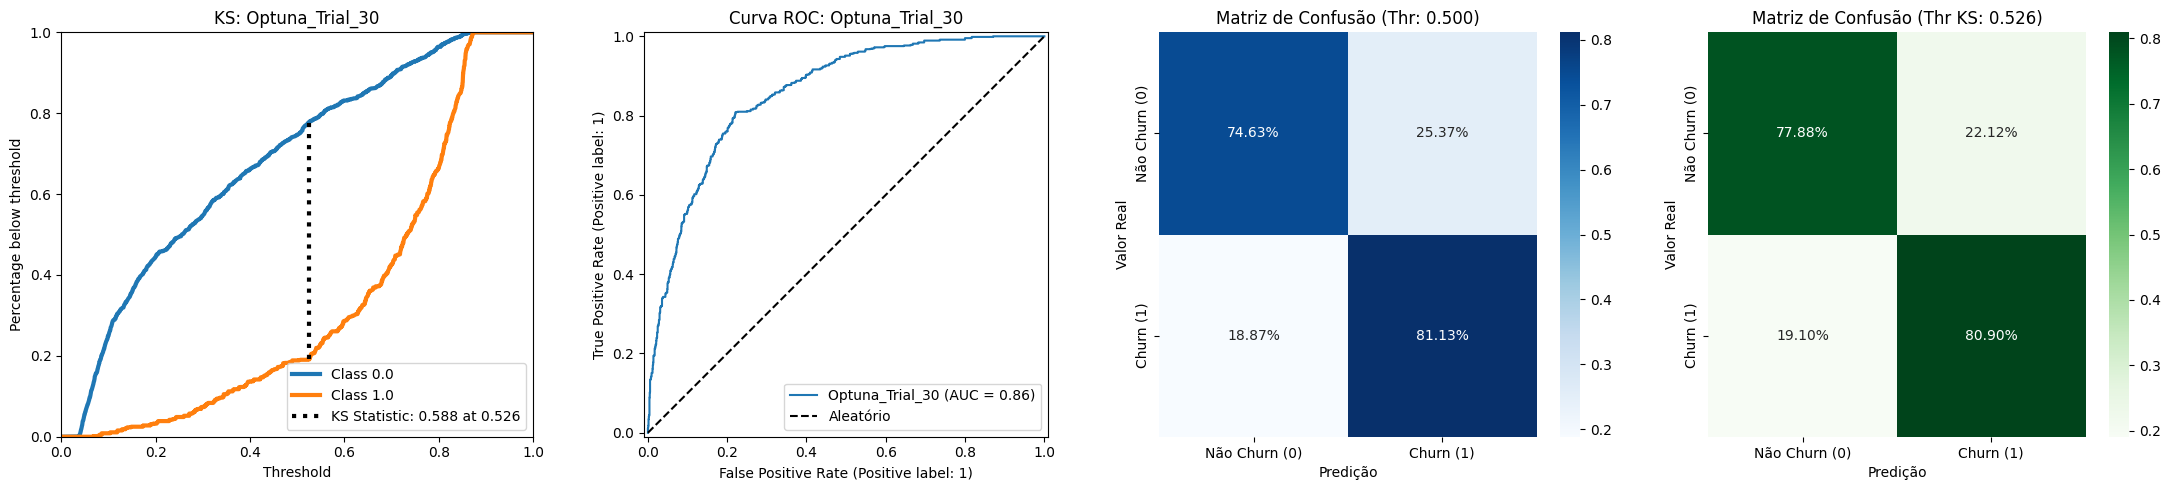

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5878 | AUROC: 0.8568 | Acurácia: 0.7788
Precisão: 0.7618 | Recall: 0.8113 | F1-Score: 0.7858

Relatório de Classificação (Threshold Padrão):
               precision    recall  f1-score   support

Não Churn (0)       0.80      0.75      0.77      1293
    Churn (1)       0.76      0.81      0.79      1293

     accuracy                           0.78      2586
    macro avg       0.78      0.78      0.78      2586
 weighted avg       0.78      0.78      0.78      2586


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.526) ---
KS: 0.5878 | AUROC: 0.8568 | Acurácia: 0.7939
Precisão: 0.7853 | Recall: 0.8090 | F1-Score: 0.7970

Relatório de Classificação (Threshold Otimizado):
               precision    recall  f1-score   support

Não Churn (0)       0.80      0.78      0.79      1293
    Churn (1)       0.79      0.81      0.80      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79

In [ ]:
import optuna
import torch.nn as nn

# Carrega o estudo já salvo no banco de dados
caminho_banco_optuna = f"sqlite:///{caminho_logs}/optuna_churn_study.db"
study_loaded = optuna.load_study(study_name="Otimizacao_MLP", storage=caminho_banco_optuna)

# Lista de arquiteturas usada no Optuna
arquiteturas_optuna = [
    [10], [16], [32], [64],           # 1 camada
    [16, 8], [32, 16], [64, 32],      # 2 camadas
    [32, 16, 8], [64, 32, 16]         # 3 camadas
]

best_trial = study_loaded.best_trial

# Recriando o dicionário do vencedor para ser compatível com a função plotar_vencedor_churn
resultado_campeao_optuna = {
    'nome': f"Optuna_Trial_{best_trial.number}",
    'val_ks': best_trial.value,
    'hidden_layers': arquiteturas_optuna[best_trial.params['arquitetura_idx']],
    'batch_size': best_trial.params['batch_size'],
    'dropout_rate': best_trial.params['dropout_rate']
}

# Recuperando a função de ativação utilizada no melhor modelo
ativacao_str = best_trial.params['activation_function']
if ativacao_str == "ReLU":
    ativacao_campeao = nn.ReLU
elif ativacao_str == "Tanh":
    ativacao_campeao = nn.Tanh
elif ativacao_str == "Sigmoid":
    ativacao_campeao = nn.Sigmoid
else:
    ativacao_campeao = nn.LeakyReLU

print("Calculando e plotando métricas para o Grande Campeão do Optuna...")
# Chamando a função de plotagem (ela vai carregar os pesos do drive e avaliar)
_ = plotar_vencedor_churn(
    [resultado_campeao_optuna],
    input_size=X_train_final.shape[1],
    X_val=X_val_final,
    y_val=y_val,
    activation_function=ativacao_campeao
)

# Feature Engineering para Churn de Telecom

Antes de treinar a rede, você pode criar novas colunas no seu DataFrame original (`df`). Aqui estão algumas ideias que costumam funcionar muito bem para este dataset:

1. **Contagem de Serviços Contratados:** Clientes com muitos serviços (Segurança, Backup, Suporte, etc.) tendem a ser mais fiéis. Você pode criar uma coluna `Qtd_Servicos` somando quantos 'Yes' o cliente tem nas colunas de serviço.
2. **Proporção de Gasto:** Uma feature como `Gasto_Medio_Real = TotalCharges / tenure`. Se o valor for muito diferente do `MonthlyCharges`, pode indicar um aumento recente de preço que gerou insatisfação (churn).
3. **Agrupamento de Tenure (Binning):** Em vez de tratar os meses de forma contínua, transformar em categorias: `Novo (0-12m)`, `Fiel (13-48m)`, `Veterano (>48m)`. Muitas vezes a rede neural acha padrões mais fáceis assim.
4. **Família (Dependents + Partner):** Uma feature binária `Tem_Familia` (1 se Partner=='Yes' OU Dependents=='Yes', caso contrário 0).

### Análise de Normalidade das Variáveis Numéricas
Abaixo, vamos testar estatisticamente se `tenure`, `MonthlyCharges` e `TotalCharges` seguem uma Distribuição Normal.

=== TESTE DE NORMALIDADE (D'Agostino-Pearson) ===

H0: A amostra vem de uma distribuição normal.
H1: A amostra NÃO vem de uma distribuição normal.

--- tenure ---
Estatística: 53312.1369 | p-value: 0.0000e+00
❌ Conclusão: NÃO PARECE NORMAL (Assimétrica/Multimodal).
   -> Recomendação: Manter MinMaxScaler() ou usar RobustScaler()
----------------------------------------
--- MonthlyCharges ---
Estatística: 5621.8206 | p-value: 0.0000e+00
❌ Conclusão: NÃO PARECE NORMAL (Assimétrica/Multimodal).
   -> Recomendação: Manter MinMaxScaler() ou usar RobustScaler()
----------------------------------------
--- TotalCharges ---
Estatística: 408.0651 | p-value: 2.4535e-89
❌ Conclusão: NÃO PARECE NORMAL (Assimétrica/Multimodal).
   -> Recomendação: Manter MinMaxScaler() ou usar RobustScaler()
----------------------------------------


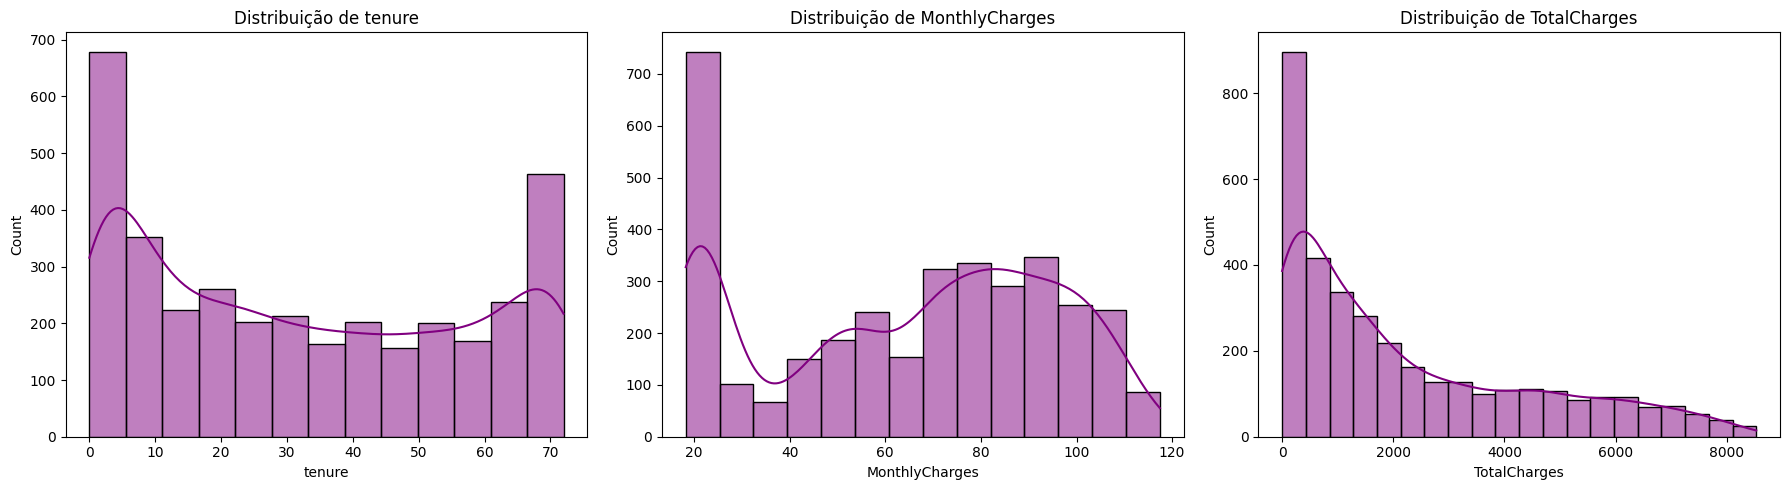

In [ ]:
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Variáveis contínuas que queremos testar
num_cols_to_test = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

print("=== TESTE DE NORMALIDADE (D'Agostino-Pearson) ===\n")
print("H0: A amostra vem de uma distribuição normal.")
print("H1: A amostra NÃO vem de uma distribuição normal.\n")

for i, col in enumerate(num_cols_to_test):
    # Pega os dados de treino (já sem nulos devido aos tratamentos anteriores)
    data = df_train[col].dropna()

    # Plota o histograma com a curva de densidade (KDE)
    sns.histplot(data, kde=True, ax=axes[i], color='purple')
    axes[i].set_title(f'Distribuição de {col}')

    # Teste estatístico normaltest (ideal para N > 20)
    stat, p_value = stats.normaltest(data)

    print(f"--- {col} ---")
    print(f"Estatística: {stat:.4f} | p-value: {p_value:.4e}")

    # Se p-value < 0.05, rejeitamos a hipótese nula (H0)
    if p_value > 0.05:
        print("✅ Conclusão: PARECE NORMAL (Gaussiana).")
        print("   -> Recomendação: Usar StandardScaler()")
    else:
        print("❌ Conclusão: NÃO PARECE NORMAL (Assimétrica/Multimodal).")
        print("   -> Recomendação: Manter MinMaxScaler() ou usar RobustScaler()")
    print("-" * 40)

plt.tight_layout()
plt.show()

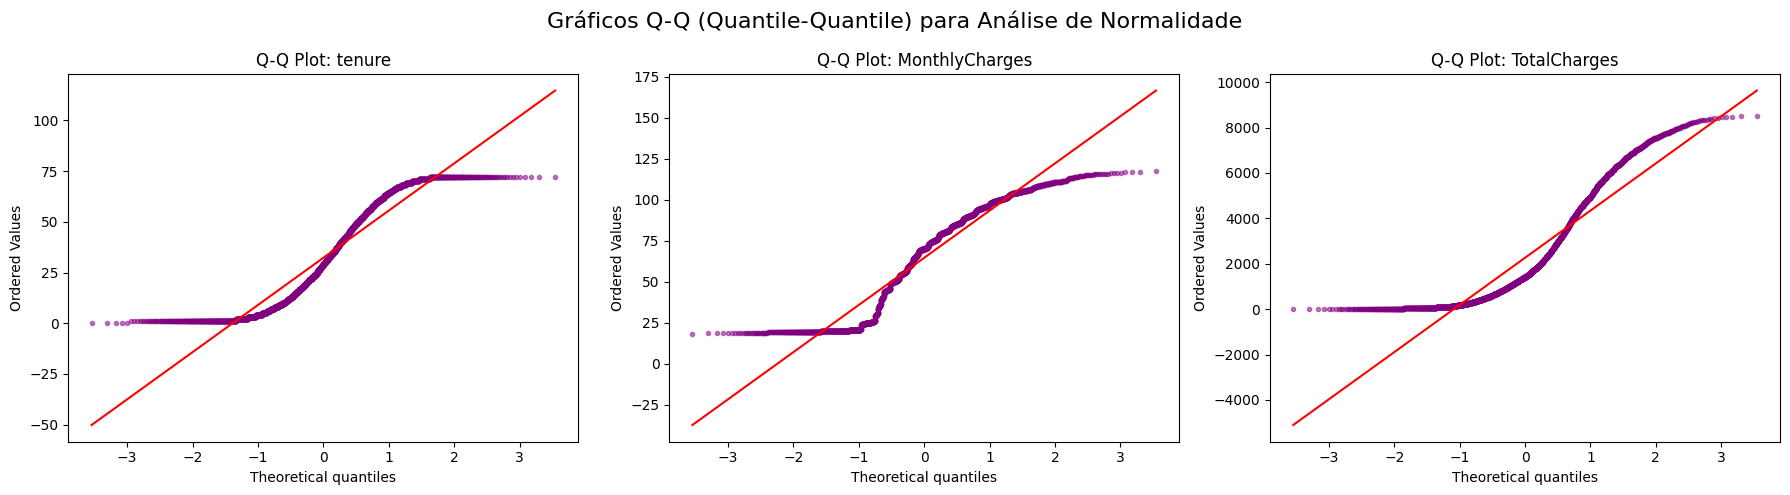

In [ ]:
import scipy.stats as stats
import matplotlib.pyplot as plt

# Variáveis contínuas que queremos testar
num_cols_to_test = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Gráficos Q-Q (Quantile-Quantile) para Análise de Normalidade", fontsize=16)

for i, col in enumerate(num_cols_to_test):
    # Pega os dados de treino (já sem nulos devido aos tratamentos anteriores)
    data = df_train[col].dropna()

    # Plota o Q-Q Plot
    stats.probplot(data, dist="norm", plot=axes[i])

    # Personalização do gráfico para combinar com a cor anterior
    axes[i].set_title(f'Q-Q Plot: {col}')
    axes[i].get_lines()[0].set_markerfacecolor('purple')
    axes[i].get_lines()[0].set_markeredgecolor('purple')
    axes[i].get_lines()[0].set_markersize(3)
    axes[i].get_lines()[0].set_alpha(0.5)

plt.tight_layout()
plt.show()

Como você poderá ver pelo resultado do teste acima, é muito comum que variáveis de negócio (como dinheiro e tempo de contrato) **não** sigam uma distribuição normal perfeita. Elas costumam ter caldas longas (assimetria) ou picos em extremos (bimodais).

Se o teste der negativo para todas, você já está usando a melhor abordagem com o `MinMaxScaler()`. Caso alguma dê positivo (Gaussiana), você poderia dividir o `ColumnTransformer` (na célula de Pipeline) para aplicar o `StandardScaler` apenas nela, e o `MinMaxScaler` nas outras!

##Função de Plotagem de Comparação

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def plot_feature_engineering_comparison(name_fe, ks_r7_base, ks_r7_fe, ks_optuna_base, ks_optuna_fe):
    """
    Cria um gráfico de barras comparando os resultados de KS antes e depois
    da feature engineering, para os cenários manual (R7) e Optuna.
    """
    labels = ['Manual (R7) - Sem FE', f'Manual (R7) - Com {name_fe}',
              'Optuna - Sem FE', f'Optuna - Com {name_fe}']
    ks_values = [ks_r7_base, ks_r7_fe, ks_optuna_base, ks_optuna_fe]

    cores = ['lightsteelblue', 'royalblue', 'lightgreen', 'forestgreen']

    fig, ax = plt.subplots(figsize=(10, 6))
    barras = ax.bar(labels, ks_values, color=cores)

    # Adicionando os valores em cima das barras
    for bar in barras:
        height = bar.get_height()
        ax.annotate(f'{height:.4f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=11)

    ax.set_ylim(min(ks_values) - 0.01, max(ks_values) + 0.01)
    ax.set_ylabel('Estatística KS', fontsize=12)
    ax.set_title(f'Impacto da Feature: {name_fe}', fontsize=14, pad=15)

    # Melhorando os labels do eixo X para não ficarem amontoados
    plt.xticks(rotation=15, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

print("Função de plotagem de comparação criada com sucesso!")

Função de plotagem de comparação criada com sucesso!


 Respostas sobre Metodologia de Feature Engineering

**1) Um por vez ou tudo de uma vez?**
O ideal é testar **uma feature por vez** (ou grupos lógicos muito pequenos). Isso se chama *Estudo de Ablação (Ablation Study)*. Se você colocar 5 features de uma vez e o modelo piorar (ou melhorar), você não saberá qual feature foi a responsável. Adicionando uma a uma, você tem certeza de quais agregam valor ao modelo.

**2) Manter as colunas originais ou apagá-las?**
**Mantenha as colunas originais!** Redes Neurais são excelentes em encontrar relações complexas não-lineares. Manter os serviços originais permite que a rede entenda, por exemplo, que ter *TechSupport* importa mais do que *StreamingTV*. A nova coluna `Qtde_Servicos` funciona apenas como um "atalho mental" mastigado para a rede, facilitando a convergência.

**3) Testar no modelo manual campeão ou no Optuna?**
**Seu raciocínio está perfeito!** O fluxo correto é:
1. Use o hiperparâmetro fixo do seu **Campeão da Rodada 7** para testar as features. Como a arquitetura e a semente estão congeladas, qualquer variação no KS será mérito (ou culpa) exclusivo da nova feature.
2. Se a feature melhorar o modelo, ela fica no dataset. Se piorar, você a descarta.
3. Após testar e aprovar suas novas features, aí sim você **roda o Optuna** novamente para encontrar os novos hiperparâmetros ideais para este "novo dataset enriquecido".

### Setup para os Testes de Feature Engineering (Ablation Study)

Rode esta célula **uma vez** antes de testar qualquer FE. Ela carrega os hiperparâmetros do seu melhor modelo Manual (Rodada 7) e do melhor modelo Optuna direto do Drive, para que você possa rodar os testes de FE em qualquer ordem.

In [ ]:
import pandas as pd
import ast
import optuna
import torch.nn as nn
import os

# --- 1. Carregando Hiperparâmetros do Campeão Manual (Rodada 8) ---
print("Carregando parâmetros do Campeão Manual (R8)...")
caminho_csv_r8 = os.path.join(caminho_logs, "rodada_8_loss.csv")
df_r8 = pd.read_csv(caminho_csv_r8)
melhor_linha_r8 = df_r8.loc[df_r8['val_ks'].idxmax()]
vencedor_r8 = melhor_linha_r8.to_dict()
# Convertendo a string da lista de volta para lista real
vencedor_r8['hidden_layers'] = ast.literal_eval(vencedor_r8['hidden_layers'])

ativacoes_teste = [nn.ReLU, nn.Tanh, nn.Sigmoid, nn.LeakyReLU]
ativacao_campeao_r8 = next(f for f in ativacoes_teste if f.__name__ == vencedor_r8['activation_function'])
ks_r8_base = vencedor_r8['val_ks']

# --- 2. Carregando Hiperparâmetros do Campeão Optuna (Base) ---
print("Carregando parâmetros do Campeão Optuna Base...")
caminho_banco_optuna = f"sqlite:///{caminho_logs}/optuna_churn_study.db"
study_loaded = optuna.load_study(study_name="Otimizacao_MLP", storage=caminho_banco_optuna)
best_trial = study_loaded.best_trial

ativacao_campeao_optuna = next(f for f in ativacoes_teste if f.__name__ == best_trial.params['activation_function'])

arquiteturas_optuna = [
    [10], [16], [32], [64],
    [16, 8], [32, 16], [64, 32],
    [32, 16, 8], [64, 32, 16]
]
arq_campeao = arquiteturas_optuna[best_trial.params['arquitetura_idx']]
ks_optuna_base = best_trial.value

# --- 3. Função Unificada para Rodar Optuna e Avaliar Feature Engineering ---
def rodar_optuna_e_avaliar(nome_estudo, X_train, y_train, X_val, y_val, prefixo_trial="Optuna_Trial"):
    caminho_banco = f"sqlite:///{caminho_logs}/{nome_estudo.lower()}.db"

    def objective(trial):
        lr = trial.suggest_float("learning_rate", 1e-4, 1e-1, log=True)
        dropout = trial.suggest_float("dropout_rate", 0.0, 0.5)
        wd = trial.suggest_float("weight_decay", 1e-5, 1e-3, log=True)
        otimizador = trial.suggest_categorical("optimizer_name", ['Adam', 'SGD', 'RMSprop', 'Adadelta'])
        batch = trial.suggest_categorical("batch_size", [64, 128, 256])
        loss_name = trial.suggest_categorical("loss_name", ['CrossEntropy', 'MSE'])

        ativacao_str = trial.suggest_categorical("activation_function", ["ReLU", "Tanh", "Sigmoid", "LeakyReLU"])
        if ativacao_str == "ReLU": ativacao = nn.ReLU
        elif ativacao_str == "Tanh": ativacao = nn.Tanh
        elif ativacao_str == "Sigmoid": ativacao = nn.Sigmoid
        else: ativacao = nn.LeakyReLU

        arquiteturas = [
            [10], [16], [32], [64],
            [16, 8], [32, 16], [64, 32],
            [32, 16, 8], [64, 32, 16]
        ]
        arq_idx = trial.suggest_categorical("arquitetura_idx", range(len(arquiteturas)))
        camadas_ocultas = arquiteturas[arq_idx]

        nome_trial = f"{prefixo_trial}_{trial.number}"

        resultado = executar_experimento_churn(
            name_experiment=nome_trial,
            input_size=X_train.shape[1],
            hidden_layers=camadas_ocultas,
            learning_rate=lr,
            batch_size=batch,
            num_epochs=10000,
            activation_function=ativacao,
            loss_name=loss_name,
            optimizer_name=otimizador,
            weight_decay=wd,
            dropout_rate=dropout,
            X_train=X_train,
            y_train=y_train,
            X_val=X_val,
            y_val=y_val
        )
        return resultado['val_ks']

    RECOMECAR_DO_ZERO = True
    if RECOMECAR_DO_ZERO:
        try:
            optuna.delete_study(study_name=nome_estudo, storage=caminho_banco)
            print(f"Estudo {nome_estudo} apagado do banco de dados. Começando do zero!")
        except KeyError:
            pass

    sampler = optuna.samplers.TPESampler(seed=42)
    study = optuna.create_study(
        study_name=nome_estudo,
        direction="maximize",
        storage=caminho_banco,
        sampler=sampler,
        load_if_exists=True
    )

    print(f"Iniciando Optuna para: {nome_estudo}...")
    study.optimize(objective, n_trials=100)

    arquiteturas = [
        [10], [16], [32], [64],
        [16, 8], [32, 16], [64, 32],
        [32, 16, 8], [64, 32, 16]
    ]

    print(f"\n=== MELHOR MODELO ENCONTRADO ({nome_estudo}) ===")
    print(f"Melhor KS: {study.best_value:.4f}")
    print("Melhores Parâmetros:")
    for key, value in study.best_params.items():
        if key == 'arquitetura_idx':
            print(f"    arquitetura: {arquiteturas[value]}")
        else:
            print(f"    {key}: {value}")

    # --- AVALIAÇÃO FINAL (VENCEDOR) ---
    best_trial = study.best_trial
    resultado_campeao = {
        'nome': f"{prefixo_trial}_{best_trial.number}",
        'val_ks': best_trial.value,
        'hidden_layers': arquiteturas[best_trial.params['arquitetura_idx']],
        'batch_size': best_trial.params['batch_size'],
        'dropout_rate': best_trial.params['dropout_rate']
    }

    ativacao_str = best_trial.params['activation_function']
    if ativacao_str == "ReLU": ativacao_campeao = nn.ReLU
    elif ativacao_str == "Tanh": ativacao_campeao = nn.Tanh
    elif ativacao_str == "Sigmoid": ativacao_campeao = nn.Sigmoid
    else: ativacao_campeao = nn.LeakyReLU

    print(f"\nCalculando e plotando métricas para o Grande Campeão ({nome_estudo})...")
    plotar_vencedor_churn(
        [resultado_campeao],
        input_size=X_train.shape[1],
        X_val=X_val,
        y_val=y_val,
        activation_function=ativacao_campeao
    )

    return study

print("\nSetup concluído! Agora você pode rodar os blocos FE_1, FE_2, FE_3, FE_4 ou FE_ALL independentemente.")

Carregando parâmetros do Campeão Manual (R8)...
Carregando parâmetros do Campeão Optuna Base...

Setup concluído! Agora você pode rodar os blocos FE_1, FE_2, FE_3, FE_4 ou FE_ALL independentemente.


##FE_1: Qtde_Servicos

In [ ]:
# --- Após a carga e limpeza inicial ---
df_base = df.copy()

colunas_categoricas_base = df_base.select_dtypes(include=['object']).columns.tolist()
colunas_categoricas_base.append('SeniorCitizen')

colunas_numericas_base = df_base.select_dtypes(include=['int16', 'int32', 'int64', 'float16', 'float32', 'float64']).columns.tolist()
colunas_numericas_base.remove('SeniorCitizen')

In [ ]:
# 1. Puxa a cópia da base virgem e das listas
df_fe1 = df_base.copy()
cols_cat_fe1 = colunas_categoricas_base.copy()
cols_num_fe1 = colunas_numericas_base.copy()

# 2. Aplica a transformação
colunas_servicos = [
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies'
]
df_fe1['Qtde_Servicos'] = df_fe1[colunas_servicos].apply(lambda linha: (linha == 'Yes').sum(), axis=1)

# 3. Adiciona APENAS na lista temporária deste escopo
if 'Qtde_Servicos' not in cols_num_fe1:
    cols_num_fe1.append('Qtde_Servicos')

display(df_fe1.head())

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Qtde_Servicos
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,1
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,2
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,2
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,3
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0


### Avaliação da Feature Engineering 1: Qtde_Servicos
Agora que a feature foi criada no `df` original e adicionada à lista `colunas_numericas`, vamos recriar nossos datasets de treino/validação e testar o impacto.

In [ ]:
# 4. Refaz o Split e o Pipeline usando os dados e colunas isolados
print("Refazendo Split e Pre-processamento...")
df_train_fe1, df_val_fe1, df_test_fe1 = realizar_split(df_fe1)

X_train_fe1, y_train_fe1, X_val_fe1, y_val_fe1, X_test_fe1, y_test_fe1 = aplicar_pipeline_e_oversampling(
    df_train_fe1, df_val_fe1, df_test_fe1, cols_cat_fe1, cols_num_fe1
)

print(f"Tamanho de features de treino: {X_train_fe1.shape[1]} colunas.")

Refazendo Split e Pre-processamento...
Tamanho de features de treino: 41 colunas.


Treinando modelo de Ablação com os parâmetros do Campeão Manual da Rodada 8...

----------------------------------------------------------------------
EXPERIMENTO: MLP_FE_Qtde_Servicos_BaseR8 | Camadas: [16] | LR: 0.0001 | Batch: 32


Treinando:   1%|          | 121/10000 [00:13<17:57,  9.17it/s]


 -> Early stopping acionado na época 122
Resultado Final - Val Loss: 0.4707 | Melhor KS: 0.5785 | Tempo: 13.19s

VENCEDOR DA BATERIA: MLP_FE_Qtde_Servicos_BaseR8 (KS Máximo: 0.5785)


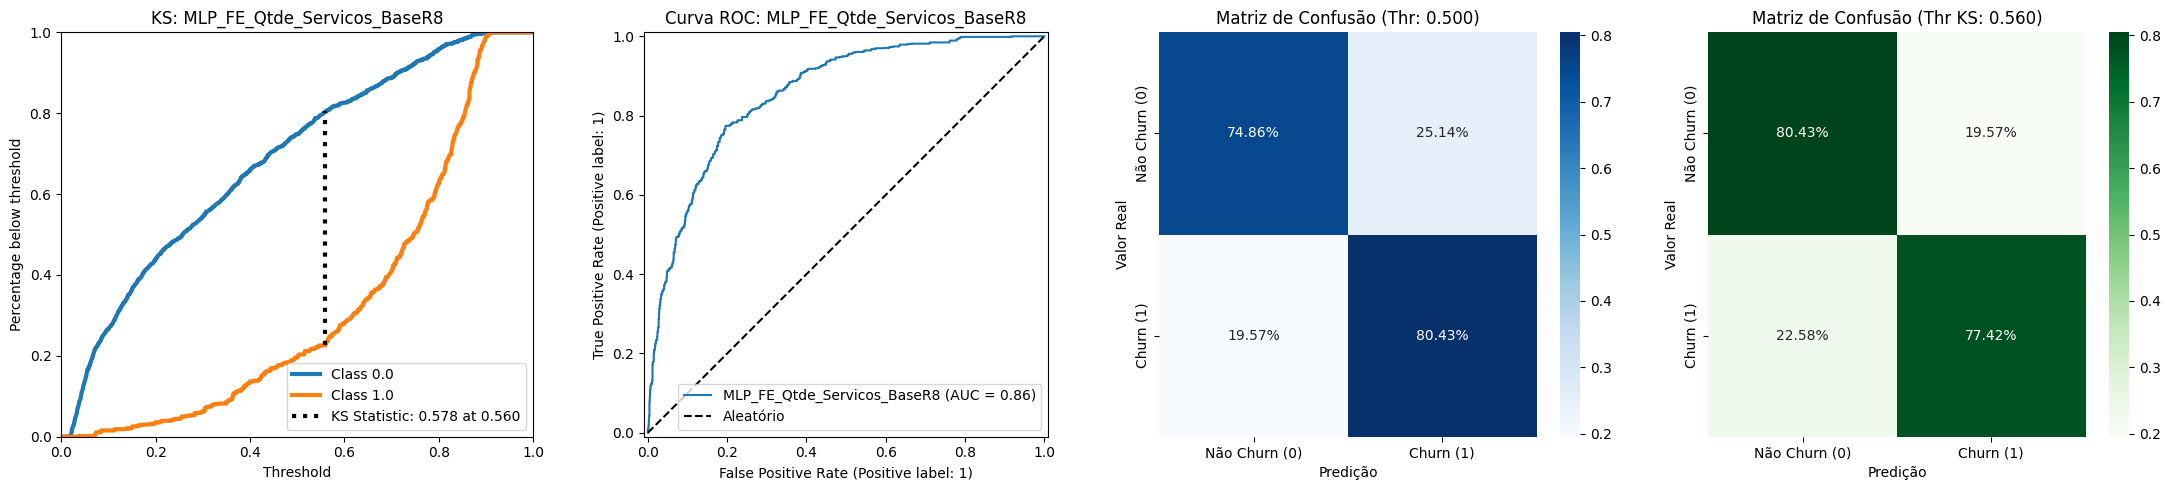

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5785 | AUROC: 0.8573 | Acurácia: 0.7765
Precisão: 0.7619 | Recall: 0.8043 | F1-Score: 0.7825

Relatório de Classificação (Threshold Padrão):
               precision    recall  f1-score   support

Não Churn (0)       0.79      0.75      0.77      1293
    Churn (1)       0.76      0.80      0.78      1293

     accuracy                           0.78      2586
    macro avg       0.78      0.78      0.78      2586
 weighted avg       0.78      0.78      0.78      2586


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.560) ---
KS: 0.5785 | AUROC: 0.8573 | Acurácia: 0.7892
Precisão: 0.7982 | Recall: 0.7742 | F1-Score: 0.7860

Relatório de Classificação (Threshold Otimizado):
               precision    recall  f1-score   support

Não Churn (0)       0.78      0.80      0.79      1293
    Churn (1)       0.80      0.77      0.79      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79

Treinando:   0%|          | 39/10000 [00:03<13:49, 12.00it/s]


 -> Early stopping acionado na época 40
Resultado Final - Val Loss: 0.4706 | Melhor KS: 0.5708 | Tempo: 3.25s

VENCEDOR DA BATERIA: MLP_FE_Qtde_Servicos_BaseOptuna (KS Máximo: 0.5708)


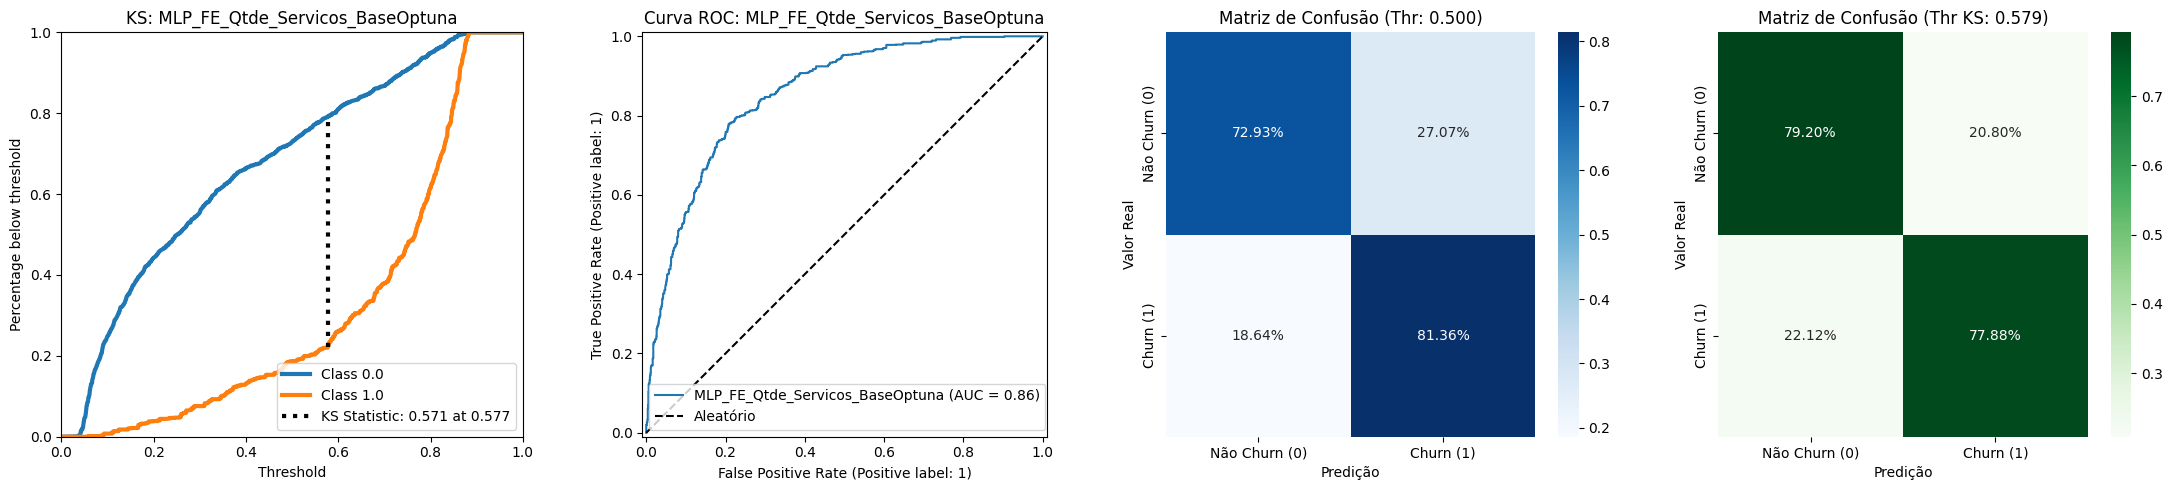

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5708 | AUROC: 0.8552 | Acurácia: 0.7715
Precisão: 0.7504 | Recall: 0.8136 | F1-Score: 0.7807

Relatório de Classificação (Threshold Padrão):
               precision    recall  f1-score   support

Não Churn (0)       0.80      0.73      0.76      1293
    Churn (1)       0.75      0.81      0.78      1293

     accuracy                           0.77      2586
    macro avg       0.77      0.77      0.77      2586
 weighted avg       0.77      0.77      0.77      2586


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.579) ---
KS: 0.5708 | AUROC: 0.8552 | Acurácia: 0.7854
Precisão: 0.7892 | Recall: 0.7788 | F1-Score: 0.7840

Relatório de Classificação (Threshold Otimizado):
               precision    recall  f1-score   support

Não Churn (0)       0.78      0.79      0.79      1293
    Churn (1)       0.79      0.78      0.78      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79

In [ ]:
import pandas as pd
import ast
import optuna
import torch.nn as nn
import os

# --- PARTE 1: Experimento com os melhores parâmetros manuais (Rodada 8) ---
print("Treinando modelo de Ablação com os parâmetros do Campeão Manual da Rodada 8...")

resultado_fe_manual = executar_experimento_churn(
    name_experiment="MLP_FE_Qtde_Servicos_BaseR8",
    input_size=X_train_fe1.shape[1],
    hidden_layers=vencedor_r8['hidden_layers'],
    learning_rate=vencedor_r8['learning_rate'],
    batch_size=int(vencedor_r8['batch_size']),
    num_epochs=10000,
    activation_function=ativacao_campeao_r8,
    loss_name=vencedor_r8.get('loss_name', 'CrossEntropy'),
    optimizer_name=vencedor_r8['optimizer_name'],
    weight_decay=vencedor_r8['weight_decay'],
    dropout_rate=vencedor_r8['dropout_rate'],
    X_train=X_train_fe1,
    y_train=y_train_fe1,
    X_val=X_val_fe1,
    y_val=y_val_fe1
)

# Plotamos o resultado
_ = plotar_vencedor_churn([resultado_fe_manual], X_train_fe1.shape[1], X_val_fe1, y_val_fe1, activation_function=ativacao_campeao_r8)

print("\n" + "="*50)
print(f"KS Anterior (Campeão R8 sem feature): {ks_r8_base:.4f}")
print(f"KS Atual (Campeão R8 com feature): {resultado_fe_manual['val_ks']:.4f}")
print("="*50)


# --- PARTE 2: Experimento com os melhores parâmetros do Optuna (Lendo do Drive) ---
print("\n\nTreinando modelo de Ablação com os parâmetros do Campeão do Optuna (Lido do Drive)...")

caminho_banco_optuna = f"sqlite:///{caminho_logs}/optuna_churn_study.db"
study_loaded = optuna.load_study(study_name="Otimizacao_MLP", storage=caminho_banco_optuna)
best_trial = study_loaded.best_trial

ativacao_campeao_optuna = next(f for f in ativacoes_teste if f.__name__ == best_trial.params['activation_function'])

arquiteturas_optuna = [
    [10], [16], [32], [64],
    [16, 8], [32, 16], [64, 32],
    [32, 16, 8], [64, 32, 16]
]
arq_campeao = arquiteturas_optuna[best_trial.params['arquitetura_idx']]

resultado_fe_optuna = executar_experimento_churn(
    name_experiment="MLP_FE_Qtde_Servicos_BaseOptuna",
    input_size=X_train_fe1.shape[1],
    hidden_layers=arq_campeao,
    learning_rate=best_trial.params['learning_rate'],
    batch_size=best_trial.params['batch_size'],
    num_epochs=10000,
    activation_function=ativacao_campeao_optuna,
    loss_name=best_trial.params.get('loss_name', 'CrossEntropy'),
    optimizer_name=best_trial.params['optimizer_name'],
    weight_decay=best_trial.params['weight_decay'],
    dropout_rate=best_trial.params['dropout_rate'],
    X_train=X_train_fe1,
    y_train=y_train_fe1,
    X_val=X_val_fe1,
    y_val=y_val_fe1
)

_ = plotar_vencedor_churn([resultado_fe_optuna], X_train_fe1.shape[1], X_val_fe1, y_val_fe1, activation_function=ativacao_campeao_optuna)

print("\n" + "="*50)
print(f"KS Anterior (Campeão Optuna sem feature): {best_trial.value:.4f}")
print(f"KS Atual (Campeão Optuna com feature): {resultado_fe_optuna['val_ks']:.4f}")
print("="*50)


### Comparação Visual: Qtde_Servicos

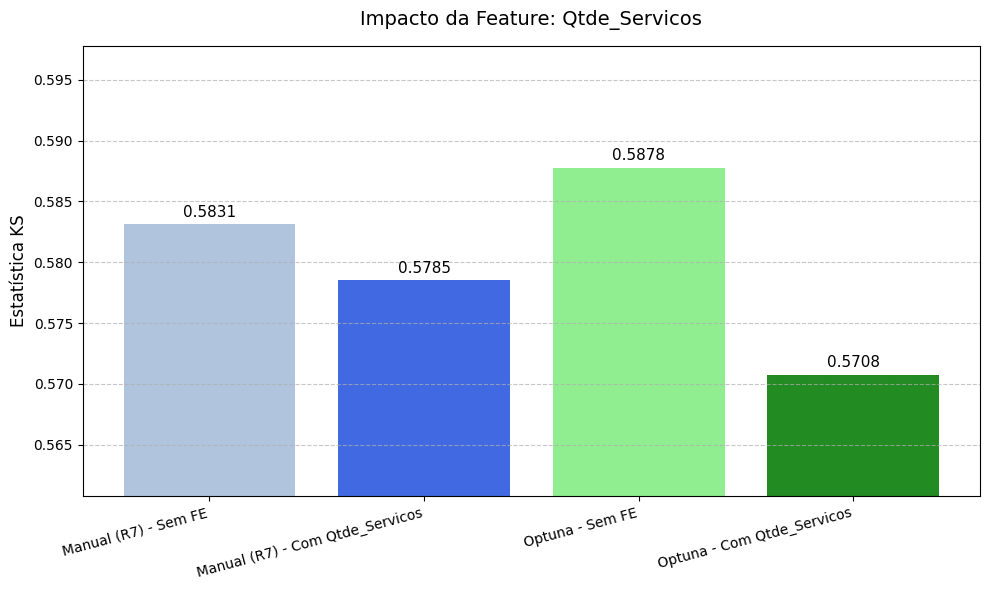

In [ ]:
# O KS base do R8 estava na variável ks_r8_base (que lemos do log na célula de setup)
ks_r8_fe1 = resultado_fe_manual['val_ks']

# O KS base do Optuna estava na variável best_trial.value
ks_optuna_base = best_trial.value
ks_optuna_fe1 = resultado_fe_optuna['val_ks']

plot_feature_engineering_comparison(
    name_fe='Qtde_Servicos',
    ks_r7_base=ks_r8_base, # Usando a base global da rodada 8
    ks_r7_fe=ks_r8_fe1,
    ks_optuna_base=ks_optuna_base,
    ks_optuna_fe=ks_optuna_fe1
)


### Optuna FE_1 (Qtde_Servicos)

[I 2026-10-19 18:20:05,787] A new study created in RDB with name: Otimizacao_MLP_FE1


Iniciando Optuna para: Otimizacao_MLP_FE1...

----------------------------------------------------------------------
EXPERIMENTO: Optuna_FE1_Trial_0 | Camadas: [16, 8] | LR: 0.0013292918943162175 | Batch: 64


Treinando:   1%|          | 53/10000 [00:04<14:26, 11.47it/s]
[I 2026-10-19 18:20:10,499] Trial 0 finished with value: 0.57153905645785 and parameters: {'learning_rate': 0.0013292918943162175, 'dropout_rate': 0.4753571532049581, 'weight_decay': 0.000291063591313307, 'optimizer_name': 'Adam', 'batch_size': 64, 'loss_name': 'MSE', 'activation_function': 'ReLU', 'arquitetura_idx': 4}. Best is trial 0 with value: 0.57153905645785.


 -> Early stopping acionado na época 54
Resultado Final - Val Loss: 0.1554 | Melhor KS: 0.5715 | Tempo: 4.62s

----------------------------------------------------------------------
EXPERIMENTO: Optuna_FE1_Trial_1 | Camadas: [32] | LR: 0.0226739865237804 | Batch: 256


Treinando:   0%|          | 46/10000 [00:02<07:18, 22.71it/s]
[I 2026-10-19 18:20:12,596] Trial 1 finished with value: 0.5738592420726991 and parameters: {'learning_rate': 0.0226739865237804, 'dropout_rate': 0.09983689107917987, 'weight_decay': 0.00010677482709481354, 'optimizer_name': 'RMSprop', 'batch_size': 256, 'loss_name': 'CrossEntropy', 'activation_function': 'Tanh', 'arquitetura_idx': 2}. Best is trial 1 with value: 0.5738592420726991.


 -> Early stopping acionado na época 47
Resultado Final - Val Loss: 0.4756 | Melhor KS: 0.5739 | Tempo: 2.03s

----------------------------------------------------------------------
EXPERIMENTO: Optuna_FE1_Trial_2 | Camadas: [64] | LR: 0.08105016126411585 | Batch: 256


... (192 outputs left out)

Treinando:   0%|          | 46/10000 [00:02<08:29, 19.53it/s]
[I 2026-10-19 18:45:12,502] Trial 98 finished with value: 0.576952822892498 and parameters: {'learning_rate': 0.0021434608870755144, 'dropout_rate': 0.49755272892610425, 'weight_decay': 0.0007770044930880316, 'optimizer_name': 'RMSprop', 'batch_size': 256, 'loss_name': 'MSE', 'activation_function': 'Tanh', 'arquitetura_idx': 2}. Best is trial 42 with value: 0.5839133797370456.


 -> Early stopping acionado na época 47
Resultado Final - Val Loss: 0.1548 | Melhor KS: 0.5770 | Tempo: 2.36s

----------------------------------------------------------------------
EXPERIMENTO: Optuna_FE1_Trial_99 | Camadas: [32, 16, 8] | LR: 0.002361228234228347 | Batch: 256


Treinando:   1%|          | 93/10000 [00:04<07:32, 21.92it/s]
[I 2026-10-19 18:45:16,838] Trial 99 finished with value: 0.5792730085073473 and parameters: {'learning_rate': 0.002361228234228347, 'dropout_rate': 0.48361256445199047, 'weight_decay': 0.0005559495307118459, 'optimizer_name': 'Adadelta', 'batch_size': 256, 'loss_name': 'MSE', 'activation_function': 'Tanh', 'arquitetura_idx': 7}. Best is trial 42 with value: 0.5839133797370456.


 -> Early stopping acionado na época 94
Resultado Final - Val Loss: 0.1540 | Melhor KS: 0.5793 | Tempo: 4.25s

=== MELHOR MODELO ENCONTRADO (Otimizacao_MLP_FE1) ===
Melhor KS: 0.5839
Melhores Parâmetros:
    learning_rate: 0.00027835232471572045
    dropout_rate: 0.4912629086108445
    weight_decay: 0.00013708427308561574
    optimizer_name: RMSprop
    batch_size: 256
    loss_name: MSE
    activation_function: Tanh
    arquitetura: [32, 16, 8]

Calculando e plotando métricas para o Grande Campeão (Otimizacao_MLP_FE1)...

VENCEDOR DA BATERIA: Optuna_FE1_Trial_42 (KS Máximo: 0.5839)


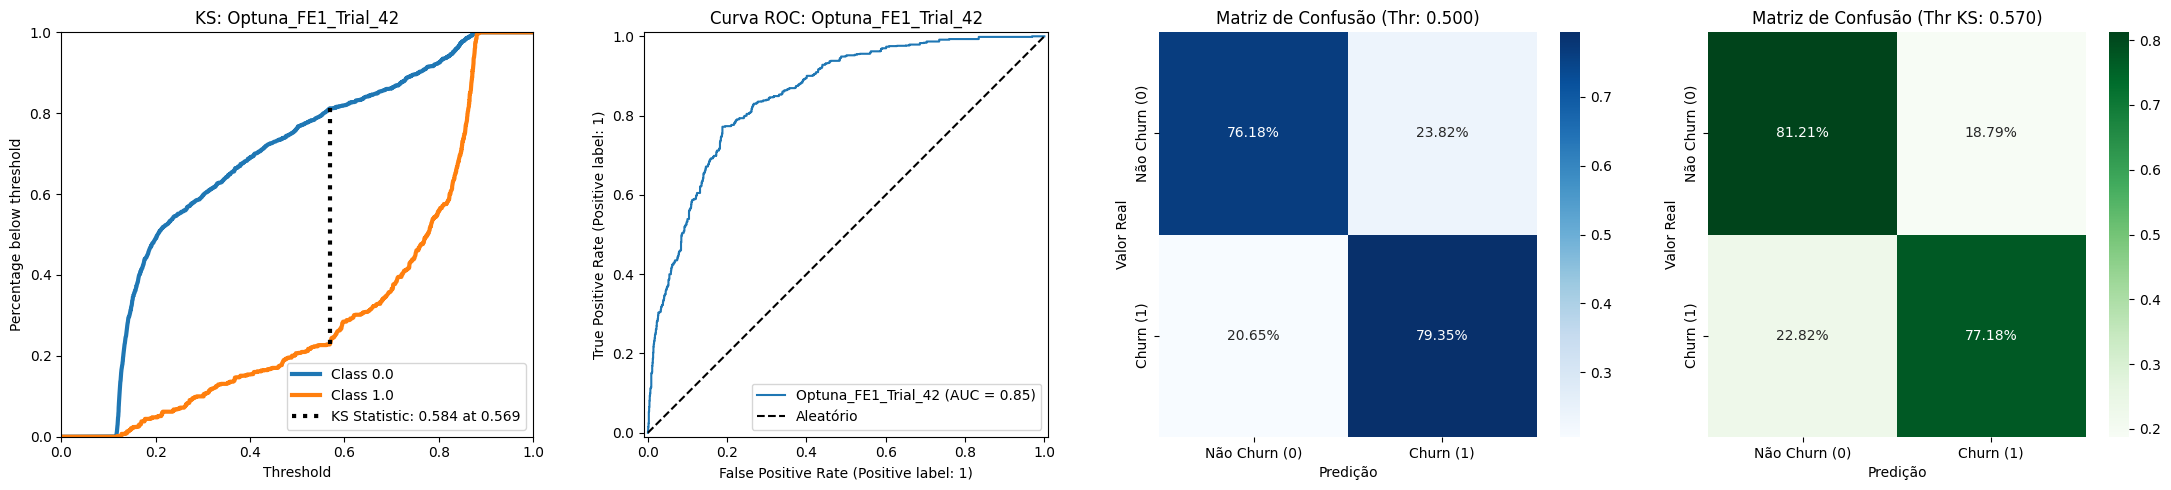

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5839 | AUROC: 0.8534 | Acurácia: 0.7776
Precisão: 0.7691 | Recall: 0.7935 | F1-Score: 0.7811

Relatório de Classificação (Threshold Padrão):
               precision    recall  f1-score   support

Não Churn (0)       0.79      0.76      0.77      1293
    Churn (1)       0.77      0.79      0.78      1293

     accuracy                           0.78      2586
    macro avg       0.78      0.78      0.78      2586
 weighted avg       0.78      0.78      0.78      2586


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.570) ---
KS: 0.5839 | AUROC: 0.8534 | Acurácia: 0.7920
Precisão: 0.8042 | Recall: 0.7718 | F1-Score: 0.7877

Relatório de Classificação (Threshold Otimizado):
               precision    recall  f1-score   support

Não Churn (0)       0.78      0.81      0.80      1293
    Churn (1)       0.80      0.77      0.79      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79

In [ ]:
# Otimização Optuna e Avaliação do Vencedor para FE_1 (Qtde_Servicos)
study_fe1 = rodar_optuna_e_avaliar(
    nome_estudo="Otimizacao_MLP_FE1",
    X_train=X_train_fe1,
    y_train=y_train_fe1,
    X_val=X_val_fe1,
    y_val=y_val_fe1,
    prefixo_trial="Optuna_FE1_Trial"
)

##FE_2: Tenure Binning (6 em 6 meses)

In [ ]:
# 1. Puxa NOVAMENTE a cópia da base virgem (garante que a Qtde_Servicos não exista aqui)
df_fe2 = df_base.copy()
cols_cat_fe2 = colunas_categoricas_base.copy()
cols_num_fe2 = colunas_numericas_base.copy()

# 2. Aplica a transformação (Binning)
bins = [0, 6, 12, 18, 24, 30, 78]
# Atualizamos a label e adicionamos include_lowest=True para o 0 não virar NaN
labels = ['0-6m', '7-12m', '13-18m', '19-24m', '25-30m', '30+m']
df_fe2['Tenure_Group'] = pd.cut(df_fe2['tenure'], bins=bins, labels=labels, right=True, include_lowest=True)

# 3. Adiciona APENAS na lista temporária categórica deste escopo
if 'Tenure_Group' not in cols_cat_fe2:
    cols_cat_fe2.append('Tenure_Group')

print("Feature 'Tenure_Group' criada (clientes com tenure=0 tratados corretamente)!")
display(df_fe2[['tenure', 'Tenure_Group']].head(10))

print("\nVerificando os clientes com tenure = 0 (devem pertencer ao grupo '0-6m'):")
display(df_fe2[df_fe2['tenure'] == 0][['tenure', 'Tenure_Group']].head(3))

Feature 'Tenure_Group' criada com a nova estratégia (30+m) e adicionada às colunas categóricas!


,tenure,Tenure_Group
0,1,1-6m
1,34,30+m
2,2,1-6m
3,45,30+m
4,2,1-6m
5,8,7-12m
6,22,19-24m
7,10,7-12m
8,28,25-30m
9,62,30+m


In [ ]:
# 4. Refaz o Split e o Pipeline
print("Refazendo Split e Pre-processamento para FE2...")
df_train_fe2, df_val_fe2, df_test_fe2 = realizar_split(df_fe2)

X_train_fe2, y_train_fe2, X_val_fe2, y_val_fe2, X_test_fe2, y_test_fe2 = aplicar_pipeline_e_oversampling(
    df_train_fe2, df_val_fe2, df_test_fe2, cols_cat_fe2, cols_num_fe2
)

print(f"Tamanho de features de treino (FE2): {X_train_fe2.shape[1]} colunas.")

Refazendo Split e Pre-processamento para FE2...
Tamanho de features de treino (FE2): 47 colunas.


Treinando modelo de Ablação com os parâmetros do Campeão Manual (Rodada 8)...

----------------------------------------------------------------------
EXPERIMENTO: MLP_FE2_TenureBin_BaseR8 | Camadas: [16] | LR: 0.0001 | Batch: 32


Treinando:   1%|          | 76/10000 [00:10<22:48,  7.25it/s]


 -> Early stopping acionado na época 77
Resultado Final - Val Loss: 0.4621 | Melhor KS: 0.5831 | Tempo: 10.48s

VENCEDOR DA BATERIA: MLP_FE2_TenureBin_BaseR8 (KS Máximo: 0.5831)


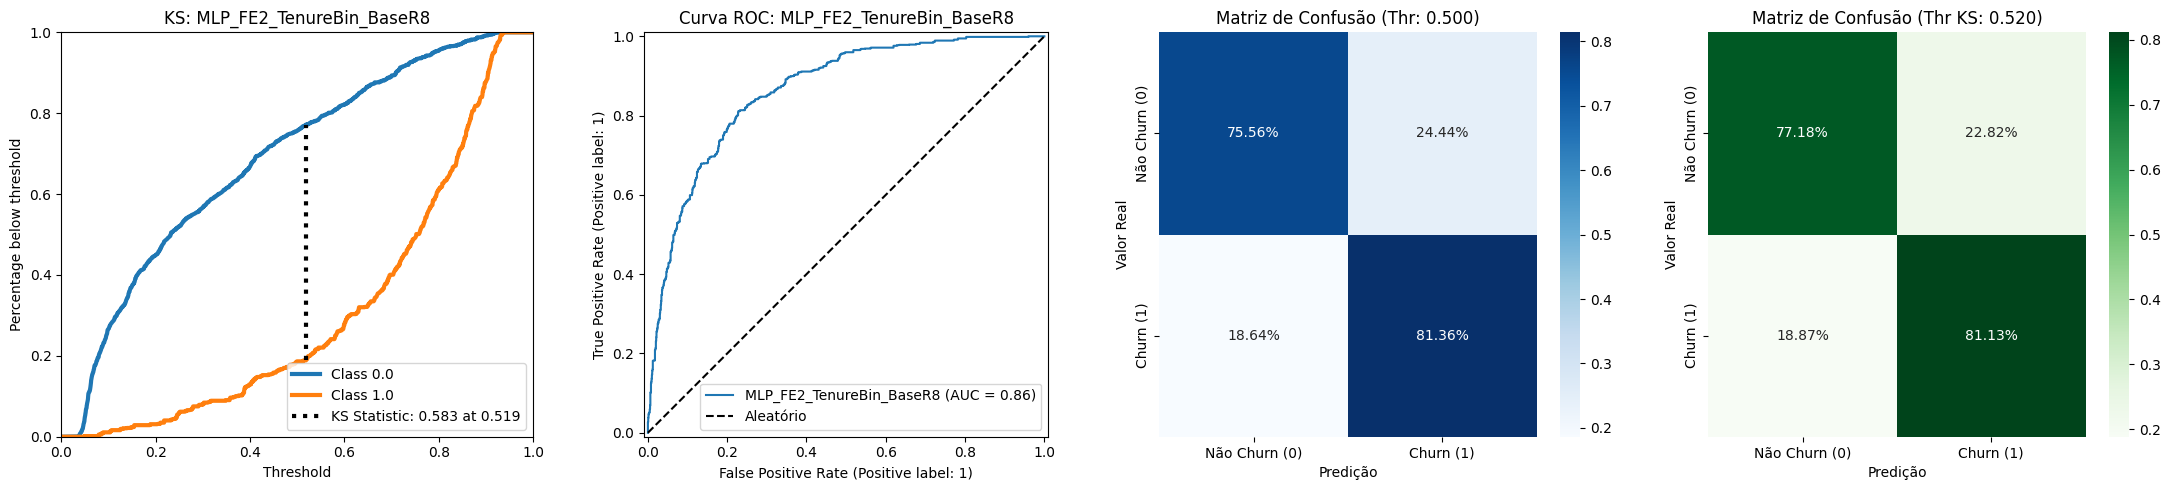

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5831 | AUROC: 0.8633 | Acurácia: 0.7846
Precisão: 0.7690 | Recall: 0.8136 | F1-Score: 0.7907

Relatório de Classificação (Threshold Padrão):
               precision    recall  f1-score   support

Não Churn (0)       0.80      0.76      0.78      1293
    Churn (1)       0.77      0.81      0.79      1293

     accuracy                           0.78      2586
    macro avg       0.79      0.78      0.78      2586
 weighted avg       0.79      0.78      0.78      2586


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.520) ---
KS: 0.5831 | AUROC: 0.8633 | Acurácia: 0.7916
Precisão: 0.7805 | Recall: 0.8113 | F1-Score: 0.7956

Relatório de Classificação (Threshold Otimizado):
               precision    recall  f1-score   support

Não Churn (0)       0.80      0.77      0.79      1293
    Churn (1)       0.78      0.81      0.80      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79

Treinando:   0%|          | 24/10000 [00:02<15:33, 10.69it/s]


 -> Early stopping acionado na época 25
Resultado Final - Val Loss: 0.4651 | Melhor KS: 0.5831 | Tempo: 2.25s

VENCEDOR DA BATERIA: MLP_FE2_TenureBin_BaseOptuna (KS Máximo: 0.5831)


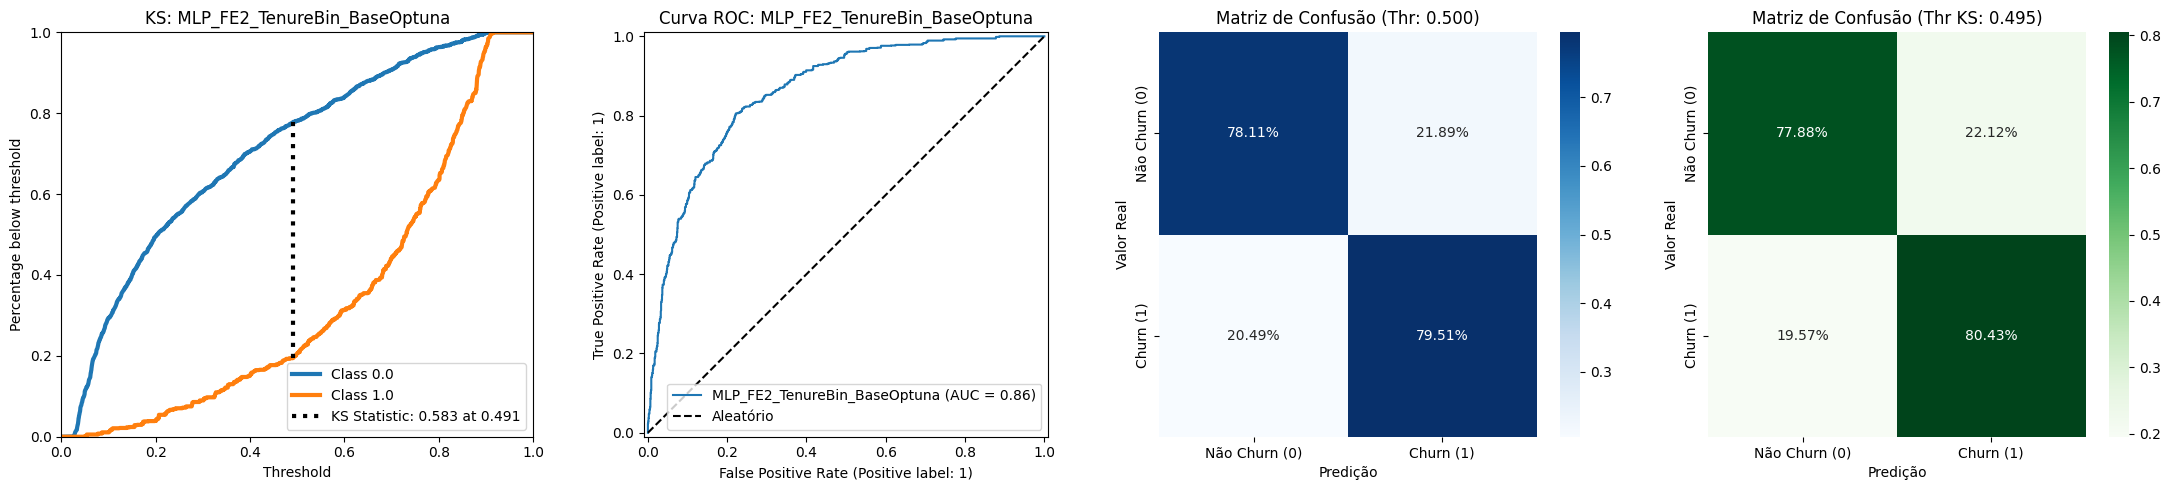

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5831 | AUROC: 0.8614 | Acurácia: 0.7881
Precisão: 0.7841 | Recall: 0.7951 | F1-Score: 0.7896

Relatório de Classificação (Threshold Padrão):
               precision    recall  f1-score   support

Não Churn (0)       0.79      0.78      0.79      1293
    Churn (1)       0.78      0.80      0.79      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79      2586
 weighted avg       0.79      0.79      0.79      2586


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.495) ---
KS: 0.5831 | AUROC: 0.8614 | Acurácia: 0.7916
Precisão: 0.7843 | Recall: 0.8043 | F1-Score: 0.7942

Relatório de Classificação (Threshold Otimizado):
               precision    recall  f1-score   support

Não Churn (0)       0.80      0.78      0.79      1293
    Churn (1)       0.78      0.80      0.79      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79

In [ ]:
# --- Experimentos de Ablação com a nova feature (Tenure_Group) ---

print("Treinando modelo de Ablação com os parâmetros do Campeão Manual (Rodada 8)...")

resultado_fe2_manual = executar_experimento_churn(
    name_experiment="MLP_FE2_TenureBin_BaseR8",
    input_size=X_train_fe2.shape[1],
    hidden_layers=vencedor_r8['hidden_layers'],
    learning_rate=vencedor_r8['learning_rate'],
    batch_size=int(vencedor_r8['batch_size']),
    num_epochs=10000,
    activation_function=ativacao_campeao_r8,
    loss_name=vencedor_r8.get('loss_name', 'CrossEntropy'),
    optimizer_name=vencedor_r8['optimizer_name'],
    weight_decay=vencedor_r8['weight_decay'],
    dropout_rate=vencedor_r8['dropout_rate'],
    X_train=X_train_fe2,
    y_train=y_train_fe2,
    X_val=X_val_fe2,
    y_val=y_val_fe2
)

_ = plotar_vencedor_churn([resultado_fe2_manual], X_train_fe2.shape[1], X_val_fe2, y_val_fe2, activation_function=ativacao_campeao_r8)

print("\n" + "="*50)
print(f"KS Anterior (Campeão R8 sem Tenure_Group): {ks_r8_base:.4f}")
print(f"KS Atual (Campeão R8 com Tenure_Group): {resultado_fe2_manual['val_ks']:.4f}")
print("="*50)

print("\n\nTreinando modelo de Ablação com os parâmetros do Campeão do Optuna...")

resultado_fe2_optuna = executar_experimento_churn(
    name_experiment="MLP_FE2_TenureBin_BaseOptuna",
    input_size=X_train_fe2.shape[1],
    hidden_layers=arq_campeao,
    learning_rate=best_trial.params['learning_rate'],
    batch_size=best_trial.params['batch_size'],
    num_epochs=10000,
    activation_function=ativacao_campeao_optuna,
    loss_name=best_trial.params.get('loss_name', 'CrossEntropy'),
    optimizer_name=best_trial.params['optimizer_name'],
    weight_decay=best_trial.params['weight_decay'],
    dropout_rate=best_trial.params['dropout_rate'],
    X_train=X_train_fe2,
    y_train=y_train_fe2,
    X_val=X_val_fe2,
    y_val=y_val_fe2
)

_ = plotar_vencedor_churn([resultado_fe2_optuna], X_train_fe2.shape[1], X_val_fe2, y_val_fe2, activation_function=ativacao_campeao_optuna)

print("\n" + "="*50)
print(f"KS Anterior (Campeão Optuna sem Tenure_Group): {ks_optuna_base:.4f}")
print(f"KS Atual (Campeão Optuna com Tenure_Group): {resultado_fe2_optuna['val_ks']:.4f}")
print("="*50)


### Comparação Visual: Tenure_Group

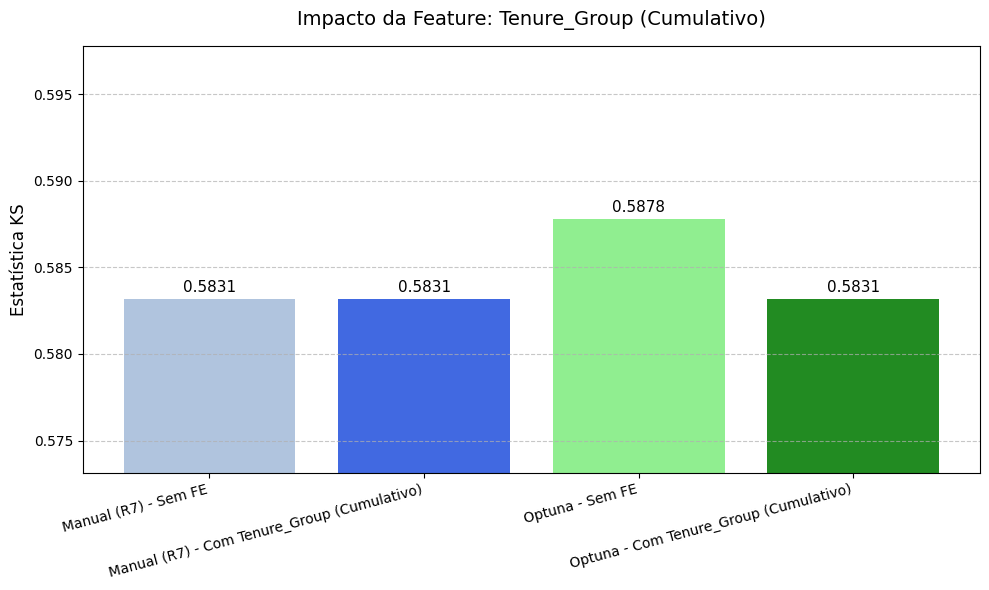

In [ ]:
ks_r8_fe2 = resultado_fe2_manual['val_ks']
ks_optuna_fe2 = resultado_fe2_optuna['val_ks']

plot_feature_engineering_comparison(
    name_fe='Tenure_Group (Cumulativo)',
    ks_r7_base=ks_r8_base, # Usando a base global da rodada 8
    ks_r7_fe=ks_r8_fe2,
    ks_optuna_base=ks_optuna_base,
    ks_optuna_fe=ks_optuna_fe2
)


### Optuna FE_2 (Tenure Binning)

[I 2026-10-19 19:13:03,711] A new study created in RDB with name: Otimizacao_MLP_FE2


Iniciando Optuna para: Otimizacao_MLP_FE2...

----------------------------------------------------------------------
EXPERIMENTO: Optuna_FE2_Trial_0 | Camadas: [16, 8] | LR: 0.0013292918943162175 | Batch: 64


Treinando:   0%|          | 37/10000 [00:03<15:08, 10.97it/s]
[I 2026-10-19 19:13:07,179] Trial 0 finished with value: 0.5754060324825986 and parameters: {'learning_rate': 0.0013292918943162175, 'dropout_rate': 0.4753571532049581, 'weight_decay': 0.000291063591313307, 'optimizer_name': 'Adam', 'batch_size': 64, 'loss_name': 'MSE', 'activation_function': 'ReLU', 'arquitetura_idx': 4}. Best is trial 0 with value: 0.5754060324825986.


 -> Early stopping acionado na época 38
Resultado Final - Val Loss: 0.1519 | Melhor KS: 0.5754 | Tempo: 3.38s

----------------------------------------------------------------------
EXPERIMENTO: Optuna_FE2_Trial_1 | Camadas: [32] | LR: 0.0226739865237804 | Batch: 256


Treinando:   0%|          | 22/10000 [00:01<09:41, 17.17it/s]
[I 2026-10-19 19:13:08,542] Trial 1 finished with value: 0.5777262180974478 and parameters: {'learning_rate': 0.0226739865237804, 'dropout_rate': 0.09983689107917987, 'weight_decay': 0.00010677482709481354, 'optimizer_name': 'RMSprop', 'batch_size': 256, 'loss_name': 'CrossEntropy', 'activation_function': 'Tanh', 'arquitetura_idx': 2}. Best is trial 1 with value: 0.5777262180974478.


 -> Early stopping acionado na época 23
Resultado Final - Val Loss: 0.4711 | Melhor KS: 0.5777 | Tempo: 1.28s

----------------------------------------------------------------------
EXPERIMENTO: Optuna_FE2_Trial_2 | Camadas: [64] | LR: 0.08105016126411585 | Batch: 256


... (192 outputs left out)

Treinando:   0%|          | 50/10000 [00:03<12:45, 12.99it/s]
[I 2026-10-19 19:42:37,770] Trial 98 finished with value: 0.5823665893271461 and parameters: {'learning_rate': 0.0011738004008100464, 'dropout_rate': 0.38136212541441816, 'weight_decay': 0.00024290862251389678, 'optimizer_name': 'Adam', 'batch_size': 64, 'loss_name': 'MSE', 'activation_function': 'LeakyReLU', 'arquitetura_idx': 1}. Best is trial 58 with value: 0.5924207269914926.


 -> Early stopping acionado na época 51
Resultado Final - Val Loss: 0.1504 | Melhor KS: 0.5824 | Tempo: 3.85s

----------------------------------------------------------------------
EXPERIMENTO: Optuna_FE2_Trial_99 | Camadas: [16] | LR: 0.0006260821631965246 | Batch: 64


Treinando:   1%|          | 55/10000 [00:04<12:39, 13.10it/s]
[I 2026-10-19 19:42:42,069] Trial 99 finished with value: 0.5870069605568445 and parameters: {'learning_rate': 0.0006260821631965246, 'dropout_rate': 0.39123214789565003, 'weight_decay': 8.295309673019467e-05, 'optimizer_name': 'Adam', 'batch_size': 64, 'loss_name': 'MSE', 'activation_function': 'LeakyReLU', 'arquitetura_idx': 1}. Best is trial 58 with value: 0.5924207269914926.


 -> Early stopping acionado na época 56
Resultado Final - Val Loss: 0.1507 | Melhor KS: 0.5870 | Tempo: 4.20s

=== MELHOR MODELO ENCONTRADO (Otimizacao_MLP_FE2) ===
Melhor KS: 0.5924
Melhores Parâmetros:
    learning_rate: 0.002859436587808807
    dropout_rate: 0.4078362707426737
    weight_decay: 0.00015588077289967005
    optimizer_name: Adam
    batch_size: 64
    loss_name: MSE
    activation_function: ReLU
    arquitetura: [16]

Calculando e plotando métricas para o Grande Campeão (Otimizacao_MLP_FE2)...

VENCEDOR DA BATERIA: Optuna_FE2_Trial_58 (KS Máximo: 0.5924)


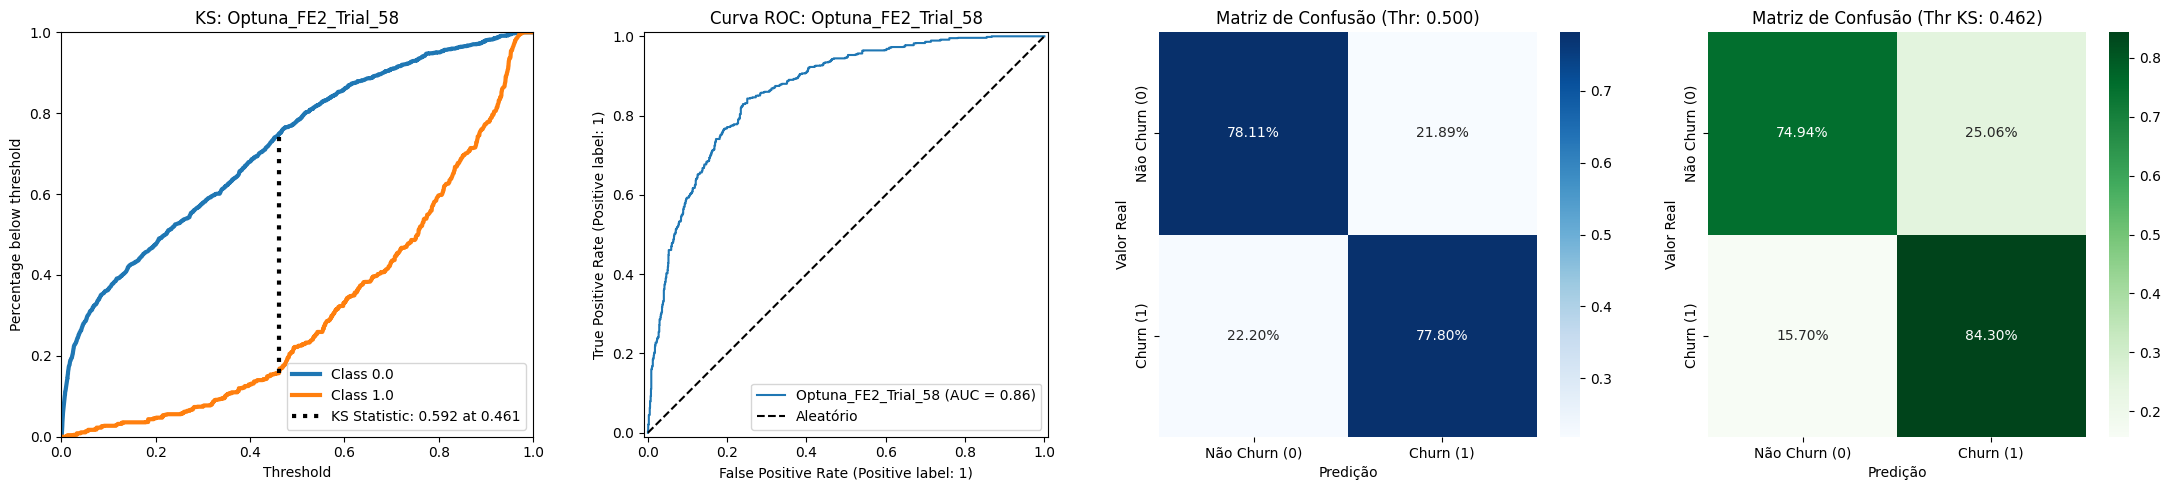

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5924 | AUROC: 0.8632 | Acurácia: 0.7796
Precisão: 0.7804 | Recall: 0.7780 | F1-Score: 0.7792

Relatório de Classificação (Threshold Padrão):
               precision    recall  f1-score   support

Não Churn (0)       0.78      0.78      0.78      1293
    Churn (1)       0.78      0.78      0.78      1293

     accuracy                           0.78      2586
    macro avg       0.78      0.78      0.78      2586
 weighted avg       0.78      0.78      0.78      2586


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.462) ---
KS: 0.5924 | AUROC: 0.8632 | Acurácia: 0.7962
Precisão: 0.7709 | Recall: 0.8430 | F1-Score: 0.8053

Relatório de Classificação (Threshold Otimizado):
               precision    recall  f1-score   support

Não Churn (0)       0.83      0.75      0.79      1293
    Churn (1)       0.77      0.84      0.81      1293

     accuracy                           0.80      2586
    macro avg       0.80      0.80      0.80

In [ ]:
# Otimização Optuna e Avaliação do Vencedor para FE_2 (Tenure Binning)
study_fe2 = rodar_optuna_e_avaliar(
    nome_estudo="Otimizacao_MLP_FE2",
    X_train=X_train_fe2,
    y_train=y_train_fe2,
    X_val=X_val_fe2,
    y_val=y_val_fe2,
    prefixo_trial="Optuna_FE2_Trial"
)

## FE_3: Proporção de Gasto (Gasto_Medio_Real)

In [ ]:
# 1. Puxa a cópia da base virgem e das listas
df_fe3 = df_base.copy()
cols_cat_fe3 = colunas_categoricas_base.copy()
cols_num_fe3 = colunas_numericas_base.copy()

# 2. Aplica a transformação
# Evitando divisão por zero: onde tenure for 0, o Gasto_Medio_Real será 0
df_fe3['Gasto_Medio_Real'] = np.where(df_fe3['tenure'] == 0, 0, df_fe3['TotalCharges'] / df_fe3['tenure'])

# 3. Adiciona APENAS na lista temporária deste escopo
if 'Gasto_Medio_Real' not in cols_num_fe3:
    cols_num_fe3.append('Gasto_Medio_Real')

print("Feature 'Gasto_Medio_Real' criada e adicionada às colunas numéricas!")
display(df_fe3[['TotalCharges', 'tenure', 'Gasto_Medio_Real', 'MonthlyCharges']].head(5))

Feature 'Gasto_Medio_Real' criada e adicionada às colunas numéricas!


,TotalCharges,tenure,Gasto_Medio_Real,MonthlyCharges
0,29.85,1,29.850000,29.85
1,1889.50,34,55.573529,56.95
2,108.15,2,54.075000,53.85
3,1840.75,45,40.905556,42.30
4,151.65,2,75.825000,70.70


In [ ]:
# 4. Refaz o Split e o Pipeline usando os dados e colunas isolados
print("Refazendo Split e Pre-processamento para FE3...")
df_train_fe3, df_val_fe3, df_test_fe3 = realizar_split(df_fe3)

X_train_fe3, y_train_fe3, X_val_fe3, y_val_fe3, X_test_fe3, y_test_fe3 = aplicar_pipeline_e_oversampling(
    df_train_fe3, df_val_fe3, df_test_fe3, cols_cat_fe3, cols_num_fe3
)

print(f"Tamanho de features de treino (FE3): {X_train_fe3.shape[1]} colunas.")

Refazendo Split e Pre-processamento para FE3...
Tamanho de features de treino (FE3): 41 colunas.


Treinando modelo de Ablação com os parâmetros do Campeão Manual (Rodada 8)...

----------------------------------------------------------------------
EXPERIMENTO: MLP_FE3_GastoMedio_BaseR8 | Camadas: [16] | LR: 0.0001 | Batch: 32


Treinando:   1%|          | 121/10000 [00:13<17:44,  9.28it/s]


 -> Early stopping acionado na época 122
Resultado Final - Val Loss: 0.4698 | Melhor KS: 0.5785 | Tempo: 13.04s

VENCEDOR DA BATERIA: MLP_FE3_GastoMedio_BaseR8 (KS Máximo: 0.5785)


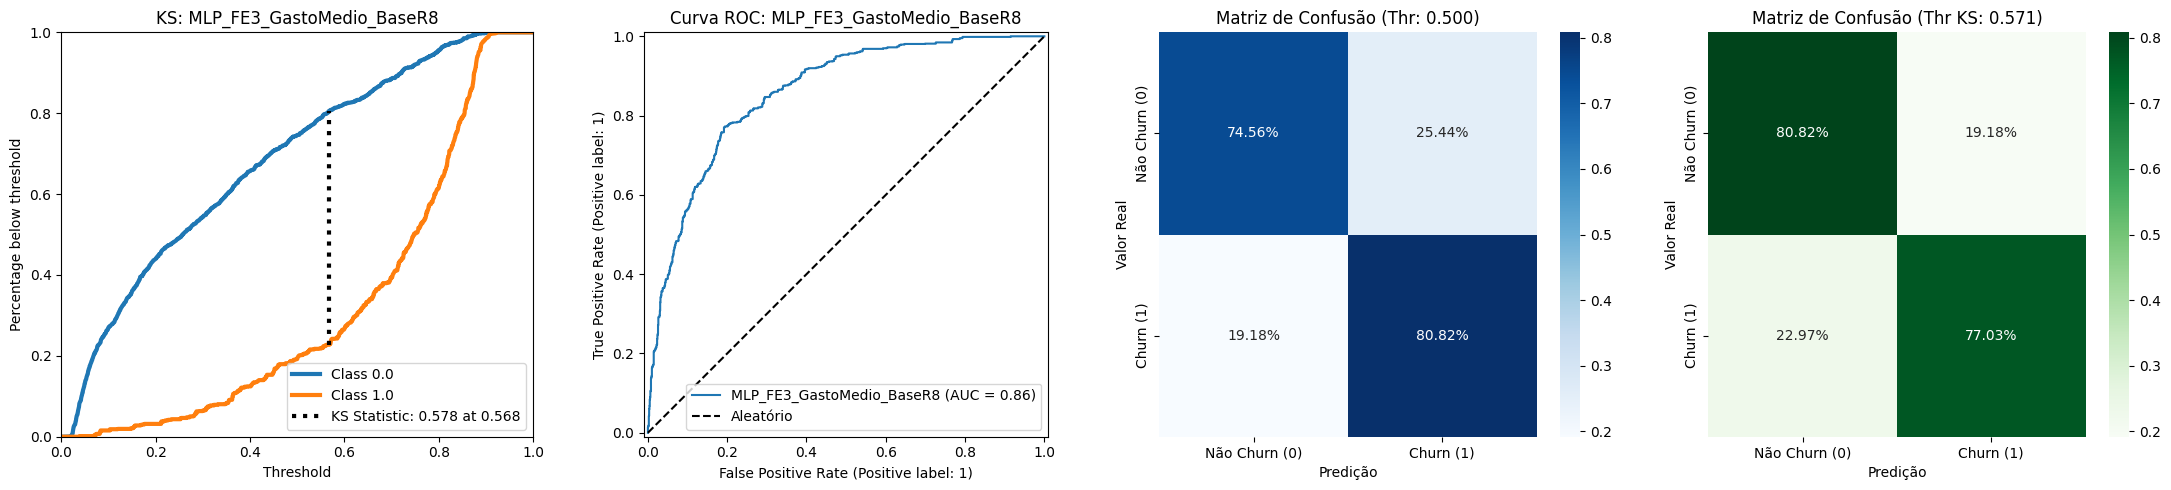

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5785 | AUROC: 0.8577 | Acurácia: 0.7769
Precisão: 0.7606 | Recall: 0.8082 | F1-Score: 0.7837

Relatório de Classificação (Threshold Padrão):
               precision    recall  f1-score   support

Não Churn (0)       0.80      0.75      0.77      1293
    Churn (1)       0.76      0.81      0.78      1293

     accuracy                           0.78      2586
    macro avg       0.78      0.78      0.78      2586
 weighted avg       0.78      0.78      0.78      2586


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.571) ---
KS: 0.5785 | AUROC: 0.8577 | Acurácia: 0.7892
Precisão: 0.8006 | Recall: 0.7703 | F1-Score: 0.7852

Relatório de Classificação (Threshold Otimizado):
               precision    recall  f1-score   support

Não Churn (0)       0.78      0.81      0.79      1293
    Churn (1)       0.80      0.77      0.79      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79

Treinando:   0%|          | 39/10000 [00:03<13:45, 12.06it/s]


 -> Early stopping acionado na época 40
Resultado Final - Val Loss: 0.4715 | Melhor KS: 0.5762 | Tempo: 3.24s

VENCEDOR DA BATERIA: MLP_FE3_GastoMedio_BaseOptuna (KS Máximo: 0.5762)


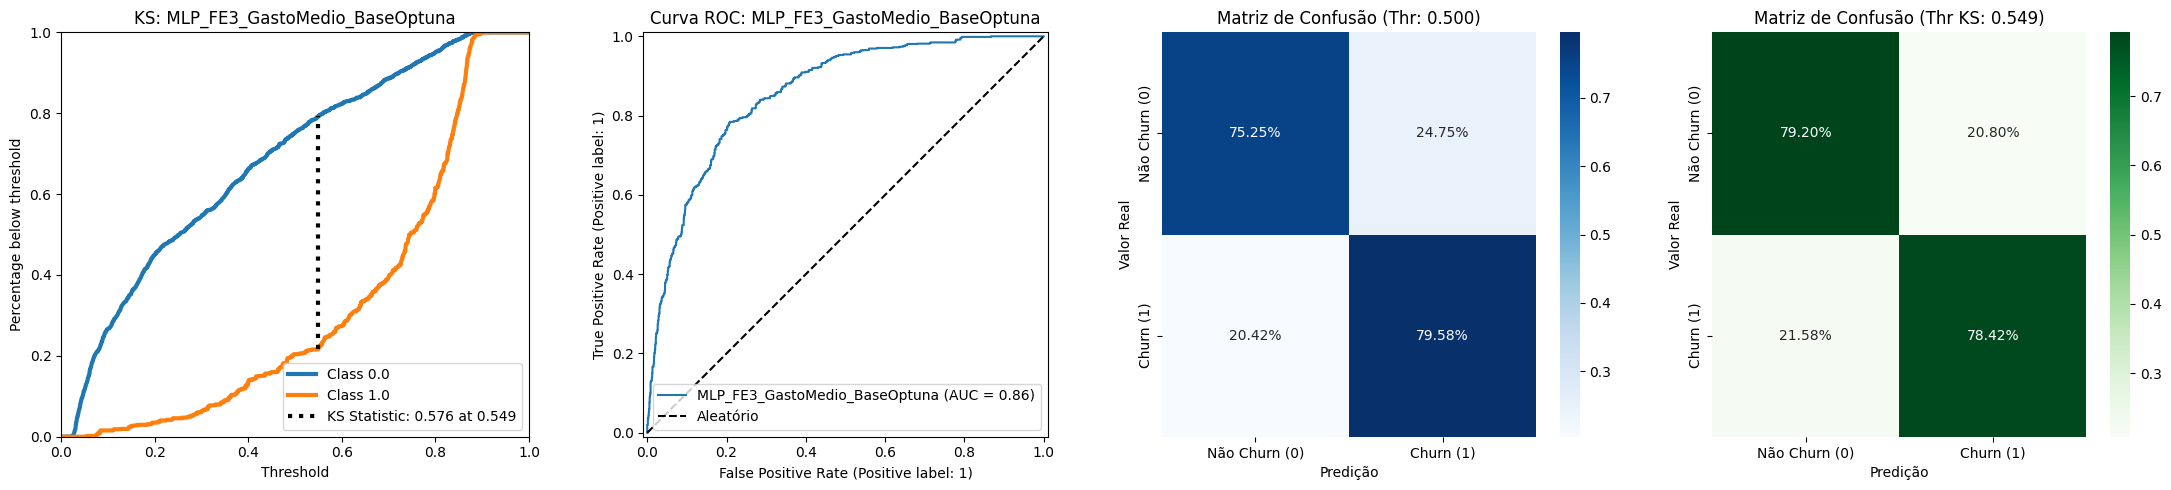

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5762 | AUROC: 0.8570 | Acurácia: 0.7742
Precisão: 0.7628 | Recall: 0.7958 | F1-Score: 0.7790

Relatório de Classificação (Threshold Padrão):
               precision    recall  f1-score   support

Não Churn (0)       0.79      0.75      0.77      1293
    Churn (1)       0.76      0.80      0.78      1293

     accuracy                           0.77      2586
    macro avg       0.77      0.77      0.77      2586
 weighted avg       0.77      0.77      0.77      2586


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.549) ---
KS: 0.5762 | AUROC: 0.8570 | Acurácia: 0.7881
Precisão: 0.7903 | Recall: 0.7842 | F1-Score: 0.7873

Relatório de Classificação (Threshold Otimizado):
               precision    recall  f1-score   support

Não Churn (0)       0.79      0.79      0.79      1293
    Churn (1)       0.79      0.78      0.79      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79

In [ ]:
print("Treinando modelo de Ablação com os parâmetros do Campeão Manual (Rodada 8)...")

resultado_fe3_manual = executar_experimento_churn(
    name_experiment="MLP_FE3_GastoMedio_BaseR8",
    input_size=X_train_fe3.shape[1],
    hidden_layers=vencedor_r8['hidden_layers'],
    learning_rate=vencedor_r8['learning_rate'],
    batch_size=int(vencedor_r8['batch_size']),
    num_epochs=10000,
    activation_function=ativacao_campeao_r8,
    loss_name=vencedor_r8.get('loss_name', 'CrossEntropy'),
    optimizer_name=vencedor_r8['optimizer_name'],
    weight_decay=vencedor_r8['weight_decay'],
    dropout_rate=vencedor_r8['dropout_rate'],
    X_train=X_train_fe3,
    y_train=y_train_fe3,
    X_val=X_val_fe3,
    y_val=y_val_fe3
)

_ = plotar_vencedor_churn([resultado_fe3_manual], X_train_fe3.shape[1], X_val_fe3, y_val_fe3, activation_function=ativacao_campeao_r8)

print("\n" + "="*50)
print(f"KS Anterior (Campeão R8 sem Gasto_Medio): {ks_r8_base:.4f}")
print(f"KS Atual (Campeão R8 com Gasto_Medio): {resultado_fe3_manual['val_ks']:.4f}")
print("="*50)


print("\n\nTreinando modelo de Ablação com os parâmetros do Campeão do Optuna (FE3)...")

resultado_fe3_optuna = executar_experimento_churn(
    name_experiment="MLP_FE3_GastoMedio_BaseOptuna",
    input_size=X_train_fe3.shape[1],
    hidden_layers=arq_campeao,
    learning_rate=best_trial.params['learning_rate'],
    batch_size=best_trial.params['batch_size'],
    num_epochs=10000,
    activation_function=ativacao_campeao_optuna,
    loss_name=best_trial.params.get('loss_name', 'CrossEntropy'),
    optimizer_name=best_trial.params['optimizer_name'],
    weight_decay=best_trial.params['weight_decay'],
    dropout_rate=best_trial.params['dropout_rate'],
    X_train=X_train_fe3,
    y_train=y_train_fe3,
    X_val=X_val_fe3,
    y_val=y_val_fe3
)

_ = plotar_vencedor_churn([resultado_fe3_optuna], X_train_fe3.shape[1], X_val_fe3, y_val_fe3, activation_function=ativacao_campeao_optuna)

print("\n" + "="*50)
print(f"KS Anterior (Campeão Optuna sem Gasto_Medio): {ks_optuna_base:.4f}")
print(f"KS Atual (Campeão Optuna com Gasto_Medio): {resultado_fe3_optuna['val_ks']:.4f}")
print("="*50)


### Comparação Visual: Proporção de Gasto

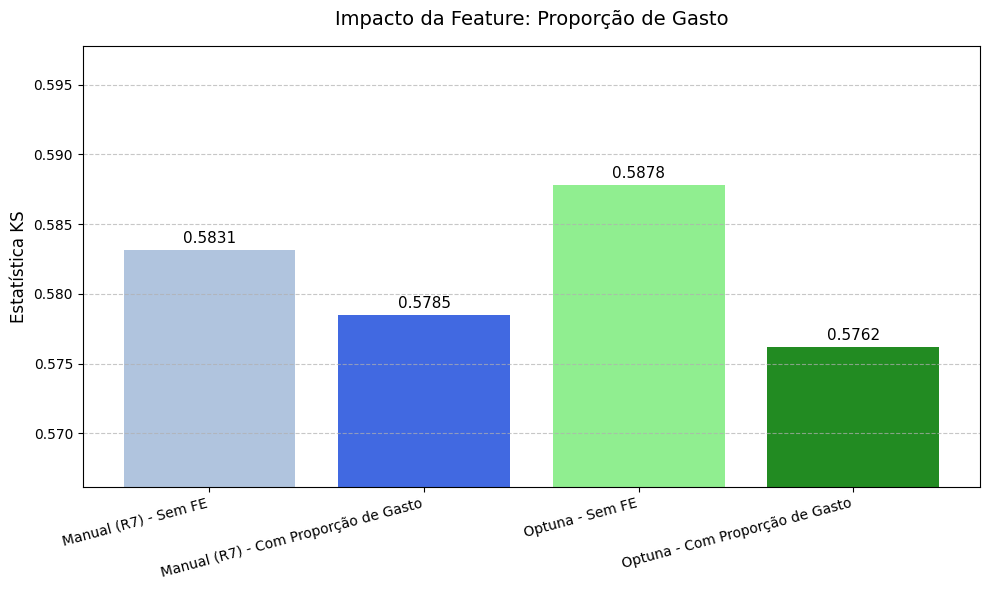

In [ ]:
ks_r8_fe3 = resultado_fe3_manual['val_ks']
ks_optuna_fe3 = resultado_fe3_optuna['val_ks']

plot_feature_engineering_comparison(
    name_fe='Proporção de Gasto',
    ks_r7_base=ks_r8_base, # Usando a base global da rodada 8
    ks_r7_fe=ks_r8_fe3,
    ks_optuna_base=ks_optuna_base,
    ks_optuna_fe=ks_optuna_fe3
)


### Optuna FE_3 (Proporção de Gasto)

[I 2026-10-19 21:32:09,715] A new study created in RDB with name: Otimizacao_MLP_FE3


Iniciando Optuna para: Otimizacao_MLP_FE3...

----------------------------------------------------------------------
EXPERIMENTO: Optuna_FE3_Trial_0 | Camadas: [16, 8] | LR: 0.0013292918943162175 | Batch: 64


Treinando:   1%|          | 53/10000 [00:04<13:47, 12.02it/s]
[I 2026-10-19 21:32:14,230] Trial 0 finished with value: 0.57153905645785 and parameters: {'learning_rate': 0.0013292918943162175, 'dropout_rate': 0.4753571532049581, 'weight_decay': 0.000291063591313307, 'optimizer_name': 'Adam', 'batch_size': 64, 'loss_name': 'MSE', 'activation_function': 'ReLU', 'arquitetura_idx': 4}. Best is trial 0 with value: 0.57153905645785.


 -> Early stopping acionado na época 54
Resultado Final - Val Loss: 0.1555 | Melhor KS: 0.5715 | Tempo: 4.41s

----------------------------------------------------------------------
EXPERIMENTO: Optuna_FE3_Trial_1 | Camadas: [32] | LR: 0.0226739865237804 | Batch: 256


Treinando:   0%|          | 46/10000 [00:02<07:42, 21.51it/s]
[I 2026-10-19 21:32:16,452] Trial 1 finished with value: 0.5645784996133024 and parameters: {'learning_rate': 0.0226739865237804, 'dropout_rate': 0.09983689107917987, 'weight_decay': 0.00010677482709481354, 'optimizer_name': 'RMSprop', 'batch_size': 256, 'loss_name': 'CrossEntropy', 'activation_function': 'Tanh', 'arquitetura_idx': 2}. Best is trial 0 with value: 0.57153905645785.


 -> Early stopping acionado na época 47
Resultado Final - Val Loss: 0.4799 | Melhor KS: 0.5646 | Tempo: 2.14s

----------------------------------------------------------------------
EXPERIMENTO: Optuna_FE3_Trial_2 | Camadas: [64] | LR: 0.08105016126411585 | Batch: 256


... (192 outputs left out)

Treinando:   0%|          | 39/10000 [00:02<08:35, 19.33it/s]
[I 2026-10-19 21:44:26,846] Trial 98 finished with value: 0.5707656612529002 and parameters: {'learning_rate': 0.09990540558371735, 'dropout_rate': 0.22782773388020477, 'weight_decay': 2.6269858892641683e-05, 'optimizer_name': 'Adadelta', 'batch_size': 128, 'loss_name': 'MSE', 'activation_function': 'ReLU', 'arquitetura_idx': 3}. Best is trial 3 with value: 0.5846867749419954.


 -> Early stopping acionado na época 40
Resultado Final - Val Loss: 0.1545 | Melhor KS: 0.5708 | Tempo: 2.02s

----------------------------------------------------------------------
EXPERIMENTO: Optuna_FE3_Trial_99 | Camadas: [64] | LR: 0.004525595822832112 | Batch: 128


Treinando:   1%|          | 82/10000 [00:04<08:11, 20.16it/s]
[I 2026-10-19 21:44:31,027] Trial 99 finished with value: 0.5792730085073473 and parameters: {'learning_rate': 0.004525595822832112, 'dropout_rate': 0.18662769265486517, 'weight_decay': 1.1438995454897838e-05, 'optimizer_name': 'Adadelta', 'batch_size': 128, 'loss_name': 'MSE', 'activation_function': 'Tanh', 'arquitetura_idx': 3}. Best is trial 3 with value: 0.5846867749419954.


 -> Early stopping acionado na época 83
Resultado Final - Val Loss: 0.1531 | Melhor KS: 0.5793 | Tempo: 4.07s

=== MELHOR MODELO ENCONTRADO (Otimizacao_MLP_FE3) ===
Melhor KS: 0.5847
Melhores Parâmetros:
    learning_rate: 0.015382308040279003
    dropout_rate: 0.38563517334297287
    weight_decay: 1.4063366777718176e-05
    optimizer_name: RMSprop
    batch_size: 64
    loss_name: MSE
    activation_function: Tanh
    arquitetura: [64]

Calculando e plotando métricas para o Grande Campeão (Otimizacao_MLP_FE3)...

VENCEDOR DA BATERIA: Optuna_FE3_Trial_3 (KS Máximo: 0.5847)


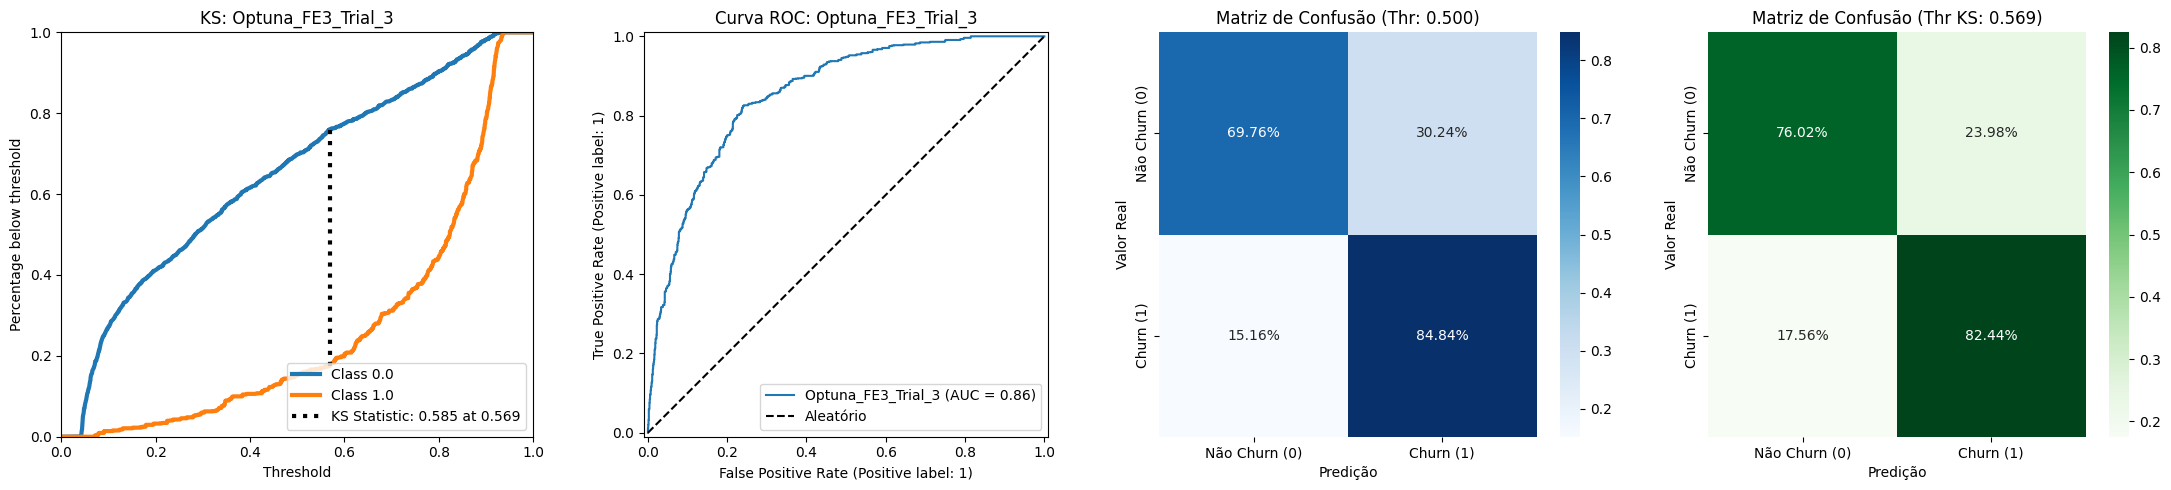

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5847 | AUROC: 0.8555 | Acurácia: 0.7730
Precisão: 0.7372 | Recall: 0.8484 | F1-Score: 0.7889

Relatório de Classificação (Threshold Padrão):
               precision    recall  f1-score   support

Não Churn (0)       0.82      0.70      0.75      1293
    Churn (1)       0.74      0.85      0.79      1293

     accuracy                           0.77      2586
    macro avg       0.78      0.77      0.77      2586
 weighted avg       0.78      0.77      0.77      2586


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.569) ---
KS: 0.5847 | AUROC: 0.8555 | Acurácia: 0.7923
Precisão: 0.7747 | Recall: 0.8244 | F1-Score: 0.7988

Relatório de Classificação (Threshold Otimizado):
               precision    recall  f1-score   support

Não Churn (0)       0.81      0.76      0.79      1293
    Churn (1)       0.77      0.82      0.80      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79

In [ ]:
# Otimização Optuna e Avaliação do Vencedor para FE_3 (Proporção de Gasto)
study_fe3 = rodar_optuna_e_avaliar(
    nome_estudo="Otimizacao_MLP_FE3",
    X_train=X_train_fe3,
    y_train=y_train_fe3,
    X_val=X_val_fe3,
    y_val=y_val_fe3,
    prefixo_trial="Optuna_FE3_Trial"
)

## FE_4: Família (Partner + Dependents)

In [ ]:
# 1. Puxa a cópia da base virgem e das listas
df_fe4 = df_base.copy()
cols_cat_fe4 = colunas_categoricas_base.copy()
cols_num_fe4 = colunas_numericas_base.copy()

# 2. Aplica a transformação
# Criamos a coluna com 'Yes' ou 'No' para ser tratada como categórica pelo Pipeline
df_fe4['Tem_Familia'] = ((df_fe4['Partner'] == 'Yes') | (df_fe4['Dependents'] == 'Yes')).map({True: 'Yes', False: 'No'})

# 3. Adiciona APENAS na lista temporária deste escopo
if 'Tem_Familia' not in cols_cat_fe4:
    cols_cat_fe4.append('Tem_Familia')

print("Feature 'Tem_Familia' criada e adicionada às colunas categóricas!")
display(df_fe4[['Partner', 'Dependents', 'Tem_Familia']].head(5))

Feature 'Tem_Familia' criada e adicionada às colunas categóricas!


,Partner,Dependents,Tem_Familia
0,Yes,No,Yes
1,No,No,No
2,No,No,No
3,No,No,No
4,No,No,No


In [ ]:
# 4. Refaz o Split e o Pipeline usando os dados e colunas isolados
print("Refazendo Split e Pre-processamento para FE4...")
df_train_fe4, df_val_fe4, df_test_fe4 = realizar_split(df_fe4)

X_train_fe4, y_train_fe4, X_val_fe4, y_val_fe4, X_test_fe4, y_test_fe4 = aplicar_pipeline_e_oversampling(
    df_train_fe4, df_val_fe4, df_test_fe4, cols_cat_fe4, cols_num_fe4
)

print(f"Tamanho de features de treino (FE4): {X_train_fe4.shape[1]} colunas.")

Refazendo Split e Pre-processamento para FE4...
Tamanho de features de treino (FE4): 41 colunas.


Treinando modelo de Ablação com os parâmetros do Campeão Manual (Rodada 8)...

----------------------------------------------------------------------
EXPERIMENTO: MLP_FE4_Familia_BaseR8 | Camadas: [16] | LR: 0.0001 | Batch: 32


Treinando:   1%|▏         | 149/10000 [00:15<17:03,  9.62it/s]


 -> Early stopping acionado na época 150
Resultado Final - Val Loss: 0.4682 | Melhor KS: 0.5785 | Tempo: 15.48s

VENCEDOR DA BATERIA: MLP_FE4_Familia_BaseR8 (KS Máximo: 0.5785)


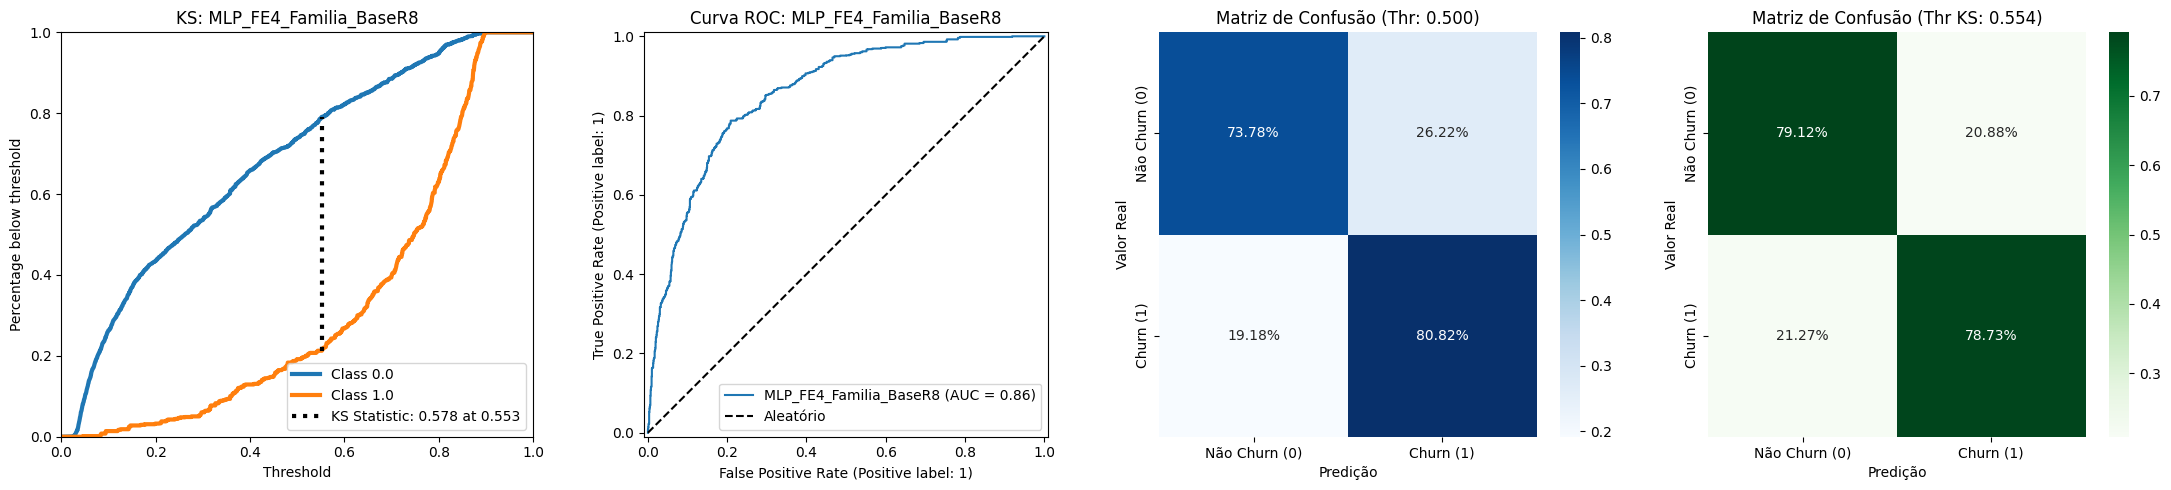

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5785 | AUROC: 0.8571 | Acurácia: 0.7730
Precisão: 0.7551 | Recall: 0.8082 | F1-Score: 0.7807

Relatório de Classificação (Threshold Padrão):
               precision    recall  f1-score   support

Não Churn (0)       0.79      0.74      0.76      1293
    Churn (1)       0.76      0.81      0.78      1293

     accuracy                           0.77      2586
    macro avg       0.77      0.77      0.77      2586
 weighted avg       0.77      0.77      0.77      2586


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.554) ---
KS: 0.5785 | AUROC: 0.8571 | Acurácia: 0.7892
Precisão: 0.7904 | Recall: 0.7873 | F1-Score: 0.7888

Relatório de Classificação (Threshold Otimizado):
               precision    recall  f1-score   support

Não Churn (0)       0.79      0.79      0.79      1293
    Churn (1)       0.79      0.79      0.79      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79

Treinando:   0%|          | 28/10000 [00:01<11:23, 14.60it/s]


 -> Early stopping acionado na época 29
Resultado Final - Val Loss: 0.4710 | Melhor KS: 0.5777 | Tempo: 1.92s

VENCEDOR DA BATERIA: MLP_FE4_Familia_BaseOptuna (KS Máximo: 0.5777)


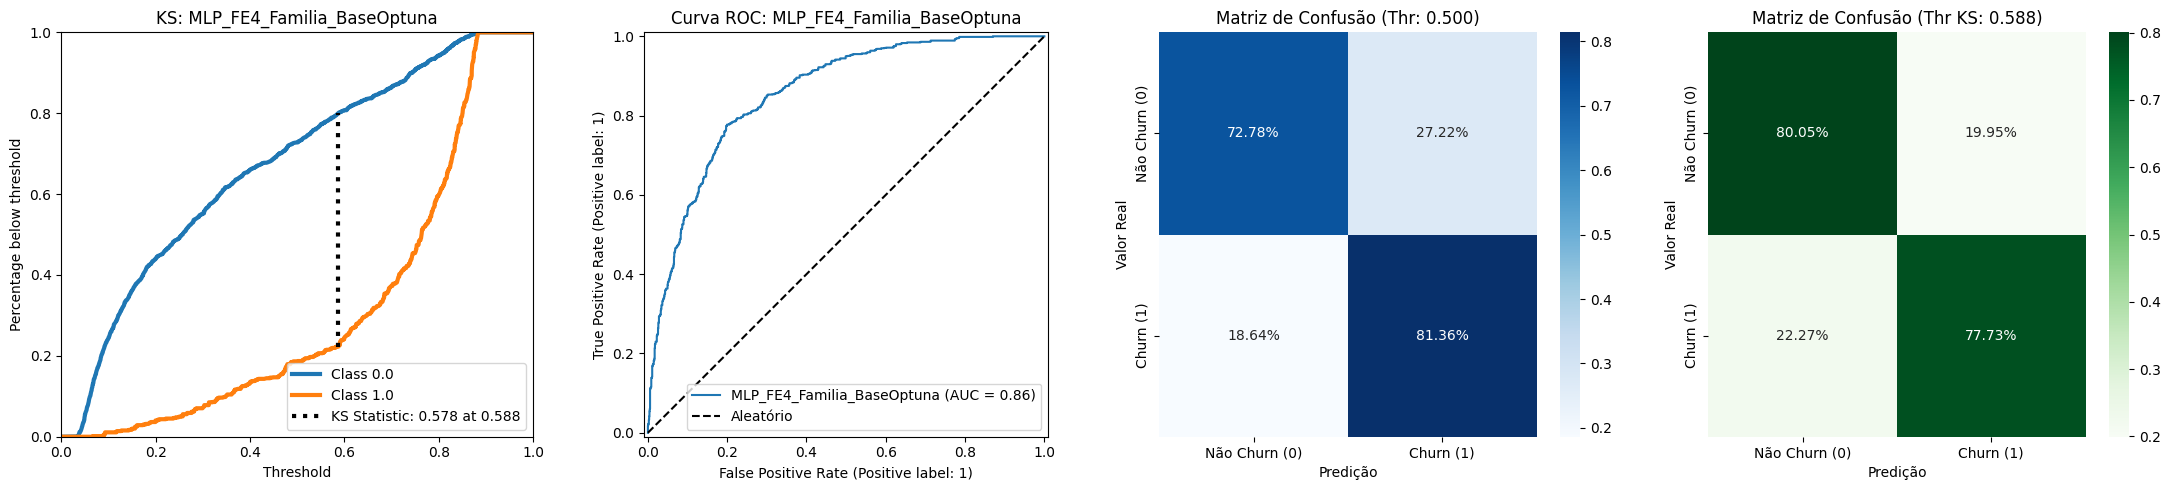

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5777 | AUROC: 0.8556 | Acurácia: 0.7707
Precisão: 0.7493 | Recall: 0.8136 | F1-Score: 0.7801

Relatório de Classificação (Threshold Padrão):
               precision    recall  f1-score   support

Não Churn (0)       0.80      0.73      0.76      1293
    Churn (1)       0.75      0.81      0.78      1293

     accuracy                           0.77      2586
    macro avg       0.77      0.77      0.77      2586
 weighted avg       0.77      0.77      0.77      2586


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.588) ---
KS: 0.5777 | AUROC: 0.8556 | Acurácia: 0.7889
Precisão: 0.7957 | Recall: 0.7773 | F1-Score: 0.7864

Relatório de Classificação (Threshold Otimizado):
               precision    recall  f1-score   support

Não Churn (0)       0.78      0.80      0.79      1293
    Churn (1)       0.80      0.78      0.79      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79

In [ ]:
print("Treinando modelo de Ablação com os parâmetros do Campeão Manual (Rodada 8)...")

resultado_fe4_manual = executar_experimento_churn(
    name_experiment="MLP_FE4_Familia_BaseR8",
    input_size=X_train_fe4.shape[1],
    hidden_layers=vencedor_r8['hidden_layers'],
    learning_rate=vencedor_r8['learning_rate'],
    batch_size=int(vencedor_r8['batch_size']),
    num_epochs=10000,
    activation_function=ativacao_campeao_r8,
    loss_name=vencedor_r8.get('loss_name', 'CrossEntropy'),
    optimizer_name=vencedor_r8['optimizer_name'],
    weight_decay=vencedor_r8['weight_decay'],
    dropout_rate=vencedor_r8['dropout_rate'],
    X_train=X_train_fe4,
    y_train=y_train_fe4,
    X_val=X_val_fe4,
    y_val=y_val_fe4
)

_ = plotar_vencedor_churn([resultado_fe4_manual], X_train_fe4.shape[1], X_val_fe4, y_val_fe4, activation_function=ativacao_campeao_r8)

print("\n" + "="*50)
print(f"KS Anterior (Campeão R8 sem Familia): {ks_r8_base:.4f}")
print(f"KS Atual (Campeão R8 com Familia): {resultado_fe4_manual['val_ks']:.4f}")
print("="*50)


print("\n\nTreinando modelo de Ablação com os parâmetros do Campeão do Optuna (FE4)...")

resultado_fe4_optuna = executar_experimento_churn(
    name_experiment="MLP_FE4_Familia_BaseOptuna",
    input_size=X_train_fe4.shape[1],
    hidden_layers=arq_campeao,
    learning_rate=best_trial.params['learning_rate'],
    batch_size=best_trial.params['batch_size'],
    num_epochs=10000,
    activation_function=ativacao_campeao_optuna,
    loss_name=best_trial.params.get('loss_name', 'CrossEntropy'),
    optimizer_name=best_trial.params['optimizer_name'],
    weight_decay=best_trial.params['weight_decay'],
    dropout_rate=best_trial.params['dropout_rate'],
    X_train=X_train_fe4,
    y_train=y_train_fe4,
    X_val=X_val_fe4,
    y_val=y_val_fe4
)

_ = plotar_vencedor_churn([resultado_fe4_optuna], X_train_fe4.shape[1], X_val_fe4, y_val_fe4, activation_function=ativacao_campeao_optuna)

print("\n" + "="*50)
print(f"KS Anterior (Campeão Optuna sem Familia): {ks_optuna_base:.4f}")
print(f"KS Atual (Campeão Optuna com Familia): {resultado_fe4_optuna['val_ks']:.4f}")
print("="*50)


### Comparação Visual: Família

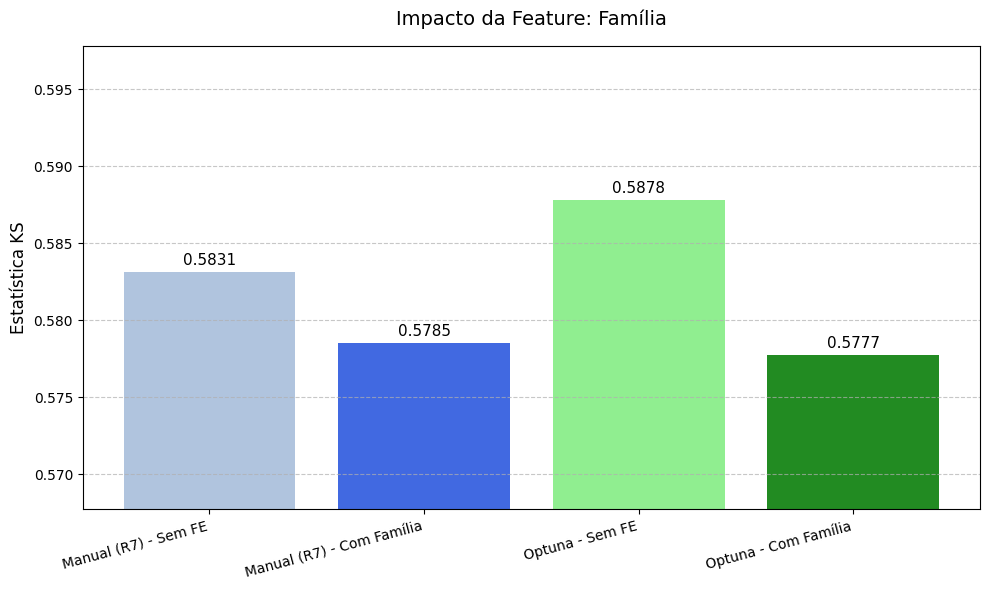

In [ ]:
ks_r8_fe4 = resultado_fe4_manual['val_ks']
ks_optuna_fe4 = resultado_fe4_optuna['val_ks']

plot_feature_engineering_comparison(
    name_fe='Família',
    ks_r7_base=ks_r8_base, # Usando a base global da rodada 8
    ks_r7_fe=ks_r8_fe4,
    ks_optuna_base=ks_optuna_base,
    ks_optuna_fe=ks_optuna_fe4
)


### Optuna FE_4 (Família)

[I 2026-10-19 22:19:14,075] A new study created in RDB with name: Otimizacao_MLP_FE4


Iniciando Optuna para: Otimizacao_MLP_FE4...

----------------------------------------------------------------------
EXPERIMENTO: Optuna_FE4_Trial_0 | Camadas: [16, 8] | LR: 0.0013292918943162175 | Batch: 64


Treinando:   0%|          | 39/10000 [00:02<12:11, 13.62it/s]
[I 2026-10-19 22:19:17,030] Trial 0 finished with value: 0.5738592420726991 and parameters: {'learning_rate': 0.0013292918943162175, 'dropout_rate': 0.4753571532049581, 'weight_decay': 0.000291063591313307, 'optimizer_name': 'Adam', 'batch_size': 64, 'loss_name': 'MSE', 'activation_function': 'ReLU', 'arquitetura_idx': 4}. Best is trial 0 with value: 0.5738592420726991.


 -> Early stopping acionado na época 40
Resultado Final - Val Loss: 0.1554 | Melhor KS: 0.5739 | Tempo: 2.86s

----------------------------------------------------------------------
EXPERIMENTO: Optuna_FE4_Trial_1 | Camadas: [32] | LR: 0.0226739865237804 | Batch: 256


Treinando:   0%|          | 46/10000 [00:01<05:36, 29.54it/s]
[I 2026-10-19 22:19:18,678] Trial 1 finished with value: 0.5754060324825986 and parameters: {'learning_rate': 0.0226739865237804, 'dropout_rate': 0.09983689107917987, 'weight_decay': 0.00010677482709481354, 'optimizer_name': 'RMSprop', 'batch_size': 256, 'loss_name': 'CrossEntropy', 'activation_function': 'Tanh', 'arquitetura_idx': 2}. Best is trial 1 with value: 0.5754060324825986.


 -> Early stopping acionado na época 47
Resultado Final - Val Loss: 0.4748 | Melhor KS: 0.5754 | Tempo: 1.57s

----------------------------------------------------------------------
EXPERIMENTO: Optuna_FE4_Trial_2 | Camadas: [64] | LR: 0.08105016126411585 | Batch: 256


... (192 outputs left out)

Treinando:   1%|▏         | 141/10000 [00:05<05:53, 27.90it/s]
[I 2026-10-19 22:38:41,761] Trial 98 finished with value: 0.580046403712297 and parameters: {'learning_rate': 0.00031749408840079486, 'dropout_rate': 0.17411702628382275, 'weight_decay': 1.3112728611827433e-05, 'optimizer_name': 'RMSprop', 'batch_size': 256, 'loss_name': 'MSE', 'activation_function': 'Tanh', 'arquitetura_idx': 5}. Best is trial 69 with value: 0.5831399845320959.


 -> Early stopping acionado na época 142
Resultado Final - Val Loss: 0.1537 | Melhor KS: 0.5800 | Tempo: 5.06s

----------------------------------------------------------------------
EXPERIMENTO: Optuna_FE4_Trial_99 | Camadas: [32, 16] | LR: 0.00016207811111880154 | Batch: 256


Treinando: 100%|██████████| 10000/10000 [05:27<00:00, 30.57it/s]
[I 2026-10-19 22:44:08,950] Trial 99 finished with value: 0.5614849187935035 and parameters: {'learning_rate': 0.00016207811111880154, 'dropout_rate': 0.27143261408534186, 'weight_decay': 1.1481232248918853e-05, 'optimizer_name': 'SGD', 'batch_size': 256, 'loss_name': 'MSE', 'activation_function': 'Tanh', 'arquitetura_idx': 5}. Best is trial 69 with value: 0.5831399845320959.


Resultado Final - Val Loss: 0.1604 | Melhor KS: 0.5615 | Tempo: 327.08s

=== MELHOR MODELO ENCONTRADO (Otimizacao_MLP_FE4) ===
Melhor KS: 0.5831
Melhores Parâmetros:
    learning_rate: 0.00037740947487280773
    dropout_rate: 0.2099302216391718
    weight_decay: 1.2590877350934778e-05
    optimizer_name: RMSprop
    batch_size: 256
    loss_name: MSE
    activation_function: Tanh
    arquitetura: [32, 16]

Calculando e plotando métricas para o Grande Campeão (Otimizacao_MLP_FE4)...

VENCEDOR DA BATERIA: Optuna_FE4_Trial_69 (KS Máximo: 0.5831)


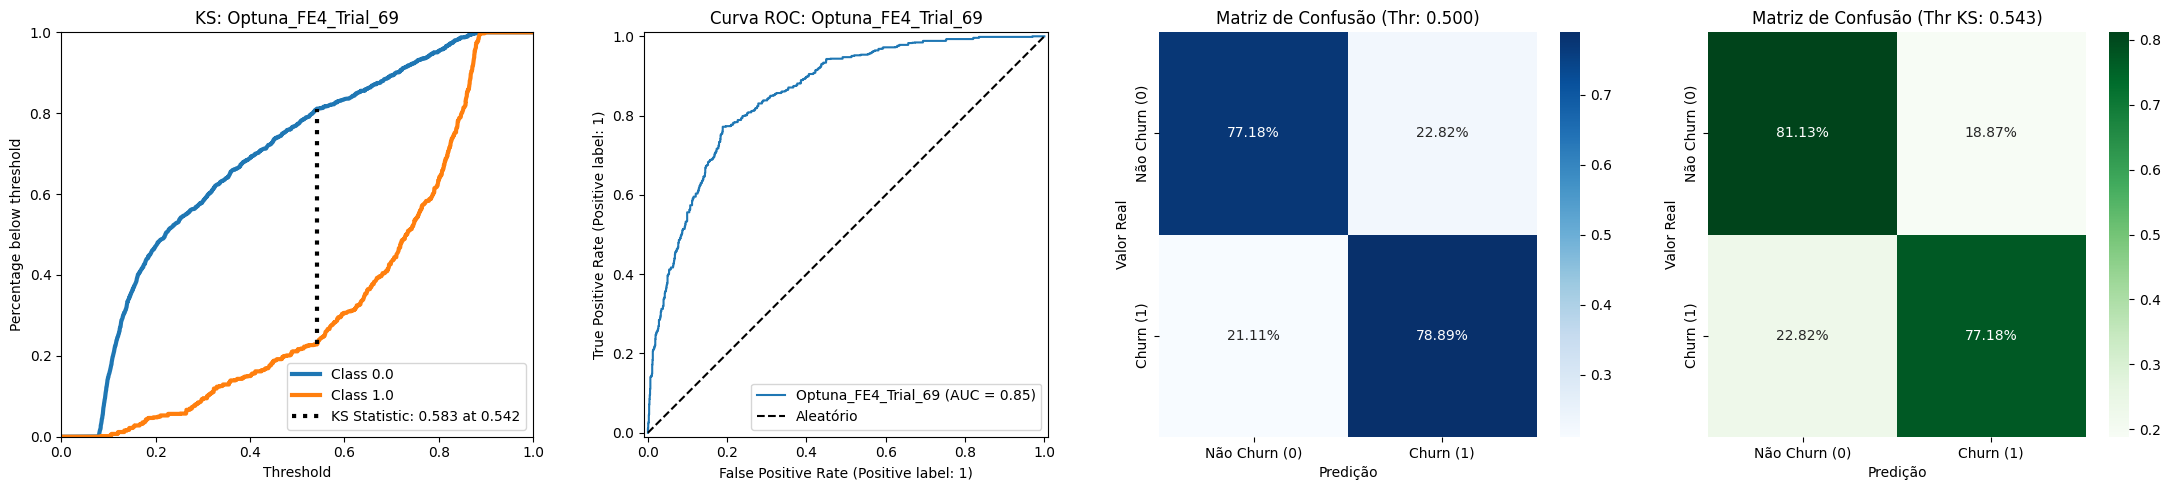

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5831 | AUROC: 0.8547 | Acurácia: 0.7804
Precisão: 0.7757 | Recall: 0.7889 | F1-Score: 0.7822

Relatório de Classificação (Threshold Padrão):
               precision    recall  f1-score   support

Não Churn (0)       0.79      0.77      0.78      1293
    Churn (1)       0.78      0.79      0.78      1293

     accuracy                           0.78      2586
    macro avg       0.78      0.78      0.78      2586
 weighted avg       0.78      0.78      0.78      2586


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.543) ---
KS: 0.5831 | AUROC: 0.8547 | Acurácia: 0.7916
Precisão: 0.8035 | Recall: 0.7718 | F1-Score: 0.7874

Relatório de Classificação (Threshold Otimizado):
               precision    recall  f1-score   support

Não Churn (0)       0.78      0.81      0.80      1293
    Churn (1)       0.80      0.77      0.79      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79

In [ ]:
# Otimização Optuna e Avaliação do Vencedor para FE_4 (Família)
study_fe4 = rodar_optuna_e_avaliar(
    nome_estudo="Otimizacao_MLP_FE4",
    X_train=X_train_fe4,
    y_train=y_train_fe4,
    X_val=X_val_fe4,
    y_val=y_val_fe4,
    prefixo_trial="Optuna_FE4_Trial"
)

## FE_ALL: Todas as Features Combinadas + Optuna

In [ ]:
# 1. Base virgem
df_fe_all = df_base.copy()
cols_cat_all = colunas_categoricas_base.copy()
cols_num_all = colunas_numericas_base.copy()

# --- APLICANDO TODAS AS FEATURES ---

# FE_1: Qtde_Servicos
colunas_servicos = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
df_fe_all['Qtde_Servicos'] = df_fe_all[colunas_servicos].apply(lambda linha: (linha == 'Yes').sum(), axis=1)
cols_num_all.append('Qtde_Servicos')

# FE_2: Tenure Binning (Corrigido para tenure = 0)
bins = [0, 6, 12, 18, 24, 30, 78]
labels = ['0-6m', '7-12m', '13-18m', '19-24m', '25-30m', '30+m']
df_fe_all['Tenure_Group'] = pd.cut(df_fe_all['tenure'], bins=bins, labels=labels, right=True, include_lowest=True)
cols_cat_all.append('Tenure_Group')

# FE_3: Proporção de Gasto (Com tratamento para divisão por zero)
df_fe_all['Gasto_Medio_Real'] = np.where(df_fe_all['tenure'] == 0, 0, df_fe_all['TotalCharges'] / df_fe_all['tenure'])
cols_num_all.append('Gasto_Medio_Real')

# FE_4: Família
df_fe_all['Tem_Familia'] = ((df_fe_all['Partner'] == 'Yes') | (df_fe_all['Dependents'] == 'Yes')).map({True: 'Yes', False: 'No'})
cols_cat_all.append('Tem_Familia')

# --- SPLIT E PRE-PROCESSAMENTO ---
print("Refazendo Split e Pre-processamento para FE_ALL...")
df_train_all, df_val_all, df_test_all = realizar_split(df_fe_all)

X_train_all, y_train_all, X_val_all, y_val_all, X_test_all, y_test_all = aplicar_pipeline_e_oversampling(
    df_train_all, df_val_all, df_test_all, cols_cat_all, cols_num_all
)

print(f"Tamanho de features de treino (Todas as FEs): {X_train_all.shape[1]} colunas.")
display(X_train_all.head(3))

Refazendo Split e Pre-processamento para FE_ALL...
Tamanho de features de treino (Todas as FEs): 50 colunas.


,tenure,MonthlyCharges,TotalCharges,Qtde_Servicos,Gasto_Medio_Real,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No,...,PaymentMethod_Mailed check,SeniorCitizen_1,Tenure_Group_1-6m,Tenure_Group_13-18m,Tenure_Group_19-24m,Tenure_Group_25-30m,Tenure_Group_30+m,Tenure_Group_7-12m,Tenure_Group_nan,Tem_Familia_Yes
5051,0.777778,0.878024,0.679342,0.666667,0.852326,1.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4377,0.305556,0.622480,0.200064,0.166667,0.638928,0.0,1.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
3089,0.944444,0.647177,0.662008,1.000000,0.684005,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


Treinando modelo de Ablação com os parâmetros do Campeão Manual (Rodada 8)...

----------------------------------------------------------------------
EXPERIMENTO: MLP_FE_ALL_BaseR8 | Camadas: [16] | LR: 0.0001 | Batch: 32


Treinando:   1%|          | 68/10000 [00:07<17:08,  9.66it/s]


 -> Early stopping acionado na época 69
Resultado Final - Val Loss: 0.4630 | Melhor KS: 0.5808 | Tempo: 7.04s

VENCEDOR DA BATERIA: MLP_FE_ALL_BaseR8 (KS Máximo: 0.5808)


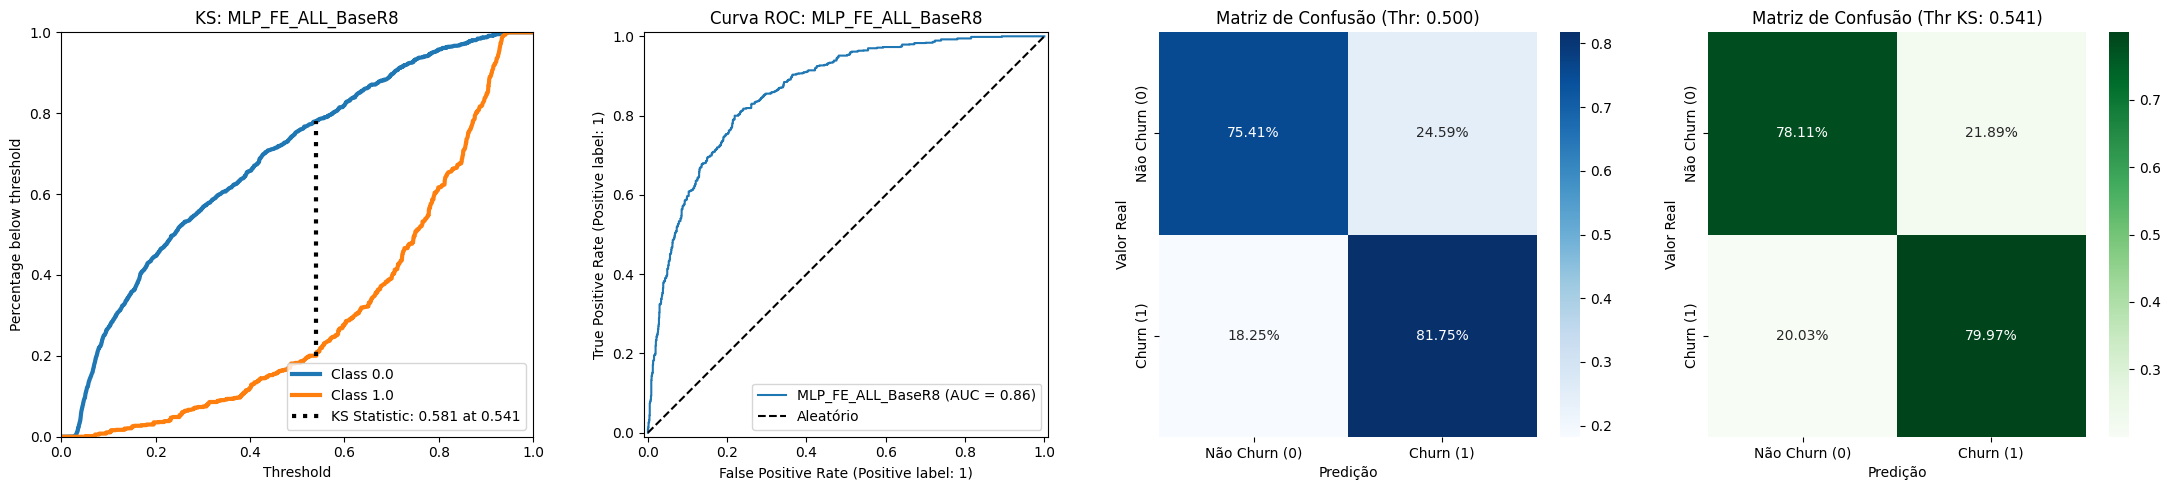

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5808 | AUROC: 0.8627 | Acurácia: 0.7858
Precisão: 0.7687 | Recall: 0.8175 | F1-Score: 0.7924

Relatório de Classificação (Threshold Padrão):
               precision    recall  f1-score   support

Não Churn (0)       0.81      0.75      0.78      1293
    Churn (1)       0.77      0.82      0.79      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79      2586
 weighted avg       0.79      0.79      0.79      2586


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.541) ---
KS: 0.5808 | AUROC: 0.8627 | Acurácia: 0.7904
Precisão: 0.7851 | Recall: 0.7997 | F1-Score: 0.7923

Relatório de Classificação (Threshold Otimizado):
               precision    recall  f1-score   support

Não Churn (0)       0.80      0.78      0.79      1293
    Churn (1)       0.79      0.80      0.79      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79

Treinando:   0%|          | 36/10000 [00:02<11:13, 14.80it/s]


 -> Early stopping acionado na época 37
Resultado Final - Val Loss: 0.1510 | Melhor KS: 0.5878 | Tempo: 2.43s

VENCEDOR DA BATERIA: MLP_FE_ALL_BaseOptuna (KS Máximo: 0.5878)


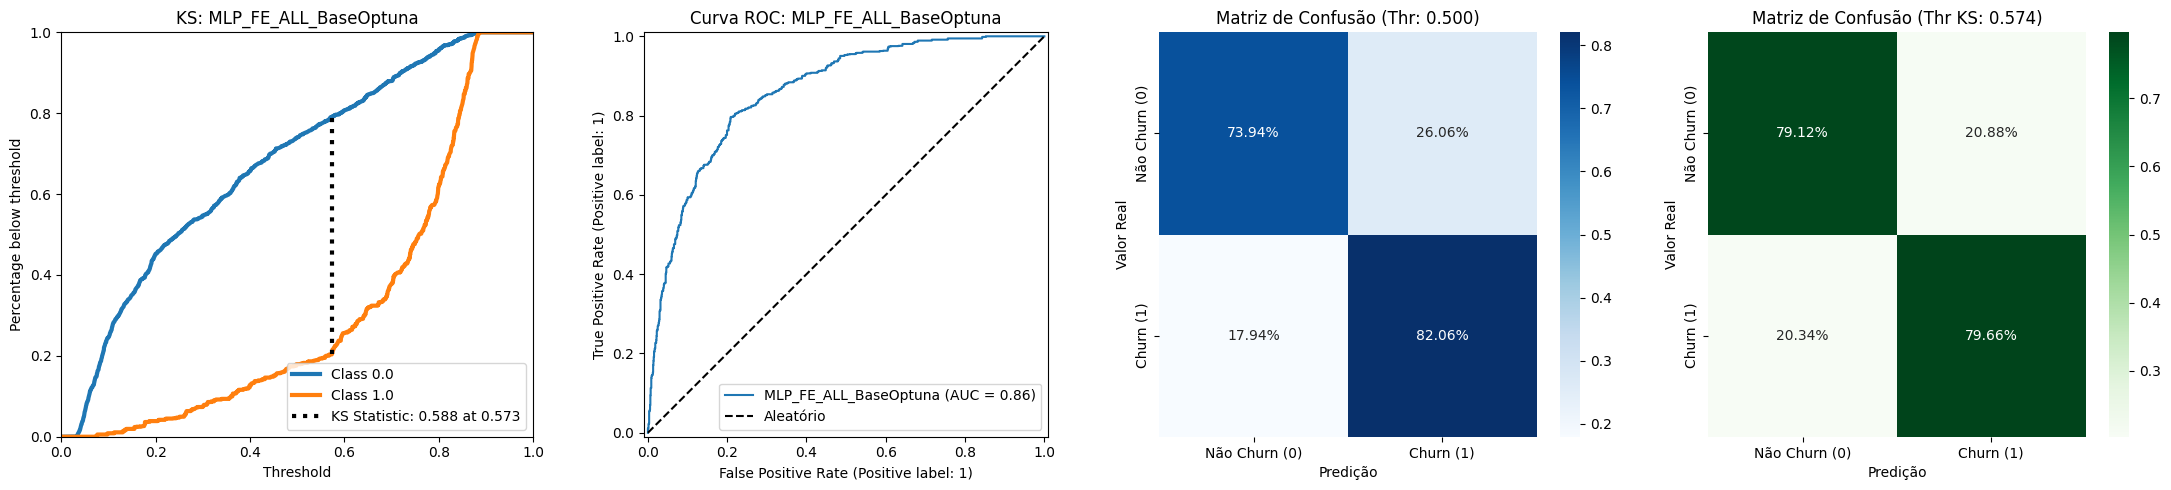

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5878 | AUROC: 0.8605 | Acurácia: 0.7800
Precisão: 0.7589 | Recall: 0.8206 | F1-Score: 0.7886

Relatório de Classificação (Threshold Padrão):
               precision    recall  f1-score   support

Não Churn (0)       0.80      0.74      0.77      1293
    Churn (1)       0.76      0.82      0.79      1293

     accuracy                           0.78      2586
    macro avg       0.78      0.78      0.78      2586
 weighted avg       0.78      0.78      0.78      2586


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.574) ---
KS: 0.5878 | AUROC: 0.8605 | Acurácia: 0.7939
Precisão: 0.7923 | Recall: 0.7966 | F1-Score: 0.7944

Relatório de Classificação (Threshold Otimizado):
               precision    recall  f1-score   support

Não Churn (0)       0.80      0.79      0.79      1293
    Churn (1)       0.79      0.80      0.79      1293

     accuracy                           0.79      2586
    macro avg       0.79      0.79      0.79

In [ ]:
print("Treinando modelo de Ablação com os parâmetros do Campeão Manual (Rodada 8)...")

resultado_fe_all_manual = executar_experimento_churn(
    name_experiment="MLP_FE_ALL_BaseR8",
    input_size=X_train_all.shape[1],
    hidden_layers=vencedor_r8['hidden_layers'],
    learning_rate=vencedor_r8['learning_rate'],
    batch_size=int(vencedor_r8['batch_size']),
    num_epochs=10000,
    activation_function=ativacao_campeao_r8,
    loss_name=vencedor_r8.get('loss_name', 'CrossEntropy'),
    optimizer_name=vencedor_r8['optimizer_name'],
    weight_decay=vencedor_r8['weight_decay'],
    dropout_rate=vencedor_r8['dropout_rate'],
    X_train=X_train_all,
    y_train=y_train_all,
    X_val=X_val_all,
    y_val=y_val_all
)

_ = plotar_vencedor_churn([resultado_fe_all_manual], X_train_all.shape[1], X_val_all, y_val_all, activation_function=ativacao_campeao_r8)

print("\n" + "="*50)
print(f"KS Anterior (Campeão R8 sem FE): {ks_r8_base:.4f}")
print(f"KS Atual (Campeão R8 com FE_ALL): {resultado_fe_all_manual['val_ks']:.4f}")
print("="*50)


print("\n\nTreinando modelo de Ablação com os parâmetros do Campeão do Optuna Base...")

resultado_fe_all_optuna = executar_experimento_churn(
    name_experiment="MLP_FE_ALL_BaseOptuna",
    input_size=X_train_all.shape[1],
    hidden_layers=arq_campeao,
    learning_rate=best_trial.params['learning_rate'],
    batch_size=best_trial.params['batch_size'],
    num_epochs=10000,
    activation_function=ativacao_campeao_optuna,
    loss_name=best_trial.params.get('loss_name', 'CrossEntropy'),
    optimizer_name=best_trial.params['optimizer_name'],
    weight_decay=best_trial.params['weight_decay'],
    dropout_rate=best_trial.params['dropout_rate'],
    X_train=X_train_all,
    y_train=y_train_all,
    X_val=X_val_all,
    y_val=y_val_all
)

_ = plotar_vencedor_churn([resultado_fe_all_optuna], X_train_all.shape[1], X_val_all, y_val_all, activation_function=ativacao_campeao_optuna)

print("\n" + "="*50)
print(f"KS Anterior (Campeão Optuna sem FE): {ks_optuna_base:.4f}")
print(f"KS Atual (Campeão Optuna com FE_ALL): {resultado_fe_all_optuna['val_ks']:.4f}")
print("="*50)


### Comparação Visual: Todas as Features (FE_ALL)

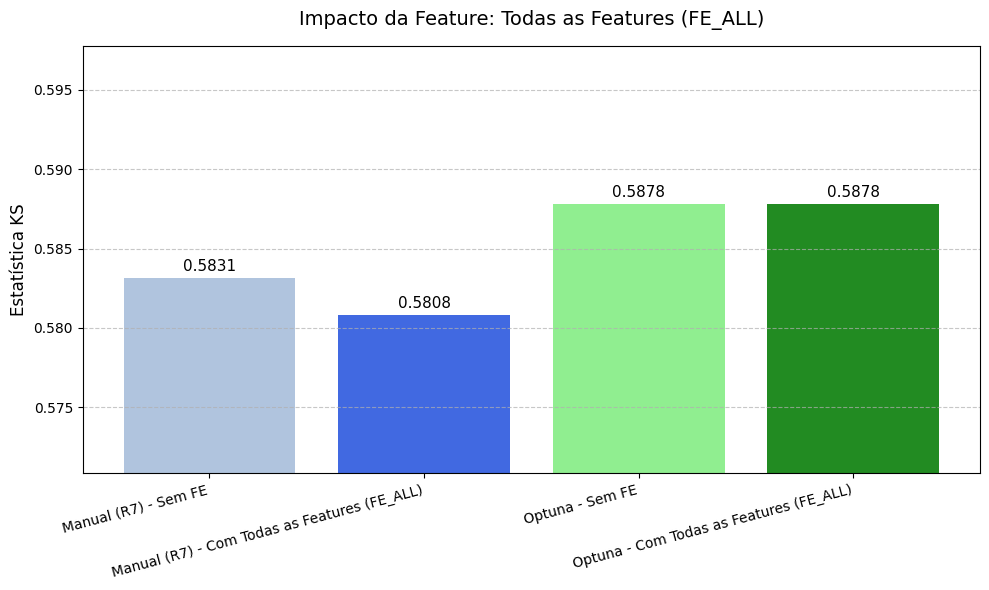

In [ ]:
ks_fe_all_manual = resultado_fe_all_manual['val_ks']
ks_fe_all_optuna = resultado_fe_all_optuna['val_ks']

plot_feature_engineering_comparison(
    name_fe='Todas as Features (FE_ALL)',
    ks_r7_base=ks_r8_base, # Usando a base global da rodada 8
    ks_r7_fe=ks_fe_all_manual,
    ks_optuna_base=ks_optuna_base,
    ks_optuna_fe=ks_fe_all_optuna
)

###Optuna FE_ALL

[I 2026-10-19 22:54:24,287] A new study created in RDB with name: Otimizacao_MLP_FE_ALL


Iniciando Optuna para: Otimizacao_MLP_FE_ALL...

----------------------------------------------------------------------
EXPERIMENTO: Optuna_FE_ALL_Trial_0 | Camadas: [16, 8] | LR: 0.0013292918943162175 | Batch: 64


Treinando:   0%|          | 39/10000 [00:02<12:19, 13.47it/s]
[I 2026-10-19 22:54:27,285] Trial 0 finished with value: 0.5738592420726991 and parameters: {'learning_rate': 0.0013292918943162175, 'dropout_rate': 0.4753571532049581, 'weight_decay': 0.000291063591313307, 'optimizer_name': 'Adam', 'batch_size': 64, 'loss_name': 'MSE', 'activation_function': 'ReLU', 'arquitetura_idx': 4}. Best is trial 0 with value: 0.5738592420726991.


 -> Early stopping acionado na época 40
Resultado Final - Val Loss: 0.1511 | Melhor KS: 0.5739 | Tempo: 2.90s

----------------------------------------------------------------------
EXPERIMENTO: Optuna_FE_ALL_Trial_1 | Camadas: [32] | LR: 0.0226739865237804 | Batch: 256


Treinando:   0%|          | 29/10000 [00:00<05:40, 29.31it/s]
[I 2026-10-19 22:54:28,361] Trial 1 finished with value: 0.568445475638051 and parameters: {'learning_rate': 0.0226739865237804, 'dropout_rate': 0.09983689107917987, 'weight_decay': 0.00010677482709481354, 'optimizer_name': 'RMSprop', 'batch_size': 256, 'loss_name': 'CrossEntropy', 'activation_function': 'Tanh', 'arquitetura_idx': 2}. Best is trial 0 with value: 0.5738592420726991.


 -> Early stopping acionado na época 30
Resultado Final - Val Loss: 0.4679 | Melhor KS: 0.5684 | Tempo: 0.99s

----------------------------------------------------------------------
EXPERIMENTO: Optuna_FE_ALL_Trial_2 | Camadas: [64] | LR: 0.08105016126411585 | Batch: 256


... (192 outputs left out)

Treinando:   0%|          | 44/10000 [00:02<07:37, 21.74it/s]
[I 2026-10-19 23:04:08,340] Trial 98 finished with value: 0.588553750966744 and parameters: {'learning_rate': 0.030650179701676144, 'dropout_rate': 0.3909308569415852, 'weight_decay': 0.0006416076006672023, 'optimizer_name': 'Adam', 'batch_size': 128, 'loss_name': 'CrossEntropy', 'activation_function': 'Sigmoid', 'arquitetura_idx': 3}. Best is trial 60 with value: 0.5901005413766435.


 -> Early stopping acionado na época 45
Resultado Final - Val Loss: 0.4664 | Melhor KS: 0.5886 | Tempo: 2.03s

----------------------------------------------------------------------
EXPERIMENTO: Optuna_FE_ALL_Trial_99 | Camadas: [64] | LR: 0.035612717619782595 | Batch: 128


Treinando:   1%|          | 75/10000 [00:03<07:32, 21.93it/s]
[I 2026-10-19 23:04:11,867] Trial 99 finished with value: 0.5893271461716937 and parameters: {'learning_rate': 0.035612717619782595, 'dropout_rate': 0.40650745705501073, 'weight_decay': 0.0004805466929591583, 'optimizer_name': 'Adam', 'batch_size': 128, 'loss_name': 'CrossEntropy', 'activation_function': 'Sigmoid', 'arquitetura_idx': 3}. Best is trial 60 with value: 0.5901005413766435.


 -> Early stopping acionado na época 76
Resultado Final - Val Loss: 0.4635 | Melhor KS: 0.5893 | Tempo: 3.42s

=== MELHOR MODELO ENCONTRADO (Otimizacao_MLP_FE_ALL) ===
Melhor KS: 0.5901
Melhores Parâmetros:
    learning_rate: 0.03669110618278667
    dropout_rate: 0.3464873500521654
    weight_decay: 0.0005996429269713326
    optimizer_name: Adam
    batch_size: 128
    loss_name: CrossEntropy
    activation_function: Sigmoid
    arquitetura: [64]

Calculando e plotando métricas para o Grande Campeão (Otimizacao_MLP_FE_ALL)...

VENCEDOR DA BATERIA: Optuna_FE_ALL_Trial_60 (KS Máximo: 0.5901)


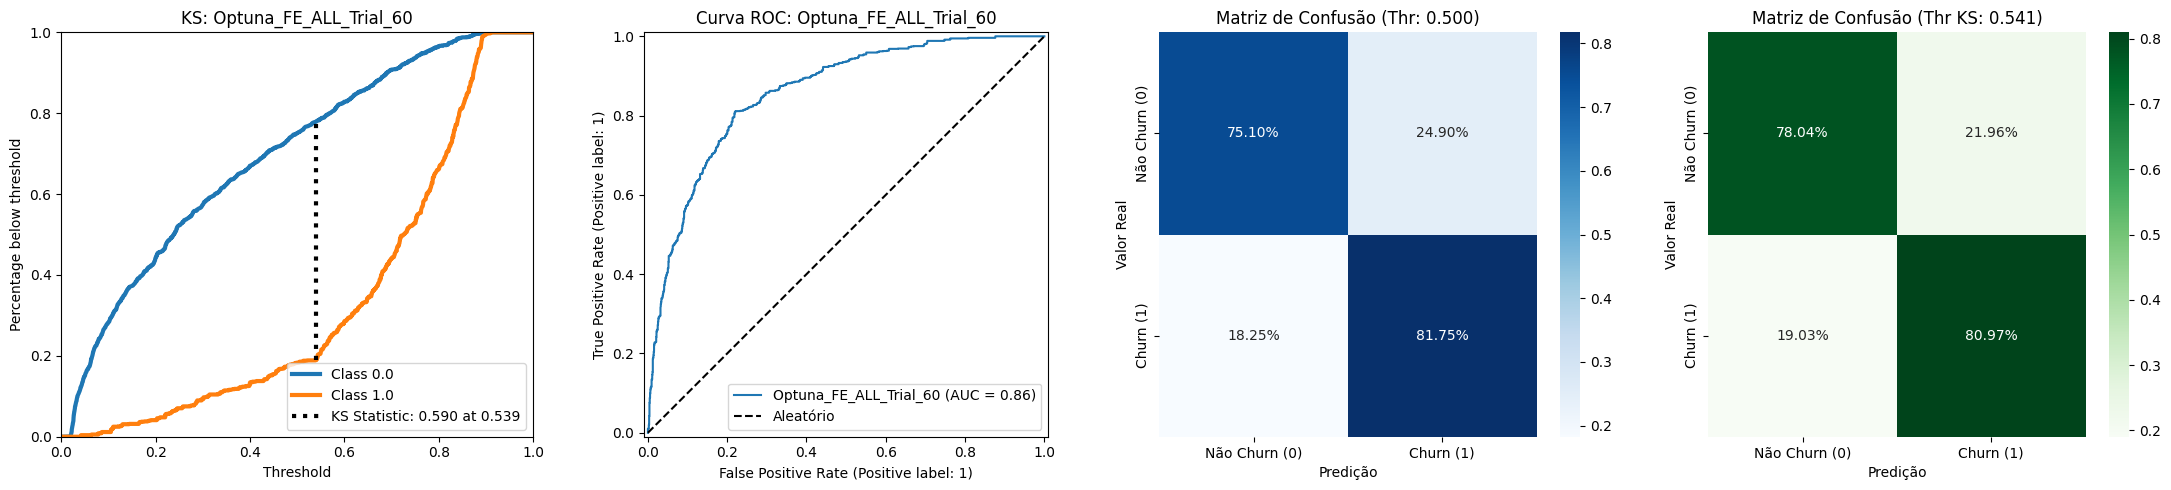

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5901 | AUROC: 0.8573 | Acurácia: 0.7842
Precisão: 0.7665 | Recall: 0.8175 | F1-Score: 0.7912

Relatório de Classificação (Threshold Padrão):
               precision    recall  f1-score   support

Não Churn (0)       0.80      0.75      0.78      1293
    Churn (1)       0.77      0.82      0.79      1293

     accuracy                           0.78      2586
    macro avg       0.79      0.78      0.78      2586
 weighted avg       0.79      0.78      0.78      2586


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.541) ---
KS: 0.5901 | AUROC: 0.8573 | Acurácia: 0.7951
Precisão: 0.7866 | Recall: 0.8097 | F1-Score: 0.7980

Relatório de Classificação (Threshold Otimizado):
               precision    recall  f1-score   support

Não Churn (0)       0.80      0.78      0.79      1293
    Churn (1)       0.79      0.81      0.80      1293

     accuracy                           0.80      2586
    macro avg       0.80      0.80      0.80

In [ ]:
# Otimização Optuna e Avaliação do Vencedor para Todas as Features (FE_ALL)
study_all = rodar_optuna_e_avaliar(
    nome_estudo="Otimizacao_MLP_FE_ALL",
    X_train=X_train_all,
    y_train=y_train_all,
    X_val=X_val_all,
    y_val=y_val_all,
    prefixo_trial="Optuna_FE_ALL_Trial"
)

## Ranking Final: Seleção do Modelo Definitivo
Aqui nós consolidamos todos os estudos realizados para comparar qual foi o Grande Campeão entre o modelo Base e todas as estratégias de Feature Engineering.

In [ ]:
import pandas as pd
import optuna
import os

def consolidar_resultados_optuna(caminho_logs):
    # Lista dos experimentos do Optuna: (Nome Amigável, Nome do Estudo, Nome do Arquivo DB)
    estudos = [
        ("Base (Sem FE)", "Otimizacao_MLP", "optuna_churn_study.db"),
        ("FE 1 (Qtde Serviços)", "Otimizacao_MLP_FE1", "otimizacao_mlp_fe1.db"),
        ("FE 2 (Tenure Binning)", "Otimizacao_MLP_FE2", "otimizacao_mlp_fe2.db"),
        ("FE 3 (Proporção Gasto)", "Otimizacao_MLP_FE3", "otimizacao_mlp_fe3.db"),
        ("FE 4 (Família)", "Otimizacao_MLP_FE4", "otimizacao_mlp_fe4.db"),
        ("FE ALL (Todas as FEs)", "Otimizacao_MLP_FE_ALL", "otimizacao_mlp_fe_all.db")
    ]

    # Lista de arquiteturas para mapeamento do Optuna
    arquiteturas_optuna = [
        [10], [16], [32], [64],
        [16, 8], [32, 16], [64, 32],
        [32, 16, 8], [64, 32, 16]
    ]

    resultados = []

    # 1. Carrega o campeão dos testes Manuais (Rodada 8)
    try:
        caminho_csv_r8 = os.path.join(caminho_logs, "rodada_8_loss.csv")
        if os.path.exists(caminho_csv_r8):
            df_r8 = pd.read_csv(caminho_csv_r8)
            melhor_linha_r8 = df_r8.loc[df_r8['val_ks'].idxmax()]

            linha_r8 = {
                "Experimento": "Manual Campeão (Rodada 8)",
                "Melhor KS": melhor_linha_r8['val_ks'],
                "Trial ID Vencedor": melhor_linha_r8['nome']
            }

            # Pegamos os parâmetros do CSV e adicionamos ao dicionário unificando em 'hidden_layers'
            params_r8 = {
                "learning_rate": melhor_linha_r8['learning_rate'],
                "dropout_rate": melhor_linha_r8['dropout_rate'],
                "weight_decay": melhor_linha_r8['weight_decay'],
                "optimizer_name": melhor_linha_r8['optimizer_name'],
                "batch_size": melhor_linha_r8['batch_size'],
                "loss_name": melhor_linha_r8['loss_name'],
                "activation_function": melhor_linha_r8['activation_function'],
                "hidden_layers": melhor_linha_r8['hidden_layers']
            }
            linha_r8.update(params_r8)
            resultados.append(linha_r8)
    except Exception as e:
        print(f"Aviso: Não foi possível carregar o estudo Manual da Rodada 8 - {e}")

    # 2. Carrega os estudos do Optuna
    for nome_amigavel, nome_estudo, arquivo_db in estudos:
        caminho_banco = f"sqlite:///{caminho_logs}/{arquivo_db}"
        try:
            # Carrega o estudo salvo no banco
            study = optuna.load_study(study_name=nome_estudo, storage=caminho_banco)
            best_trial = study.best_trial

            # Informações principais
            linha = {
                "Experimento": nome_amigavel,
                "Melhor KS": best_trial.value,
                "Trial ID Vencedor": best_trial.number
            }

            # Copia os parâmetros para manipular o dicionário
            params = best_trial.params.copy()

            # Substitui o 'arquitetura_idx' pelo valor real da lista em 'hidden_layers'
            if 'arquitetura_idx' in params:
                idx = params.pop('arquitetura_idx')
                params['hidden_layers'] = str(arquiteturas_optuna[idx])

            linha.update(params)
            resultados.append(linha)
        except Exception as e:
            print(f"Aviso: Não foi possível carregar o estudo '{nome_estudo}' - {e}")

    # Cria o DataFrame consolidado
    df_ranking = pd.DataFrame(resultados)

    if not df_ranking.empty:
        # Ordenar do maior KS para o menor para formar o ranking
        df_ranking = df_ranking.sort_values(by="Melhor KS", ascending=False).reset_index(drop=True)

        # Salva o log final na pasta do Drive
        caminho_csv = os.path.join(caminho_logs, "ranking_final_modelos.csv")
        df_ranking.to_csv(caminho_csv, index=False)
        print(f"Ranking consolidado salvo com sucesso em: {caminho_csv}\n")

    return df_ranking

# Gerar e exibir o ranking
df_ranking_final = consolidar_resultados_optuna(caminho_logs)

print("=== PÓDIO DOS MODELOS ===")
display(df_ranking_final.head(10))

Ranking consolidado salvo com sucesso em: /content/drive/MyDrive/Projeto_Churn_RN/logs/MLP/ranking_final_modelos.csv

=== PÓDIO DOS MODELOS ===


,Experimento,Melhor KS,Trial ID Vencedor,learning_rate,dropout_rate,weight_decay,optimizer_name,batch_size,loss_name,activation_function,hidden_layers
0,FE 2 (Tenure Binning),0.592421,58,0.002859,0.407836,0.000156,Adam,64,MSE,ReLU,[16]
1,FE ALL (Todas as FEs),0.590101,60,0.036691,0.346487,0.000600,Adam,128,CrossEntropy,Sigmoid,[64]
2,Base (Sem FE),0.587780,30,0.000378,0.056946,0.000048,Adadelta,64,MSE,LeakyReLU,[10]
3,FE 3 (Proporção Gasto),0.584687,3,0.015382,0.385635,0.000014,RMSprop,64,MSE,Tanh,[64]
4,FE 1 (Qtde Serviços),0.583913,42,0.000278,0.491263,0.000137,RMSprop,256,MSE,Tanh,"[32, 16, 8]"
5,Manual Campeão (Rodada 8),0.583140,MLP_Loss_1,0.000100,0.000000,0.000010,Adam,32,CrossEntropy,LeakyReLU,[16]
6,FE 4 (Família),0.583140,69,0.000377,0.209930,0.000013,RMSprop,256,MSE,Tanh,"[32, 16]"


# Avaliação Final no Conjunto de Teste
Agora vamos pegar o primeiro colocado do nosso ranking, carregar os pesos da rede e avaliar seu poder de predição nos dados de teste (`X_test` e `y_test`).

In [ ]:
import ast
import torch.nn as nn
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, RocCurveDisplay
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import TensorDataset, DataLoader
import torch
import scikitplot as skplt

# 1. Pega as informações do Melhor Modelo Geral
melhor_modelo_info = df_ranking_final.iloc[0]
experimento_campeao = melhor_modelo_info['Experimento']
trial_id = melhor_modelo_info['Trial ID Vencedor']

# 2. Dicionário para mapear qual Experimento usa qual Dataset de Teste/Validação e qual o prefixo do arquivo salvo
mapa_experimentos = {
    "Manual Campeão (Rodada 8)": {"X_test": X_test_final, "y_test": y_test, "X_val": X_val_final, "y_val": y_val, "prefixo": ""},
    "Base (Sem FE)": {"X_test": X_test_final, "y_test": y_test, "X_val": X_val_final, "y_val": y_val, "prefixo": "Optuna_Trial_"},
    "FE 1 (Qtde Serviços)": {"X_test": X_test_fe1, "y_test": y_test_fe1, "X_val": X_val_fe1, "y_val": y_val_fe1, "prefixo": "Optuna_FE1_Trial_"},
    "FE 2 (Tenure Binning)": {"X_test": X_test_fe2, "y_test": y_test_fe2, "X_val": X_val_fe2, "y_val": y_val_fe2, "prefixo": "Optuna_FE2_Trial_"},
    "FE 3 (Proporção Gasto)": {"X_test": X_test_fe3, "y_test": y_test_fe3, "X_val": X_val_fe3, "y_val": y_val_fe3, "prefixo": "Optuna_FE3_Trial_"},
    "FE 4 (Família)": {"X_test": X_test_fe4, "y_test": y_test_fe4, "X_val": X_val_fe4, "y_val": y_val_fe4, "prefixo": "Optuna_FE4_Trial_"},
    "FE ALL (Todas as FEs)": {"X_test": X_test_all, "y_test": y_test_all, "X_val": X_val_all, "y_val": y_val_all, "prefixo": "Optuna_FE_ALL_Trial_"}
}

# Obtém as configurações do vencedor
config_vencedor = mapa_experimentos[experimento_campeao]
X_test_campeao = config_vencedor["X_test"]
y_test_campeao = config_vencedor["y_test"]
X_val_campeao = config_vencedor["X_val"]
y_val_campeao = config_vencedor["y_val"]

# Monta o nome exato do experimento para a função de plotagem carregar o .pth correto
if isinstance(trial_id, int) or str(trial_id).isdigit():
    nome_modelo_salvo = f"{config_vencedor['prefixo']}{trial_id}"
else:
    nome_modelo_salvo = str(trial_id)

print(f"O CAMPEÃO GERAL FOI O EXPERIMENTO: '{experimento_campeao}'")
print(f"Carregando modelo: {nome_modelo_salvo}.pth")

# 3. Extrai os parâmetros estruturais do vencedor
hidden_layers_str = melhor_modelo_info['hidden_layers']
if isinstance(hidden_layers_str, str):
    hidden_layers_campeao = ast.literal_eval(hidden_layers_str)
else:
    hidden_layers_campeao = hidden_layers_str

ativacao_str = melhor_modelo_info['activation_function']
if ativacao_str == "ReLU":
    ativacao_campeao = nn.ReLU
elif ativacao_str == "Tanh":
    ativacao_campeao = nn.Tanh
elif ativacao_str == "Sigmoid":
    ativacao_campeao = nn.Sigmoid
else:
    ativacao_campeao = nn.LeakyReLU

# 4. Formata o dicionário
resultado_teste_campeao = {
    'nome': nome_modelo_salvo,
    'val_ks': melhor_modelo_info['Melhor KS'],
    'hidden_layers': hidden_layers_campeao,
    'batch_size': int(melhor_modelo_info['batch_size']),
    'dropout_rate': float(melhor_modelo_info['dropout_rate'])
}

print("\n" + "*"*60)
print("AVALIAÇÃO DEFINITIVA NO CONJUNTO DE TESTE (UNSEEN DATA)")
print("*"*60)

# Carregando os pesos do modelo campeão
caminho_arquivo = os.path.join(caminho_modelos, f"{nome_modelo_salvo}.pth")
modelo = MLP_Churn(X_test_campeao.shape[1], hidden_layers_campeao, ativacao_campeao, resultado_teste_campeao['dropout_rate'])
modelo.load_state_dict(torch.load(caminho_arquivo, map_location=device))
modelo.to(device).eval()

# ---------------------------------------------------------
# 5. Obtendo o Threshold ótimo usando APENAS a VALIDAÇÃO
# ---------------------------------------------------------
val_dataset = TensorDataset(torch.tensor(X_val_campeao.values, dtype=torch.float32),
                             torch.tensor(y_val_campeao.values, dtype=torch.float32).view(-1, 1))
val_loader = DataLoader(val_dataset, batch_size=resultado_teste_campeao['batch_size'], shuffle=False)

probs_val_list, labels_val_list = [], []
with torch.no_grad():
    for features, labels in val_loader:
        features, labels = features.to(device), labels.to(device)
        probs = torch.sigmoid(modelo(features))
        probs_val_list.extend(probs.cpu().numpy())
        labels_val_list.extend(labels.cpu().numpy())

y_true_val = np.array(labels_val_list).flatten()
probs_1_val = np.array(probs_val_list).flatten()

scores_val = get_scores_churn(y_true_val, probs_1_val)
optimal_thresh = scores_val['optimal_threshold']
print(f"Threshold ótimo obtido via Validação: {optimal_thresh:.3f}\n")

# ---------------------------------------------------------
# 6. Avalia no conjunto de Teste
# ---------------------------------------------------------
test_dataset = TensorDataset(torch.tensor(X_test_campeao.values, dtype=torch.float32),
                             torch.tensor(y_test_campeao.values, dtype=torch.float32).view(-1, 1))
test_loader = DataLoader(test_dataset, batch_size=resultado_teste_campeao['batch_size'], shuffle=False)

probs_list, labels_list = [], []
with torch.no_grad():
    for features, labels in test_loader:
        features, labels = features.to(device), labels.to(device)
        probs = torch.sigmoid(modelo(features))
        probs_list.extend(probs.cpu().numpy())
        labels_list.extend(labels.cpu().numpy())

y_true_test = np.array(labels_list).flatten()
probs_1_test = np.array(probs_list).flatten()
probs_0_test = 1 - probs_1_test
y_pred_scores = np.column_stack((probs_0_test, probs_1_test))

scores_default_test = get_scores_churn(y_true_test, probs_1_test, threshold=0.5)
scores_optimal_test = get_scores_churn(y_true_test, probs_1_test, threshold=optimal_thresh)

# Predições finais
y_pred_default = (probs_1_test >= 0.5).astype(int)
y_pred_otimizado = (probs_1_test >= optimal_thresh).astype(int)

# --- PRINT DOS RELATÓRIOS ---
print(f"--- MÉTRICAS NO TESTE COM THRESHOLD PADRÃO (0.500) ---")
print(f"KS: {scores_default_test['ks_stat']:.4f} | AUROC: {scores_default_test['roc_auc']:.4f} | Acurácia: {scores_default_test['accuracy']:.4f}")
print(f"Precisão: {scores_default_test['precision']:.4f} | Recall: {scores_default_test['recall']:.4f} | F1-Score: {scores_default_test['f1_score']:.4f}\n")
print(classification_report(y_true_test, y_pred_default, target_names=['Não Churn (0)', 'Churn (1)']))

print(f"\n--- MÉTRICAS NO TESTE COM THRESHOLD OTIMIZADO ({optimal_thresh:.3f}) ---")
print(f"KS: {scores_optimal_test['ks_stat']:.4f} | AUROC: {scores_optimal_test['roc_auc']:.4f} | Acurácia: {scores_optimal_test['accuracy']:.4f}")
print(f"Precisão: {scores_optimal_test['precision']:.4f} | Recall: {scores_optimal_test['recall']:.4f} | F1-Score: {scores_optimal_test['f1_score']:.4f}\n")
print(classification_report(y_true_test, y_pred_otimizado, target_names=['Não Churn (0)', 'Churn (1)']))

# --- PLOTAGEM DOS GRÁFICOS E MATRIZES EM PORCENTAGEM (estilo padrão) ---
fig, axes = plt.subplots(1, 4, figsize=(22, 5))

# 1. KS Plot
skplt.metrics.plot_ks_statistic(y_true_test, y_pred_scores, ax=axes[0], title=f"KS: {nome_modelo_salvo} (Teste)")

# 2. ROC Curve
RocCurveDisplay.from_predictions(y_true_test, probs_1_test, ax=axes[1], name=nome_modelo_salvo)
axes[1].set_title(f"Curva ROC (Teste)")
axes[1].plot([0, 1], [0, 1], 'k--', label='Aleatório')
axes[1].legend()

# 3. Matriz de Confusão Normalizada (0.5)
cm_norm_default = confusion_matrix(y_true_test, y_pred_default, normalize='true')
sns.heatmap(cm_norm_default, annot=True, fmt=".2%", cmap="Blues", ax=axes[2],
            xticklabels=['Não Churn (0)', 'Churn (1)'],
            yticklabels=['Não Churn (0)', 'Churn (1)'])
axes[2].set_title("Matriz de Confusão % (Thr: 0.500)")
axes[2].set_ylabel("Valor Real")
axes[2].set_xlabel("Predição")

# 4. Matriz de Confusão Normalizada (KS Ótimo)
cm_norm_optimal = confusion_matrix(y_true_test, y_pred_otimizado, normalize='true')
sns.heatmap(cm_norm_optimal, annot=True, fmt=".2%", cmap="Greens", ax=axes[3],
            xticklabels=['Não Churn (0)', 'Churn (1)'],
            yticklabels=['Não Churn (0)', 'Churn (1)'])
axes[3].set_title(f"Matriz de Confusão % (Thr KS: {optimal_thresh:.3f})")
axes[3].set_ylabel("Valor Real")
axes[3].set_xlabel("Predição")

plt.tight_layout()
plt.show()

# --- PLOTAGEM DAS MATRIZES ABSOLUTAS ---
cm_abs_default = confusion_matrix(y_true_test, y_pred_default)
cm_abs_optimal = confusion_matrix(y_true_test, y_pred_otimizado)

fig2, axes2 = plt.subplots(1, 2, figsize=(12, 5))

# Absoluta (0.500)
sns.heatmap(cm_abs_default, annot=True, fmt="d", cmap="Blues", ax=axes2[0],
            xticklabels=['Não Churn (0)', 'Churn (1)'],
            yticklabels=['Não Churn (0)', 'Churn (1)'])
axes2[0].set_title("Matriz de Confusão Absoluta (Thr: 0.500)")
axes2[0].set_ylabel("Valor Real")
axes2[0].set_xlabel("Predição")

# Absoluta (Threshold Otimizado)
sns.heatmap(cm_abs_optimal, annot=True, fmt="d", cmap="Oranges", ax=axes2[1],
            xticklabels=['Não Churn (0)', 'Churn (1)'],
            yticklabels=['Não Churn (0)', 'Churn (1)'])
axes2[1].set_title(f"Matriz de Confusão Absoluta (Thr KS: {optimal_thresh:.3f})")
axes2[1].set_ylabel("Valor Real")
axes2[1].set_xlabel("Predição")

plt.tight_layout()
plt.show()